## V407 Cyg Spectral Index plot

In [30]:
#imports
import math
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline


from astropy.io import ascii
import astropy.units as u
import astropy.constants as const
from astropy.modeling.powerlaws import BrokenPowerLaw1D, SmoothlyBrokenPowerLaw1D, PowerLaw1D
from astropy.modeling import fitting, models
from scipy.stats import chisquare as CHI

### First to import/ set up all the data in a bulk dataframe

In [31]:
data = (
    [55284.8,    2.0,  1.5, -0.124,  0.720,  0.000,  0.050], #'AL733',   'D *non detection']
    [55289.7,    3.0,  1.4,  2.980,  0.500,  0.000,  0.050], #'AS1039',	'D']
    [55298.7,    5.0,  1.4,  4.040,  0.300,  0.000,  0.050], #'AS1039',	'D']
    [55301.7,    6.0,  1.4,  3.597,  0.330,  0.000,  0.050], #'AS1039',	'D']
    [55304.7 ,   7.0 , 1.4,  4.780,  0.300,  0.000,  0.050], #'AS1039',	'D]
    [55308.7  ,  8.0  ,1.4,  5.482,  0.300,  0.000,  0.050], #'AS1039',	'D']
    [55311.7  ,  9.0 , 1.4,  5.780,  0.320,  0.000,  0.050], #'AS1039',	'D']
    [55315.6,   10.0  ,1.4,  5.944, 0.260,  0.000,  0.050], #'AS1039',	'D']
    [55318.6,   11.0  ,1.4,  5.760, 0.280,  0.000,  0.050], #'AS1039',	'D']
    [55323.6,   12.0  ,1.4,  6.441,  0.300,  0.000,  0.050], #'AS1039',	'D']
    [55330.5 ,  13.0  ,1.4,  5.355,  0.280,  0.000,  0.050], #'AS1039',	'D']
    [55332.6 ,  14.0  ,1.4,  5.803,  0.280,  0.000,  0.050], #'AS1039',	'D']	
    [55341.6 ,  15.0  ,1.4,  5.853,  0.300,  0.000,  0.050], #'AS1039',	'D']
    [55345.6 ,  16.0  ,1.4,  5.828,  0.290,  0.000,  0.050], #'AS1039',	'D']
    [55362.5 ,  17.0,	1.4,  5.606,  0.260,  0.000,  0.050], #'AS1039',	'D']
    [55367.6,	  18.0,	1.4,  5.763,  0.330,  0.000,  0.050], #'AS1039',	'D']
    [55368.5,	  19.0,	1.4,  5.905,  0.290,  0.000,  0.050], #'AS1039',	'D']
    [55404.4 ,  20.0,  1.4,  6.917,  0.280,  0.000,  0.050], #'10B-233', 'D']
    [55419.4,	  21.0,	1.4,  7.924,  0.330,  0.000,  0.050],	#'10B-233', 'D']
    [55434.3,	  22.0,	1.4,  5.489,  0.260,  0.000,  0.050], #'10B-233', 'D']
    [55449.2,	  23.0, 	1.4,  5.608,  0.240,  0.000,  0.050], #'10B-233', 'D']
    [55469.2,	  24.0,	1.4,  5.582,  0.145,  0.000,  0.050], #'10B-233', 'DnC']
    [55625.4 ,  25.0 , 1.3,  4.220,  0.163,  0.000,  0.050], #'11A-254', 'B']
    [55735.4 ,  26.0,  1.3,  3.596,  0.081,  0.000,  0.050], #'11A-254', 'A']
    [55869.1 ,  27.0,  1.3,  3.642,  0.534,  0.000,  0.050], #'11B-170', 'D']
    [55934.8 ,  28.0,  1.3,  4.688,  1.020,  0.000,  0.050], #'11B-170', 'DnC *held width constant']
    [56035.4 ,  29.0,  1.3,  2.940,  0.301,  0.000,  0.050], #'11B-170', 'C']

    [55284.8,    2.0,  1.9,  1.930,  0.525,  0.000,  0.050],  #held width constant
    [55289.7,    3.0,  1.8,  3.469,  0.350,  0.000,  0.050],
    [55298.7,    5.0,  1.8,  4.762,  0.300,  0.000,  0.050],
    [55301.7,    6.0,  1.8,  5.466,  0.300,  0.000,  0.050],
    [55304.7,    7.0,  1.8,  5.512,  0.350,  0.000,  0.050],
    [55308.7,    8.0,  1.8,  6.662,  0.330,  0.000,  0.050],
    [55311.7,    9.0,  1.8,  6.841,  0.300,  0.000,  0.050],
    [55315.6,   10.0,  1.8,  7.376,  0.290,  0.000,  0.050],
    [55318.6 ,  11.0,  1.8,  7.478,  0.260,  0.000,  0.050],
    [55323.6,   12.0,  1.8,  7.657,  0.330,  0.000,  0.050],
    [55330.5,   13.0,  1.8,  6.651,  0.270,  0.000,  0.050],
    [55332.6,   14.0,  1.8,  7.574,  0.260,  0.000,  0.050],
    [55341.6,   15.0,  1.8,  8.049,  0.260,  0.000,  0.050],
    [55345.6,   16.0,  1.8,  7.532,  0.280,  0.000 , 0.050],
    [55362.5,   17.0,	1.8,  7.540,  0.240,  0.000,  0.050],
    [55367.6,	  18.0,  1.8,  7.811,  0.290,  0.000,  0.050],
    [55368.5,	  19.0,  1.8,  7.381,  0.260,  0.000,  0.050],
    [55404.4 ,  20.0,  1.8 , 8.225,  0.300,  0.000,  0.050],
    [55419.4,	  21.0,	1.8,  8.192 , 0.200,  0.000,  0.050],
    [55434.3,	  22.0,	1.8,  6.386,  0.240,  0.000,  0.050],
    [55449.2,	  23.0, 	1.8,  6.338,  0.160,  0.000,  0.050],
    [55469.2,	  24.0,	1.8,  5.532,  0.135,  0.000,  0.050],
    [55625.4,   25.0,  1.8,  4.644,  0.092,  0.000 , 0.050],
    [55735.4,   26.0,  1.8,  4.074,  0.068,  0.000,  0.050],
    [55869.1 ,  27.0,  1.8,  3.855,  0.291,  0.000,  0.050],
    [55934.8,   28.0,  1.8,  3.316,  0.554,  0.000,  0.050], #held width constant
    [56035.4,   29.0,  1.8,  3.347,  0.232,  0.000,  0.050],

    [55282.9,    1.0,  5.0,  6.389,  0.000,  0.150,  0.050],
    [55284.8,    2.0,  5.0,  7.034,  0.000,  0.104,  0.050],
    [55289.7,    3.0,  4.8,  6.880,  0.000,  0.130,  0.050],
    [55294.7,    4.0,  4.8,  8.990,  0.000,  0.130,  0.050],
    [55298.7,    5.0,  4.8, 10.680,  0.000,  0.110,  0.050],
    [55301.7,    6.0,  4.8, 12.363,  0.182,  0.051,  0.050],
    [55304.7,    7.0,  4.8, 12.792,  0.167,  0.039,  0.050],
    [55308.7,    8.0,  4.8, 13.690,  0.171,  0.034,  0.050],
    [55311.6,    9.0,  4.8, 13.964,  0.078,  0.014,  0.050],
    [55315.6,   10.0,  4.8, 13.673,  0.107,  0.027,  0.050],
    [55318.6,   11.0,  4.8, 13.135,  0.130,  0.028,  0.050],
    [55323.6,   12.0,  4.8, 14.160,  0.088,  0.016,  0.050],
    [55330.5,   13.0,  4.8, 15.023,  0.082,  0.023,  0.050],
    [55332.6,   14.0,  4.8, 15.479,  0.000,  0.155,  0.050],
    [55341.6,   15.0,  4.8, 17.395,  0.092,  0.032,  0.050],
    [55345.6,   16.0,  4.8, 17.465,  0.000,  0.165,  0.050],
    [55362.5,   17.0,  4.8, 17.255,  0.061,  0.016,  0.050],
    [55367.6,	  18.0,	4.8, 17.777,  0.145,  0.032,  0.050],	
    [55368.5,	  19.0,	4.8, 17.446,  0.000,  0.135,  0.050],
    [55404.4,   20.0,  4.8, 12.926,  0.083,  0.022,  0.050],
    [55419.3,	  21.0,	4.8, 11.805,  0.118,  0.018,  0.050],
    [55434.3,	  22.0,	4.8, 10.785,  0.100,  0.018,  0.050],
    [55449.2,	  23.0,  4.8,  9.979,  0.115,  0.024,  0.050],
    [55469.2,	  24.0,	4.8,  9.173,  0.074,  0.000,  0.050],
    [55625.4,   25.0,  5.0,  5.003,  0.000,  0.027,  0.050],
    [55735.4,   26.0,  5.0,  3.270,  0.000,  0.029,  0.050],
    [55869.1,   27.0,  5.0,  3.542,  0.000,  0.036,  0.050],
    [55934.8,   28.0,  5.0,  3.212,  0.055,  0.000,  0.050],
    [56035.4,   29.0,  5.0,  2.913,  0.028,  0.000,  0.050],

    #[55277.5   -2.0  8.4  8.500  0.000  0.800  0.200]  #from Effelsberg, ATel 2506
    #[55282.5   -1.0  6.4  8.900  0.000  1.000  0.200]  #from ATA, Atel 2529
    [55289.7,    3.0,  7.0,  8.810,  0.000,  0.110,  0.050],
    [55294.7,    4.0,  7.0, 11.880,  0.000,  0.080,  0.050],
    [55298.7,    5.0,  7.0, 12.870,  0.000,  0.140,  0.050],
    [55301.7,    6.0,  7.0, 14.670,  0.111,  0.032,  0.050],
    [55304.7,    7.0,  7.0, 15.586,  0.145,  0.050,  0.050],
    [55308.7,    8.0,  7.0, 15.718,  0.108,  0.037,  0.050],
    [55311.6,    9.0,  7.0, 16.072,  0.071,  0.029,  0.050],
    [55315.6,   10.0,  7.0, 16.882,  0.087,  0.038,  0.050],
    [55318.6,   11.0,  7.0, 16.103,  0.089,  0.036,  0.050],
    [55323.6,   12.0,  7.0, 17.178,  0.055,  0.019,  0.050],
    [55330.5,   13.0,  7.9, 19.175,  0.056,  0.013,  0.050],
    [55332.6,   14.0,  7.9, 19.876,  0.000,  0.133,  0.050],
    [55341.6,   15.0,  7.9, 21.710,  0.080,  0.030,  0.050],
    [55345.6,   16.0,  7.9, 20.618,  0.000,  0.154,  0.050],
    [55362.5,   17.0,  7.9, 20.190,  0.065,  0.009,  0.050],
    [55367.6,	  18.0,	7.9, 19.022,  0.068,  0.015,  0.050],	
    [55368.5,	  19.0,	7.9, 18.301,  0.000,  0.182,  0.050],
    [55404.4,   20.0,  7.9, 14.569,  0.082,  0.017,  0.050],
    [55419.3,	  21.0,	7.9, 12.923,  0.069,  0.013,  0.050],
    [55434.3,	  22.0,	7.9, 11.313,  0.041,  0.009,  0.050],
    [55449.2,	  23.0,	7.9, 10.158,  0.066,  0.012,  0.050],
    [55469.2,	  24.0,	7.9,  9.102,  0.062,  0.000,  0.050],
    [55625.4,   25.0,  7.4,  4.813,  0.000,  0.023,  0.050],
    [55735.4,   26.0,  7.4,  2.752,  0.000,  0.033,  0.050], 
    [55869.1,   27.0,  7.4,  3.494,  0.000,  0.029,  0.050],
    [55934.8,   28.0,  7.4,  3.154,  0.025,  0.000,  0.050],
    [56035.4,   29.0,  7.4, 2.803,  0.020,  0.000,  0.050],

    [55289.7,    3.0, 19.0, 20.486,  0.075,  0.004,  0.100],
    [55294.6,    4.0, 19.0, 23.654,  0.056,  0.003,  0.100],
    [55298.6,    5.0, 19.0, 29.126,  0.069,  0.005,  0.100],
    [55301.6,    6.0, 19.0, 30.900,  0.084,  0.006,  0.100],
    [55304.7,    7.0, 19.0, 29.153,  0.114,  0.018,  0.100],
    [55308.6,    8.0, 19.0, 28.913,  0.246,  0.016,  0.100],
    [55311.6,    9.0, 19.0, 30.382,  0.072,  0.011,  0.100],
    [55315.6,   10.0, 19.0, 33.032,  0.095,  0.011,  0.100],
    [55318.6,   11.0, 19.0, 29.067,  0.108,  0.018,  0.100],
    [55323.6,   12.0, 19.0, 27.774,  0.079,  0.014,  0.100],
    [55327.6,   13.0, 19.0, 28.251,  0.073,  0.010,  0.100],
    [55332.5,   14.0, 19.0, 28.752,  0.089,  0.012,  0.100],
    [55341.5,	  15.0, 19.0, 28.360,  0.082,  0.013,  0.100],
    [55345.5,   16.0, 19.0, 26.717,  0.074,  0.016,  0.100],
    [55368.5,	  19.0, 19.0, 23.036,  0.106,  0.013,  0.100],
    [55404.3,   20.0, 19.0, 14.867,  0.137,  0.013,  0.100],
    [55419.4,	  21.0, 19.0, 13.256,  0.092,  0.008,  0.100],
    [55434.3,	  22.0, 19.0, 11.867,  0.089,  0.010,  0.100],
    [55449.3,	  23.0, 19.0, 10.008,  0.080,  0.011,  0.100],
    [55469.2,	  24.0, 19.0,  9.864,  0.066,  0.059,  0.100], 
    [55625.4,   25.0, 20.1,  4.652,  0.033,  0.000,  0.100],
    [55735.4,	  26.0, 20.1,  2.542,  0.040,  0.000,  0.100],
    [55869.1,   27.0, 20.1,  3.672,  0.000,  0.038,  0.100],
    [55934.8,   28.0, 20.1,  3.140,  0.047,  0.000,  0.100],
    [56035.4,   29.0, 20.1,  2.914,  0.040,  0.000,  0.100],

    [55289.7,    3.0, 25.0, 24.545,  0.055,  0.004,  0.100],
    [55294.6,    4.0, 25.0, 27.706,  0.065,  0.005,  0.100],
    [55298.6,    5.0, 25.0, 35.279,  0.054,  0.006,  0.100],
    [55301.6,    6.0, 25.0, 37.236,  0.074,  0.006,  0.100],
    [55304.7,    7.0, 25.0, 34.345,  0.193,  0.038,  0.100],
    [55308.6,    8.0, 25.0, 30.322,  0.323,  0.025,  0.100],
    [55311.6,    9.0, 25.0, 33.856,  0.053,  0.010,  0.100],
    [55315.6,   10.0, 25.0, 37.507,  0.070,  0.014,  0.100],
    [55318.6,   11.0, 25.0, 34.754,  0.079,  0.015,  0.100],
    [55323.6,   12.0, 25.0, 29.494,  0.060,  0.014,  0.100],
    [55327.6,   13.0, 25.0, 30.309,  0.081,  0.013,  0.100],
    [55332.5,   14.0, 25.0, 29.247,  0.062,  0.012,  0.100],
    [55341.5,	  15.0, 25.0, 28.799,  0.053,  0.011,  0.100],
    [55345.5,   16.0, 25.0, 27.507,  0.084,  0.015,  0.100],
    [55368.5,	  19.0, 25.0, 22.468,  0.062,  0.011,  0.100],
    [55404.3,   20.0, 25.0, 13.636,  0.105,  0.015,  0.100],
    [55419.4,	  21.0, 25.0, 13.297,  0.084,  0.013,  0.100],
    [55434.3,	  22.0, 25.0, 11.200,  0.055,  0.008,  0.100],
    [55449.3,	  23.0, 25.0,  9.506,  0.081,  0.020,  0.100],
    [55469.2,	  24.0, 25.0, 10.082,  0.068,  0.066,  0.100],
    [55625.4,   25.0, 25.6,  4.744,  0.033,  0.000,  0.100],
    [55735.4,	  26.0, 25.6,  2.620,  0.048,  0.000,  0.100],
    [55869.1,   27.0, 25.6,  3.828,  0.000,  0.047,  0.100],
    [55934.8,   28.0, 25.6,  2.992,  0.057,  0.000,  0.100],
    [56035.4,   29.0, 25.6,  2.970,  0.052,  0.000,  0.100],

    [55298.7,    5.0, 41.0, 59.890,  0.000, 0.890,  0.200],
    [55327.6,   13.0, 41.0, 51.340,  0.000,  0.750,  0.200],
    [55332.5,   14.0, 41.0, 44.900,  0.000,  0.620,  0.200],
    [55341.5,   15.0, 41.0, 39.970,  0.000,  0.560,  0.200],
    [55345.5,   16.0, 41.0, 37.050,  0.000,  0.570,  0.200],
    [55368.5,	  19.0, 41.0, 25.944,  0.000,  0.646,  0.200],
    [55404.3,	  20.0, 41.0, 18.670,  0.000,  0.831,  0.200],
    [55419.4,	  21.0, 41.0, 12.392,  0.000,  0.479,  0.200],
    [55434.3,	  22.0, 41.0, 14.580,  0.000,  0.586,  0.200],
    [55449.3,	  23.0, 41.0,  9.662,  0.000,  0.845,  0.200],
    [55469.2,	  24.0, 41.0, 14.189,  0.000,  0.640,  0.200],
    [55625.4,   25.0, 41.0,  5.303,  0.000,  0.181,  0.200],
    [55735.4,   26.0, 41.0,  4.249,  0.000,  0.171,  0.200],
    [55869.1,   27.0, 41.0,  4.323,  0.000,  0.124,  0.200],
    [55934.8,   28.0, 41.0,  3.959,  0.000,  0.232,  0.200],
    [56035.4,   29.0, 41.0,  2.879,  0.000,  0.165,  0.200],

    [55298.7,    5.0, 45.0, 65.630,  0.000,  1.160,  0.200],
    [55327.6,   13.0, 45.0, 50.660,  0.000,  0.750,  0.200],
    [55332.5,   14.0, 45.0, 46.310,  0.000,  0.620,  0.200],
    [55341.5,   15.0, 45.0, 38.400,  0.000,  0.640,  0.200],
    [55345.5,   16.0, 45.0, 35.880,  0.000,  0.600,  0.200],
    [55368.5,	  19.0, 45.0, 28.133,  0.000,  0.771,  0.200],
    [55404.3,	  20.0, 45.0, 18.608,  0.000,  0.972,  0.200],
    [55419.4,	  21.0, 45.0, 13.509,  0.000,  0.522,  0.200],
    [55434.3,	  22.0, 45.0, 15.120,  0.000,  0.595,  0.200],
    [55449.3,	  23.0, 45.0,  9.093,  0.000,  0.783,  0.200],
    [55469.2,	  24.0, 45.0, 12.754,  0.000,  0.689,  0.200],
    [55625.4,   25.0, 45.0,  5.445,  0.000,  0.238,  0.200],
    [55735.4,   26.0, 45.0,  4.445,  0.000,  0.237,  0.200],
    [55869.1,   27.0, 45.0,  4.466,  0.000,  0.162,  0.200],
    [55934.8,   28.0, 45.0,  5.225,  0.000,  0.373,  0.200],
    [56035.4,   29.0, 45.0,  2.660,  0.000,  0.247,  0.200],

    #[55289.7    3.0 49.0 44.980  0.000  1.590  0.500]
    #[55308.6    6.0 49.0 82.500  0.000  0.000  0.200] 


    [55277.5,   -1.0,  8.35, 8.500,  0.000,  0.800,  0.100], # ATel 2506
    [55277.5,   -1.0, 10.45, 11.60,  0.000,  0.900,  0.100], 
    [55277.5,   -1.0, 14.60, 14.60,  0.000,  1.200,  0.100], 
    [55277.5,   -1.0, 15.00, 24.10,  0.000,  1.700,  0.100],
    [55277.5,   -1.0, 142.0, 146.0,  0.000,  51.00,  0.100],
    )

df = pd.DataFrame(data, columns = ["MJD","Epoch","Freq","Flux","Error1 (gaussfit)","Error2 (image)","Error3 (calibration) (%)",])

### Now to seperate each dataset based off of days
#### Using the starting date as MJD 55265.8 for V407 Cyg (from "The radio light curve of the gamma-ray nova in V407 cyg: thermal emission from the ionized symbiotic evnelope, devoured from within by the nova blast" - December 20th 2012) 

In [32]:
#[55289.7    3.0 49.0 44.980  0.000  1.590  0.500]
#[55308.6    6.0 49.0 82.500  0.000  0.000  0.200] 
#[55277.5   -2.0  8.4  8.500  0.000  0.800  0.200]  #from Effelsberg, ATel 2506
#[55282.5   -1.0  6.4  8.900  0.000  1.000  0.200]  #from ATA, Atel 2529

E1 = ([55282.9,    1.0,  5.0,  6.389,  0.150,  0.050],)

E2 = (
    [55284.8,    2.0,  1.5, -0.124,  0.720,   0.050], #'AL733',   'D *non detection']
    [55284.8,    2.0,  1.9,  1.930,  0.525,  0.050],  #held width constant
    [55284.8,    2.0,  5.0,  7.034,   0.104,  0.050],)


E3 = ([55289.7,    3.0,  1.4,  2.980,  0.500,    0.050], #'AS1039',	'D']
    [55289.7,    3.0,  1.8,  3.469,  0.350,   0.050],
    [55289.7,    3.0,  4.8,  6.880,   0.130,  0.050],
    [55289.7,    3.0,  7.0,  8.810,    0.110,  0.050],
    [55289.7,    3.0, 19.0, 20.486,  0.075,   0.100],
    [55289.7,    3.0, 25.0, 24.545,  0.055,   0.100],)


E4= ([55294.6,    4.0, 25.0, 27.706,  0.065,   0.100],
     [55294.6,    4.0, 19.0, 23.654,  0.056,    0.100],
     [55294.7,    4.0,  7.0, 11.880,    0.080,  0.050],
     [55294.7,    4.0,  4.8,  8.990,  0.130,  0.050],
    )

E5 = ([55298.7,    5.0, 45.0, 65.630,    1.160,  0.200],
      [55298.7,    5.0, 41.0, 59.890,   0.890,  0.200],
      [55298.6,    5.0, 25.0, 35.279,  0.054,    0.100],
      [55298.6,    5.0, 19.0, 29.126,  0.069,   0.100],
      [55298.7,    5.0,  7.0, 12.870,    0.140,  0.050],
      [55298.7,    5.0,  4.8, 10.680,    0.110,  0.050],
      [55298.7,    5.0,  1.8,  4.762,  0.300,    0.050],
      [55298.7,    5.0,  1.4,  4.040,  0.300,    0.050], #'AS1039',	'D']
     )

E6 = ([55301.6,    6.0, 25.0, 37.236,  0.074,   0.100],
      [55301.6,    6.0, 19.0, 30.900,  0.084,    0.100],
      [55301.7,    6.0,  7.0, 14.670,  0.111,    0.050],
      [55301.7,    6.0,  4.8, 12.363,  0.182,   0.050],
      [55301.7,    6.0,  1.8,  5.466,  0.300,   0.050],
      [55301.7,    6.0,  1.4,  3.597,  0.330,   0.050], #'AS1039',	'D']
     )

E7 = ([55304.7,    7.0, 25.0, 34.345,  0.193,    0.100],
      [55304.7,    7.0, 19.0, 29.153,  0.114,   0.100],
      [55304.7,    7.0,  7.0, 15.586,  0.145,    0.050],
      [55304.7,    7.0,  4.8, 12.792,  0.167,    0.050],
      [55304.7,    7.0,  1.8,  5.512,  0.350,   0.050],
      [55304.7 ,   7.0 , 1.4,  4.780,  0.300,    0.050], #'AS1039',	'D]
     )

E8 = ([55308.6,    8.0, 25.0, 30.322,  0.323,  0.100],
      [55308.6,    8.0, 19.0, 28.913,  0.246,    0.100],
      [55308.7,    8.0,  7.0, 15.718,  0.108,    0.050],
      [55308.7,    8.0,  4.8, 13.690,  0.171,  0.050],
      [55308.7,    8.0,  1.8,  6.662,  0.330,    0.050],
      [55308.7  ,  8.0  ,1.4,  5.482,  0.300,    0.050], #'AS1039',	'D']
)

E9 = ([55311.6,    9.0, 25.0, 33.856,  0.053,    0.100],
      [55311.6,    9.0, 19.0, 30.382,  0.072,   0.100],
      [55311.6,    9.0,  7.0, 16.072,  0.071,  0.050],
      [55311.6,    9.0,  4.8, 13.964,  0.078,   0.050],
      [55311.7,    9.0,  1.8,  6.841,  0.300,  0.050],
      [55311.7  ,  9.0 , 1.4,  5.780,  0.320,   0.050], #'AS1039',	'D']
     )

E10 = ([55315.6,   10.0, 25.0, 37.507,  0.070,   0.100],
       [55315.6,   10.0, 19.0, 33.032,  0.095,    0.100],
        [55315.6,   10.0,  7.0, 16.882,  0.087,    0.050],
       [55315.6,   10.0,  4.8, 13.673,  0.107,  0.050],
       [55315.6,   10.0,  1.8,  7.376,  0.290,   0.050],
       [55315.6,   10.0  ,1.4,  5.944, 0.260,   0.050], #'AS1039',	'D']
      )

E11 = ([55318.6,   11.0, 25.0, 34.754,  0.079,    0.100],
      [55318.6,   11.0, 19.0, 29.067,  0.108,  0.100],
      [55318.6,   11.0,  7.0, 16.103,  0.089,    0.050],
       [55318.6,   11.0,  4.8, 13.135,  0.130,   0.050],
      [55318.6 ,  11.0,  1.8,  7.478,  0.260,   0.050],
      [55318.6,   11.0  ,1.4,  5.760, 0.280,    0.050], #'AS1039',	'D']
      )

E12 = ([55323.6,   12.0, 25.0, 29.494,  0.060,   0.100],
       [55323.6,   12.0, 19.0, 27.774,  0.079,    0.100],
       [55323.6,   12.0,  7.0, 17.178,  0.055,    0.050],
       [55323.6,   12.0,  4.8, 14.160,  0.088,    0.050],
       [55323.6,   12.0,  1.8,  7.657,  0.330,   0.050],
       [55323.6,   12.0  ,1.4,  6.441,  0.300,  0.050], #'AS1039',	'D']
      )

E13 = ( [55327.6,   13.0, 45.0, 50.660,    0.750,  0.200],
      [55327.6,   13.0, 41.0, 51.340,    0.750,  0.200],
       [55327.6,   13.0, 25.0, 30.309,  0.081,   0.100],
       [55327.6,   13.0, 19.0, 28.251,  0.073,   0.100],

       [55330.5,   13.0,  7.9, 19.175,  0.056,   0.050],
       [55330.5,   13.0,  4.8, 15.023,  0.082,  0.050],
       [55330.5,   13.0,  1.8,  6.651,  0.270,    0.050],
       [55330.5 ,  13.0  ,1.4,  5.355,  0.280,   0.050], #'AS1039',	'D']
      )

E14 = ( [55332.5,   14.0, 45.0, 46.310,    0.620,  0.200],
       [55332.5,   14.0, 41.0, 44.900,    0.620,  0.200],
       [55332.5,   14.0, 25.0, 29.247,  0.062,   0.100],
        [55332.5,   14.0, 19.0, 28.752,  0.089,    0.100],
       [55332.6,   14.0,  7.9, 19.876,    0.133,  0.050],
       [55332.6,   14.0,  4.8, 15.479,   0.155,  0.050],
       [55332.6,   14.0,  1.8,  7.574,  0.260,   0.050],
       [55332.6 ,  14.0  ,1.4,  5.803,  0.280,    0.050], #'AS1039',	'D']	
      )

E15 = ([55341.5,   15.0, 45.0, 38.400,    0.640,  0.200],
       [55341.5,   15.0, 41.0, 39.970,    0.560,  0.200],
       [55341.5,	  15.0, 25.0, 28.799,  0.053,  0.100],
       [55341.5,	  15.0, 19.0, 28.360,  0.082,    0.100],
       [55341.6,   15.0,  7.9, 21.710,  0.080,   0.050],
       [55341.6,   15.0,  4.8, 17.395,  0.092,   0.050],
       [55341.6,   15.0,  1.8,  8.049,  0.260,    0.050],
       [55341.6 ,  15.0  ,1.4,  5.853,  0.300,  0.050], #'AS1039',	'D']
      )

E16 = ([55345.5,   16.0, 45.0, 35.880,    0.600,  0.200],
       [55345.5,   16.0, 41.0, 37.050,   0.570,  0.200],
       [55345.5,   16.0, 25.0, 27.507,  0.084,    0.100],
       [55345.5,   16.0, 19.0, 26.717,  0.074,   0.100],
       [55345.6,   16.0,  7.9, 20.618,    0.154,  0.050],
       [55345.6,   16.0,  4.8, 17.465,    0.165,  0.050],
       [55345.6,   16.0,  1.8,  7.532,  0.280,   0.050],
       [55345.6 ,  16.0  ,1.4,  5.828,  0.290,   0.050], #'AS1039',	'D']
)

E17 = ([55362.5,   17.0,  7.9, 20.190,  0.065,   0.050],	
       [55362.5,   17.0,  4.8, 17.255,  0.061,    0.050],	
       [55362.5,   17.0,	1.8,  7.540,  0.240,   0.050],
       [55362.5 ,  17.0,	1.4,  5.606,  0.260,   0.050], #'AS1039',	'D']
      )

E18 = ([55367.6,	  18.0,	7.9, 19.022,  0.068,   0.050],
       [55367.6,	  18.0,	4.8, 17.777,  0.145,   0.050],
       [55367.6,	  18.0,  1.8,  7.811,  0.290,    0.050],
       [55367.6,	  18.0,	1.4,  5.763,  0.330,   0.050], #'AS1039',	'D']
      )

E19 = ([55368.5,	  19.0, 45.0, 28.133,    0.771,  0.200],
       [55368.5,	  19.0, 41.0, 25.944,   0.646,  0.200],
       [55368.5,	  19.0, 25.0, 22.468,  0.062,    0.100],
       [55368.5,	  19.0, 19.0, 23.036,  0.106,   0.100],
       [55368.5,	  19.0,	7.9, 18.301,   0.182,  0.050],
       [55368.5,	  19.0,	4.8, 17.446,   0.135,  0.050],
       [55368.5,	  19.0,  1.8,  7.381,  0.260,   0.050],
       [55368.5,	  19.0,	1.4,  5.905,  0.290,   0.050], #'AS1039',	'D']
      )

E20 = ([55404.3,	  20.0, 45.0, 18.608,    0.972,  0.200],
       [55404.3,	  20.0, 41.0, 18.670,    0.831,  0.200],
       [55404.3,   20.0, 25.0, 13.636,  0.105,    0.100],
       [55404.3,   20.0, 19.0, 14.867,  0.137,   0.100],
       [55404.4,   20.0,  7.9, 14.569,  0.082,   0.050],
       [55404.4,   20.0,  4.8, 12.926,  0.083,   0.050],
       [55404.4 ,  20.0,  1.8 , 8.225,  0.300,  0.050],
       [55404.4 ,  20.0,  1.4,  6.917,  0.280,   0.050], #'10B-233', 'D']
)

E21 = ([55419.4,	  21.0, 45.0, 13.509,    0.522,  0.200],
       [55419.4,	  21.0, 41.0, 12.392,  0.479,  0.200],
       [55419.4,	  21.0, 25.0, 13.297,  0.084,    0.100],
       [55419.4,	  21.0, 19.0, 13.256,  0.092,  0.100],
       [55419.3,	  21.0,	7.9, 12.923,  0.069,   0.050],
       [55419.3,	  21.0,	4.8, 11.805,  0.118,   0.050],
       [55419.4,	  21.0,	1.8,  8.192 , 0.200,    0.050],
       [55419.4,	  21.0,	1.4,  7.924,  0.330,   0.050],	#'10B-233', 'D']
)

E22 = ([55434.3,	  22.0, 45.0, 15.120,   0.595,  0.200],
       [55434.3,	  22.0, 41.0, 14.580,    0.586,  0.200],
       [55434.3,	  22.0, 25.0, 11.200,  0.055,   0.100],
       [55434.3,	  22.0, 19.0, 11.867,  0.089,    0.100],
       [55434.3,	  22.0,	7.9, 11.313,  0.041,    0.050],
       [55434.3,	  22.0,	4.8, 10.785,  0.100,    0.050],
       [55434.3,	  22.0,	1.8,  6.386,  0.240,   0.050],
       [55434.3,	  22.0,	1.4,  5.489,  0.260,    0.050], #'10B-233', 'D']
      )

E23 = ([55449.3,	  23.0, 45.0,  9.093,   0.783,  0.200],
       [55449.3,	  23.0, 41.0,  9.662,    0.845,  0.200],
       [55449.3,	  23.0, 25.0,  9.506,  0.081,    0.100],
       [55449.3,	  23.0, 19.0, 10.008,  0.080,    0.100],
       [55449.2,	  23.0,	7.9, 10.158,  0.066,    0.050],
       [55449.2,	  23.0,  4.8,  9.979,  0.115,    0.050],
       [55449.2,	  23.0, 	1.8,  6.338,  0.160,   0.050],
       [55449.2,	  23.0, 	1.4,  5.608,  0.240,    0.050], #'10B-233', 'D'] 
)

E24 = ([55469.2,	  24.0, 45.0, 12.754,    0.689,  0.200],
       [55469.2,	  24.0, 41.0, 14.189,   0.640,  0.200],
       [55469.2,	  24.0, 25.0, 10.082,  0.068,    0.100],
       [55469.2,	  24.0, 19.0,  9.864,  0.066,    0.100], 
       [55469.2,	  24.0,	7.9,  9.102,  0.062,  0.050],
       [55469.2,	  24.0,	4.8,  9.173,  0.074,    0.050],
       [55469.2,	  24.0,	1.8,  5.532,  0.135,    0.050],
       [55469.2,	  24.0,	1.4,  5.582,  0.145,   0.050], #'10B-233', 'DnC']
      )
    
E25 = ([55625.4,   25.0, 45.0,  5.445,    0.238,  0.200],
       [55625.4,   25.0, 41.0,  5.303,    0.181,  0.200],
       [55625.4,   25.0, 25.6,  4.744,  0.033,   0.100],
       [55625.4,   25.0, 20.1,  4.652,  0.033,    0.100],
       [55625.4,   25.0,  7.4,  4.813,    0.023,  0.050],
       [55625.4,   25.0,  5.0,  5.003,   0.027,  0.050],
       [55625.4,   25.0,  1.8,  4.644,  0.092,  0.050],
       [55625.4 ,  25.0 , 1.3,  4.220,  0.163,    0.050], #'11A-254', 'B']
      )
    
E26 = ([55735.4,   26.0, 45.0,  4.445,    0.237,  0.200],
       [55735.4,   26.0, 41.0,  4.249,    0.171,  0.200],
       [55735.4,	  26.0, 25.6,  2.620,  0.048,    0.100],
       [55735.4,	  26.0, 20.1,  2.542,  0.040,  0.100],
       [55735.4,   26.0,  7.4,  2.752,   0.033,  0.050], 
       [55735.4,   26.0,  5.0,  3.270,    0.029,  0.050],
       [55735.4,   26.0,  1.8,  4.074,  0.068,   0.050],
       [55735.4 ,  26.0,  1.3,  3.596,  0.081,    0.050], #'11A-254', 'A']
      )
    
E27 = ( [55869.1,   27.0, 45.0,  4.466,    0.162,  0.200],
       [55869.1,   27.0, 41.0,  4.323,    0.124,  0.200],
       [55869.1,   27.0, 25.6,  3.828,    0.047,  0.100],
       [55869.1,   27.0, 20.1,  3.672,    0.038,  0.100],
       [55869.1,   27.0,  7.4,  3.494,   0.029,  0.050],
       [55869.1,   27.0,  5.0,  3.542,    0.036,  0.050],
       [55869.1 ,  27.0,  1.8,  3.855,  0.291,    0.050],
       [55869.1 ,  27.0,  1.3,  3.642,  0.534,   0.050], #'11B-170', 'D']
      )
    
E28 = ([55934.8,   28.0, 45.0,  5.225,   0.373,  0.200],
        [55934.8,   28.0, 41.0,  3.959,    0.232,  0.200],
        [55934.8,   28.0, 25.6,  2.992,  0.057,    0.100],
        [55934.8,   28.0, 20.1,  3.140,  0.047,  0.100],
        [55934.8,   28.0,  7.4,  3.154,  0.025,   0.050],
        [55934.8,   28.0,  5.0,  3.212,  0.055,  0.050],
        [55934.8,   28.0,  1.8,  3.316,  0.554,    0.050], #held width constant
       [55934.8 ,  28.0,  1.3,  4.688,  1.020,   0.050], #'11B-170', 'DnC *held width constant']
      )

E_1 = ([55277.5,   -1.0,  8.35, 8.500,  0.800,  0.100], # ATel 2506
    [55277.5,   -1.0, 10.45, 11.60,   0.900,  0.100], 
    [55277.5,   -1.0, 14.60, 14.60,    1.200,  0.100], 
    [55277.5,   -1.0, 15.00, 24.10,    1.700,  0.100],
    [55277.5,   -1.0, 142.0, 146.0,   51.00,  0.100],)

E29 = ([56035.4,   29.0, 45.0,  2.660,    0.247,  0.200],
        [56035.4,   29.0, 41.0,  2.879,    0.165,  0.200],
        [56035.4,   29.0, 25.6,  2.970,  0.052,    0.100],
        [56035.4,   29.0, 20.1,  2.914,  0.040,    0.100],
        [56035.4,   29.0,  7.4, 2.803,  0.020,    0.050],
        [56035.4,   29.0,  5.0,  2.913,  0.028,    0.050],
        [56035.4,   29.0,  1.8,  3.347,  0.232,  0.050],
        [56035.4 ,  29.0,  1.3,  2.940,  0.301,  0.050], #'11B-170', 'C'])
        )
    

#### Making the dataframes

In [33]:
df_1 = pd.DataFrame(E_1, columns = ["MJD","Epoch","Freq","Flux","Error (gaussfit or image)","Error3 (calibration) (%)"])

df1 = pd.DataFrame(E1, columns = ["MJD","Epoch","Freq","Flux","Error (gaussfit or image)","Error3 (calibration) (%)"])

df2 = pd.DataFrame(E2, columns = ["MJD","Epoch","Freq","Flux","Error (gaussfit or image)","Error3 (calibration) (%)"])

df3 = pd.DataFrame(E3, columns = ["MJD","Epoch","Freq","Flux","Error (gaussfit or image)","Error3 (calibration) (%)"])

df4 = pd.DataFrame(E4, columns = ["MJD","Epoch","Freq","Flux","Error (gaussfit or image)","Error3 (calibration) (%)"])

df5 = pd.DataFrame(E5, columns = ["MJD","Epoch","Freq","Flux","Error (gaussfit or image)","Error3 (calibration) (%)"])

df6 = pd.DataFrame(E6, columns = ["MJD","Epoch","Freq","Flux","Error (gaussfit or image)","Error3 (calibration) (%)"])

df7 = pd.DataFrame(E7, columns = ["MJD","Epoch","Freq","Flux","Error (gaussfit or image)","Error3 (calibration) (%)"])

df8 = pd.DataFrame(E8, columns = ["MJD","Epoch","Freq","Flux","Error (gaussfit or image)","Error3 (calibration) (%)"])

df9 = pd.DataFrame(E9, columns = ["MJD","Epoch","Freq","Flux","Error (gaussfit or image)","Error3 (calibration) (%)"])

df10 = pd.DataFrame(E10, columns = ["MJD","Epoch","Freq","Flux","Error (gaussfit or image)","Error3 (calibration) (%)"])

df11 = pd.DataFrame(E11, columns = ["MJD","Epoch","Freq","Flux","Error (gaussfit or image)","Error3 (calibration) (%)"])

df12 = pd.DataFrame(E12, columns = ["MJD","Epoch","Freq","Flux","Error (gaussfit or image)","Error3 (calibration) (%)"])

df13 = pd.DataFrame(E13, columns = ["MJD","Epoch","Freq","Flux","Error (gaussfit or image)","Error3 (calibration) (%)"])


df14 = pd.DataFrame(E14, columns = ["MJD","Epoch","Freq","Flux","Error (gaussfit or image)","Error3 (calibration) (%)"])

df15 = pd.DataFrame(E15, columns = ["MJD","Epoch","Freq","Flux","Error (gaussfit or image)","Error3 (calibration) (%)"])

df16 = pd.DataFrame(E16, columns = ["MJD","Epoch","Freq","Flux","Error (gaussfit or image)","Error3 (calibration) (%)"])

df17 = pd.DataFrame(E17, columns = ["MJD","Epoch","Freq","Flux","Error (gaussfit or image)","Error3 (calibration) (%)"])

df18 = pd.DataFrame(E18, columns = ["MJD","Epoch","Freq","Flux","Error (gaussfit or image)","Error3 (calibration) (%)"])

df19 = pd.DataFrame(E19, columns = ["MJD","Epoch","Freq","Flux","Error (gaussfit or image)","Error3 (calibration) (%)"])

df20 = pd.DataFrame(E20, columns = ["MJD","Epoch","Freq","Flux","Error (gaussfit or image)","Error3 (calibration) (%)"])

df21 = pd.DataFrame(E21, columns = ["MJD","Epoch","Freq","Flux","Error (gaussfit or image)","Error3 (calibration) (%)"])

df22 = pd.DataFrame(E22, columns = ["MJD","Epoch","Freq","Flux","Error (gaussfit or image)","Error3 (calibration) (%)"])

df23 = pd.DataFrame(E23, columns = ["MJD","Epoch","Freq","Flux","Error (gaussfit or image)","Error3 (calibration) (%)"])

df24 = pd.DataFrame(E24, columns = ["MJD","Epoch","Freq","Flux","Error (gaussfit or image)","Error3 (calibration) (%)"])

df25 = pd.DataFrame(E25, columns = ["MJD","Epoch","Freq","Flux","Error (gaussfit or image)","Error3 (calibration) (%)"])

df26 = pd.DataFrame(E26, columns = ["MJD","Epoch","Freq","Flux","Error (gaussfit or image)","Error3 (calibration) (%)"])

df27 = pd.DataFrame(E27, columns = ["MJD","Epoch","Freq","Flux","Error (gaussfit or image)","Error3 (calibration) (%)"])

df28 = pd.DataFrame(E28, columns = ["MJD","Epoch","Freq","Flux","Error (gaussfit or image)","Error3 (calibration) (%)"])

df29 = pd.DataFrame(E29, columns = ["MJD","Epoch","Freq","Flux","Error (gaussfit or image)","Error3 (calibration) (%)"])


### Plotting the spectral index

#### Done this way because there are no non-detections 

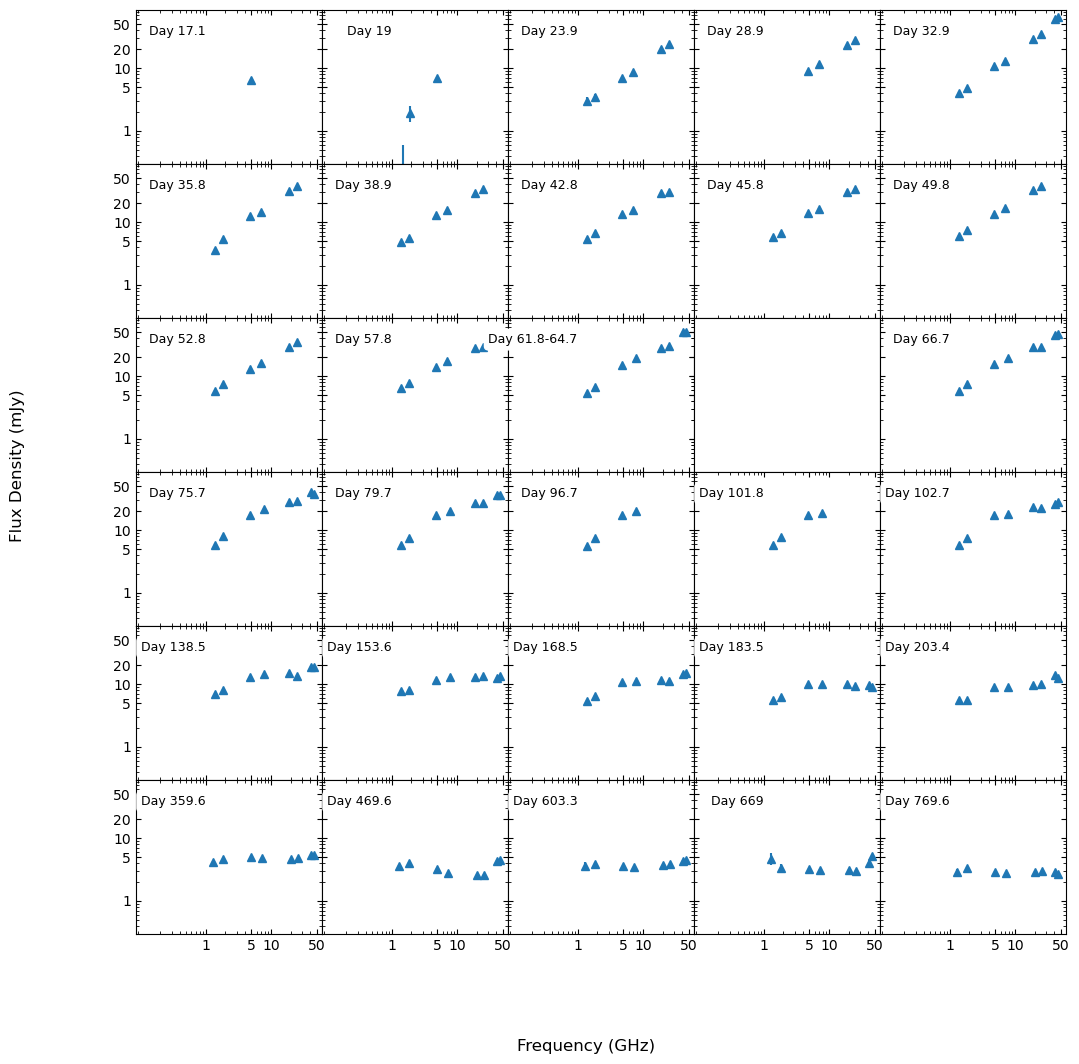

In [34]:
fig, ax = plt.subplots(6, 5, sharex='all', sharey='all',squeeze=True, width_ratios=None, height_ratios=None)
fig.set_size_inches(12,12)
fig.subplots_adjust(hspace=0, wspace=0)



ax[0, 0].errorbar(df1['Freq'], df1['Flux'], yerr=df1['Error (gaussfit or image)'],fmt='^', label='Day 17.1' )
#ax[0,0].legend(loc='upper left', edgecolor='1', markerscale = 0, handlelength=0,  handletextpad=0)
ax[0,0].set_xscale('log')
ax[0,0].set_xticks([1,5,10,50], labels = ['1','5','10','50'])
ax[0,0].set_yscale('log')
ax[0,0].set_yticks([1,5,10,20,50, 100], labels = ['1','5','10','20','50', '100'])
ax[0,0].annotate('Day 17.1', xy=(50, 100), xycoords='axes points',size=9, ha='right', va='top',bbox=dict(boxstyle='round', fc='w', ec="w"))
ax[0,0].tick_params(axis='both', which='both', direction='in', top=True, right=True)


ax[0, 1].errorbar(df2['Freq'], df2['Flux'], yerr=df2['Error (gaussfit or image)'],fmt='^', label='Day 19' )
#ax[0,1].legend(loc='upper left', edgecolor='1', markerscale = 0, handlelength=0,  handletextpad=0)
ax[0,1].annotate('Day 19', xy=(50, 100), xycoords='axes points', size=9, ha='right', va='top',bbox=dict(boxstyle='round', fc='w', ec="w"))
ax[0,1].tick_params(axis='both', which='both', direction='in', top=True, right=True)

ax[0, 2].errorbar(df3['Freq'], df3['Flux'], yerr=df3['Error (gaussfit or image)'],fmt='^', label='Day 23.9' )
#ax[0,2].legend(loc='upper left', edgecolor='1', markerscale = 0, handlelength=0,  handletextpad=0)
ax[0,2].annotate('Day 23.9', xy=(50, 100), xycoords='axes points',size=9, ha='right', va='top',bbox=dict(boxstyle='round', fc='w', ec="w"))
ax[0,2].tick_params(axis='both', which='both', direction='in', top=True, right=True)

ax[0, 3].errorbar(df4['Freq'], df4['Flux'], yerr=df4['Error (gaussfit or image)'],fmt='^', label='Day 28.9' )
ax[0,3].annotate('Day 28.9', xy=(50, 100), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
ax[0,3].tick_params(axis='both', which='both', direction='in', top=True, right=True)

ax[0, 4].errorbar(df5['Freq'], df5['Flux'], yerr=df5['Error (gaussfit or image)'],fmt='^', label='Day 32.9' )
ax[0,4].annotate('Day 32.9', xy=(50, 100), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
ax[0,4].tick_params(axis='both', which='both', direction='in', top=True, right=True)



ax[1, 0].errorbar(df6['Freq'], df6['Flux'], yerr=df6['Error (gaussfit or image)'],fmt='^')
ax[1,0].annotate('Day 35.8', xy=(50, 100), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
ax[1,0].tick_params(axis='both', which='both', direction='in', top=True, right=True)

ax[1, 1].errorbar(df7['Freq'], df7['Flux'], yerr=df7['Error (gaussfit or image)'],fmt='^')
ax[1,1].annotate('Day 38.9', xy=(50, 100), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
ax[1,1].tick_params(axis='both', which='both', direction='in', top=True, right=True)

ax[1, 2].errorbar(df8['Freq'], df8['Flux'], yerr=df8['Error (gaussfit or image)'],fmt='^')
ax[1,2].annotate('Day 42.8', xy=(50, 100), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
ax[1,2].tick_params(axis='both', which='both', direction='in', top=True, right=True)

ax[1, 3].errorbar(df9['Freq'], df9['Flux'], yerr=df9['Error (gaussfit or image)'],fmt='^')
ax[1,3].annotate('Day 45.8', xy=(50, 100), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
ax[1,3].tick_params(axis='both', which='both', direction='in', top=True, right=True)

ax[1, 4].errorbar(df10['Freq'], df10['Flux'], yerr=df10['Error (gaussfit or image)'],fmt='^')
ax[1,4].annotate('Day 49.8', xy=(50, 100), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
ax[1,4].tick_params(axis='both', which='both', direction='in', top=True, right=True)



ax[2, 0].errorbar(df11['Freq'], df11['Flux'], yerr=df11['Error (gaussfit or image)'],fmt='^')
ax[2,0].annotate('Day 52.8', xy=(50, 100), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
ax[2,0].tick_params(axis='both', which='both', direction='in', top=True, right=True)

ax[2, 1].errorbar(df12['Freq'], df12['Flux'], yerr=df12['Error (gaussfit or image)'],fmt='^')
ax[2,1].annotate('Day 57.8', xy=(50, 100), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
ax[2,1].tick_params(axis='both', which='both', direction='in', top=True, right=True)

ax[2, 2].errorbar(df13['Freq'], df13['Flux'], yerr=df13['Error (gaussfit or image)'],fmt='^')
ax[2,2].annotate('Day 61.8-64.7', xy=(50, 100), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
ax[2,2].tick_params(axis='both', which='both', direction='in', top=True, right=True)

#ax[2, 3].errorbar(df13_2['Freq'], df13_2['Flux'], yerr=df13_2['Error (gaussfit or image)'],fmt='^')
#ax[2,3].annotate('Day 64.7', xy=(50, 100), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
#ax[2,3].tick_params(axis='both', which='both', direction='in', top=True, right=True)

ax[2, 4].errorbar(df14['Freq'], df14['Flux'], yerr=df14['Error (gaussfit or image)'],fmt='^')
ax[2,4].annotate('Day 66.7', xy=(50, 100), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
ax[2,4].tick_params(axis='both', which='both', direction='in', top=True, right=True)



ax[3, 0].errorbar(df15['Freq'], df15['Flux'], yerr=df15['Error (gaussfit or image)'],fmt='^')
ax[3,0].annotate('Day 75.7', xy=(50, 100), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
ax[3,0].tick_params(axis='both', which='both', direction='in', top=True, right=True)

ax[3, 1].errorbar(df16['Freq'], df16['Flux'], yerr=df16['Error (gaussfit or image)'],fmt='^')
ax[3,1].annotate('Day 79.7', xy=(50, 100), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
ax[3,1].tick_params(axis='both', which='both', direction='in', top=True, right=True)

ax[3, 2].errorbar(df17['Freq'], df17['Flux'], yerr=df17['Error (gaussfit or image)'],fmt='^')
ax[3,2].annotate('Day 96.7', xy=(50, 100), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
ax[3,2].tick_params(axis='both', which='both', direction='in', top=True, right=True)

ax[3, 3].errorbar(df18['Freq'], df18['Flux'], yerr=df18['Error (gaussfit or image)'],fmt='^')
ax[3,3].annotate('Day 101.8', xy=(50, 100), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
ax[3,3].tick_params(axis='both', which='both', direction='in', top=True, right=True)

ax[3, 4].errorbar(df19['Freq'], df19['Flux'], yerr=df19['Error (gaussfit or image)'],fmt='^')
ax[3,4].annotate('Day 102.7', xy=(50, 100), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
ax[3,4].tick_params(axis='both', which='both', direction='in', top=True, right=True)



ax[4, 0].errorbar(df20['Freq'], df20['Flux'], yerr=df20['Error (gaussfit or image)'],fmt='^')
ax[4,0].annotate('Day 138.5', xy=(50, 100), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
ax[4,0].tick_params(axis='both', which='both', direction='in', top=True, right=True)

ax[4, 1].errorbar(df21['Freq'], df21['Flux'], yerr=df21['Error (gaussfit or image)'],fmt='^')
ax[4,1].annotate('Day 153.6', xy=(50, 100), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
ax[4,1].tick_params(axis='both', which='both', direction='in', top=True, right=True)

ax[4, 2].errorbar(df22['Freq'], df22['Flux'], yerr=df22['Error (gaussfit or image)'],fmt='^')
ax[4,2].annotate('Day 168.5', xy=(50, 100), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
ax[4,2].tick_params(axis='both', which='both', direction='in', top=True, right=True)

ax[4, 3].errorbar(df23['Freq'], df23['Flux'], yerr=df23['Error (gaussfit or image)'],fmt='^')
ax[4,3].annotate('Day 183.5', xy=(50, 100), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
ax[4,3].tick_params(axis='both', which='both', direction='in', top=True, right=True)

ax[4, 4].errorbar(df24['Freq'], df24['Flux'], yerr=df24['Error (gaussfit or image)'],fmt='^')
ax[4,4].annotate('Day 203.4', xy=(50, 100), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
ax[4,4].tick_params(axis='both', which='both', direction='in', top=True, right=True)



ax[5, 0].errorbar(df25['Freq'], df25['Flux'], yerr=df25['Error (gaussfit or image)'],fmt='^')
ax[5,0].annotate('Day 359.6', xy=(50, 100), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
ax[5,0].tick_params(axis='both', which='both', direction='in', top=True, right=True)

ax[5, 1].errorbar(df26['Freq'], df26['Flux'], yerr=df26['Error (gaussfit or image)'],fmt='^')
ax[5,1].annotate('Day 469.6', xy=(50, 100), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
ax[5,1].tick_params(axis='both', which='both', direction='in', top=True, right=True)

ax[5, 2].errorbar(df27['Freq'], df27['Flux'], yerr=df27['Error (gaussfit or image)'],fmt='^')
ax[5,2].annotate('Day 603.3', xy=(50, 100), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
ax[5,2].tick_params(axis='both', which='both', direction='in', top=True, right=True)

ax[5, 3].errorbar(df28['Freq'], df28['Flux'], yerr=df28['Error (gaussfit or image)'],fmt='^')
ax[5,3].annotate('Day 669', xy=(50, 100), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
ax[5,3].tick_params(axis='both', which='both', direction='in', top=True, right=True)

ax[5, 4].errorbar(df29['Freq'], df29['Flux'], yerr=df29['Error (gaussfit or image)'],fmt='^')
ax[5,4].annotate('Day 769.6', xy=(50, 100), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
ax[5,4].tick_params(axis='both', which='both', direction='in', top=True, right=True)

#ax.set_xscale('log')
#ax.set_yscale('log')
#ax.set_xlabel("Frequency (GHz)")
#ax.set_ylabel("Flux Density (mJy)")

fig.supxlabel("Frequency (GHz)")
fig.supylabel("Flux Density (mJy)")
#plt.legend()
plt.show();

### Now to add in the linefits
---
#### Functions needed

In [35]:
#CHI(freq_F23,fw_tBPL2(freq_F23))

#O = observed values (the measured flux densities)
#E = expected values (the modelled flux densities)


def cs(O,E):
    X=[]
    for i in range(len(E)):
        X.append(((O[i]-E[i])**2) / E[i])
    XS = np.sum(X)
        
    return(XS)

#This gives chi squared, but we want reduced chi squared so just divide by the number of free

#Xhi = cs(flux,BPL_ww(freq))
#print("The chi squared is",Xhi)

In [36]:
def error(err, freq, flux):
    yerr = []
    for i in range(len(freq)):
        if freq[i] < 10:
            pl = np.sqrt(err[i]**2 + (flux[i]*0.05)**2)
            yerr.append(pl)
        else:
            pl =np.sqrt(err[i]**2 + (flux[i]*0.1)**2)
            yerr.append(pl)

    return(yerr)

In [37]:
#Initialize fitters
fitBPL = fitting.LevMarLSQFitter(calc_uncertainties=True)

print(fitBPL.fit_info)

#A function that will produce a broken power law for given input values
#Also fits the BPL using LevMarLSQFitter 
#Issue: not all BPL's work so I get an error when trying to fit it to the data 

def bpl_func(freq, flux, er, a1, a2):
    wt = 1 / (np.power(er,2))
    peak = np.max(flux)
    BPL = []
    
    for i in range(0,len(freq)):
        for j in range(0,len(a1)):
            bro = BrokenPowerLaw1D(peak, freq[i], alpha_1 = a1[j], alpha_2 = a2[j])
            BPL.append(bro)
        
        
    return(BPL)

{'nfev': None, 'fvec': None, 'fjac': None, 'ipvt': None, 'qtf': None, 'message': None, 'ierr': None, 'param_jac': None, 'param_cov': None}


### Day 17.1, df1 - NOT USING

In [38]:
mask = df1['Flux'] > 3 * df1['Error (gaussfit or image)']  # apply detection threshold

yerr1 = error(df1['Error (gaussfit or image)'].values.tolist(), df1['Freq'][mask].values.tolist(), df1['Flux'][mask].values.tolist())

## df_1 - NOT USING

In [39]:
mask = df_1['Flux'] > 3 * df_1['Error (gaussfit or image)']  # apply detection threshold
if mask.any():
    x_1 = df_1['Freq'][mask].values.tolist()
    y_1 = df_1['Flux'][mask].values.tolist()
    yerr_1 = df_1['Error (gaussfit or image)'].values.tolist()

yerr_1 = error(yerr_1, x_1, y_1)

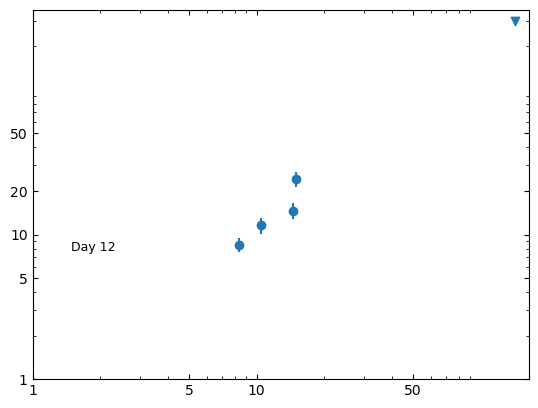

In [40]:
fig,ax = plt.subplots()
mask = df_1['Flux'] > 3 * df_1['Error (gaussfit or image)']  # apply detection threshold
mask2 = df_1['Flux'] < 3 * df_1['Error (gaussfit or image)']  # apply detection threshold
if mask.any():  # proceed only if at least one detection
    ax.errorbar(df_1['Freq'][mask], df_1['Flux'][mask], yerr=yerr_1, fmt='o')
    ax.scatter(df_1['Freq'][mask2], (df_1['Flux'][mask2] + 3*df_1['Error (gaussfit or image)'][mask2]), marker='v')
    ax.set_xscale('log')
    ax.set_xticks([1, 5, 10, 50], labels=['1', '5', '10', '50'])
    ax.set_yscale('log')
    ax.set_yticks([1, 5, 10, 20, 50], labels=['1', '5', '10', '20', '50'])
    ax.annotate('Day 12', xy=(60, 100), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
    ax.tick_params(axis='both', which='both', direction='in', top=True, right=True)
    #ax.plot(df_1['Freq'][mask], fit_model_weights2(df2['Freq'][mask]), 'r--')
    #ax.annotate('${\u03B1 = 1.34 \\pm 0.282}$', xy=(90, 80), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))

plt.show();

### Day 19 (df2) - No chi squared test needed (two points)

In [41]:
mask = df2['Flux'] > 3 * df2['Error (gaussfit or image)']  # apply detection threshold
if mask.any():
    x2 = df2['Freq'][mask].values.tolist()
    y2 = df2['Flux'][mask].values.tolist()
    yerr2 = df2['Error (gaussfit or image)'].values.tolist()

In [42]:
yerr2 = error(yerr2, x2, y2)

In [43]:
#Since this day has only two data points, I have to make x_0 fixed in order to run the powerlaw1d. 
#this is done in the code below so I can use the function for the rest of the points

PL2 =  PowerLaw1D(amplitude = y2[0], x_0= x2[0], alpha= -1.4,
                     bounds={
        'amplitude': (0, None),  # Amplitude should be positive
        #'x_0': (x3[0], x3[0]),  # Frequency must stay within data
        'alpha': (-10, 10)  # Keep alpha within a realistic range
    },
                 fixed={'x_0': True}) 

    #Initialize fitters
    #setting calc_uncertainties=True to output errors on measurement 

fit = fitting.LevMarLSQFitter(calc_uncertainties=True)

    #Fit the data w/o weights
fit_model2 = fit(PL2, x2, y2)

    #weight is 1/error^2
y_weight2 = 1/ (np.power(yerr2,2))  

    # fit the data using the uncertainties as weights
fit_model_weights2 = fit(PL2, x2, y2, weights=y_weight2)

fit_model_weights2


<PowerLaw1D(amplitude=1.93, x_0=1.9, alpha=-1.33656147)>

In [44]:
#Error on alpha for only two data points
def two_points(Flux, Freq, Err):
    
    alpha = (np.log10(Flux[0]/Flux[1])) / (np.log10(Freq[0]/Freq[1]))
    
    
    der_s1 = 1 / (Flux[0] * np.log(Freq[0]/Freq[1]))
    der_s2 = -1 / (Flux[1] * np.log(Freq[0]/Freq[1]))
    
    
    err_alph_squared = (der_s1)**2 * (Err[0]**2) + (der_s2)**2 * (Err[1]**2) 
    err_alph = np.sqrt(err_alph_squared)
    
    return(alpha, err_alph)

In [45]:
alpha_err2 = two_points(y2,x2,yerr2)
print(alpha_err2)

(1.3365614727347834, 0.39992957545642593)


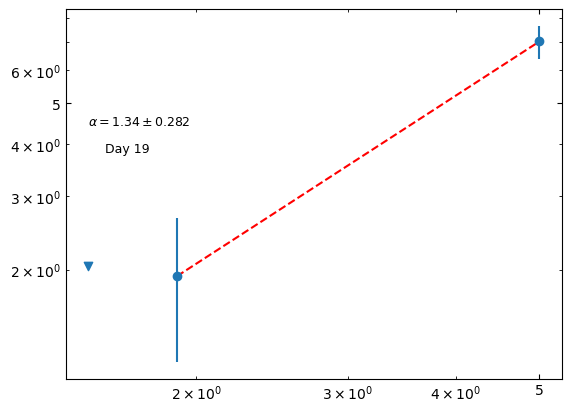

In [46]:
fig,ax = plt.subplots()
mask = df2['Flux'] > 3 * df2['Error (gaussfit or image)']  # apply detection threshold
mask2 = df2['Flux'] < 3 * df2['Error (gaussfit or image)']  # apply detection threshold
if mask.any():  # proceed only if at least one detection
    ax.errorbar(df2['Freq'][mask], df2['Flux'][mask], yerr=yerr2, fmt='o')
    ax.scatter(df2['Freq'][mask2], (df2['Flux'][mask2] + 3*df2['Error (gaussfit or image)'][mask2]), marker='v')
    ax.set_xscale('log')
    ax.set_xticks([1, 5, 10, 50], labels=['1', '5', '10', '50'])
    ax.set_yscale('log')
    ax.set_yticks([1, 5, 10, 20, 50], labels=['1', '5', '10', '20', '50'])
    ax.annotate('Day 19', xy=(60, 170), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
    ax.tick_params(axis='both', which='both', direction='in', top=True, right=True)
    ax.plot(df2['Freq'][mask], fit_model_weights2(df2['Freq'][mask]), 'r--')
    ax.annotate('${\u03B1 = 1.34 \\pm 0.282}$', xy=(90, 190), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))

plt.show();

### Day 23.9 (df3)

In [51]:
x3= df3['Freq'].values.tolist()
y3 = df3['Flux'].values.tolist()
yerr3=df3['Error (gaussfit or image)'].values.tolist()

In [52]:
yerr3 = error(yerr3, x3, y3)

In [54]:


PL3 =  PowerLaw1D(amplitude = y3[0], x_0= x3[0], alpha= .6) 

#Initialize fitters
#setting calc_uncertainties=True to output errors on measurement 

fit3 = fitting.LevMarLSQFitter(calc_uncertainties=True)

#Fit the data w/o weights
fit_model3 = fit3(PL3, x3, y3)


#weight is 1/error^2
x_weight3 = 1/ (np.power(yerr3,2))  

# fit the data using the uncertainties as weights
fit_model_weights3 = fit3(PL3, x3, y3, weights=x_weight3)

fit_model_weights3


<PowerLaw1D(amplitude=4.64336749, x_0=2.73249842, alpha=-0.69011005)>

In [55]:
fit.fit_info

{'nfev': 5,
 'fvec': array([ 0.00000000e+00, -2.22423899e-15]),
 'fjac': array([[-17.04402986,  -1.        ],
        [  9.12696295,  -1.89497212]]),
 'ipvt': array([1, 0], dtype=int32),
 'qtf': array([2.55342636e-11, 0.00000000e+00]),
 'message': 'The relative error between two consecutive iterates is at most 0.000000',
 'ierr': 2,
 'param_jac': None,
 'param_cov': None,
 'njev': 4,
 'cov_x': array([[0.27848022, 0.14912428],
        [0.14912428, 0.0832974 ]])}

In [56]:
fvec3 = np.array([-0.19519163,  0.07974287, -0.22187406,  0.37494948, -0.66231396,
        -0.52276837])
var3 = np.var(fvec3)

param_cov= np.array([[2.46360640e+29, 2.24024144e+29, 3.04866634e+12],
        [2.24024144e+29, 2.03712805e+29, 2.77225642e+12],
        [3.04866634e+12, 2.77225642e+12, 1.03073379e-03]])
#This function takes the square root of the diagonal of the matrix 

#The diagonal elements of a covariance matrix are the variances: https://stackoverflow.com/questions/52275542/how-to-calculate-the-standard-error-from-a-variance-covariance-matrix 
#The square root of them are the standard deviations

def stand(cov):
    diag = np.diagonal(cov)
    sd1 = np.sqrt(diag[0])
    sd2 = np.sqrt(diag[1])
    sd3 = np.sqrt(diag[2])
    return(sd1,sd2,sd3)

diag = stand(param_cov*var3) 

#The last diagonal element corresponds to alpha
#So here we are calculating the standard deviation on the slope

#print(diag)  #prints standard deviations of all three variances

print(diag[2]) #Just showing the standard devation on the slope


0.011173739180395017


In [57]:
Xhi = cs(df3['Flux'], fit_model_weights3( df3["Freq"] ))
print("The chi squared is", Xhi/(6-4))

The chi squared is 0.4517610185972133


In [58]:
#BROKEN POWER
#Input values for function above 
#Going through a range of x values (the point where the line breaks)
#And different alpha 1 and alpha 2 values (the alpha values on either side of that break)

x_val = np.arange(1.1,40,0.5)   #Going through a range of freq values from 0.1 to 40
                                #because thats what my data ranges from, may be different for you
    
a1 = np.arange(-1,0,0.2)
a2 = np.arange(0,1,0.2)

#Will output many BPL functions 
#Check through them, if they are very far off they won't work in fitBPL
BM3 = bpl_func(x_val, y3, yerr3, a1, a2)

#BM3[43] worked for me and gives me a reasonable output in fitBPL
BM3[50]

#Apply error as weighting in the function 

weight3 = 1/ (np.power(yerr3,2))
fw_BPL3 = fitBPL(BM3[50], x3, y3, weights=weight3)   
print(fw_BPL3)
print("")
print(fitBPL.fit_info)


#taking fvec
fvec3 = np.array([-0.10837243,  0.22235868, -0.2640647 ,  0.22212968, -0.10306422,
        0.09263156])
var3 = np.var(fvec3)

#taking cov_x
cov_x3 = np.array([[ 3.39872713e+03,  3.93373163e+03, -2.08910583e-02,
        -6.71963388e+01],
       [ 3.93373163e+03,  4.55298891e+03, -2.01748115e-02,
        -7.77776423e+01],
       [-2.08910583e-02, -2.01748115e-02,  1.05498908e-03,
         7.39967983e-17],
       [-6.71963388e+01, -7.77776423e+01,  7.39967983e-17,
         1.34860516e+00]])

def stand(cov):
    diag = np.diagonal(cov)
    sd1 = np.sqrt(diag[0])
    sd2 = np.sqrt(diag[1])
    sd3 = np.sqrt(diag[2]) #err 1
    sd4 = np.sqrt(diag[3]) #err 2
    return(sd1,sd2,sd3, sd4)

diag3 = stand(cov_x3*var3) 

#The last diagonal element corresponds to alpha
#So here we are calculating the standard deviation on the slope

#print(diag)  #prints standard deviations of all three variances
print("")
print('The error/standard deviation of the first one is', diag3[2], diag3[3]) #Just showing the standard deviation on the slope


Xhi = cs(df3['Flux'], fw_BPL3( df3["Freq"] ))
print("")
print("The chi squared is", Xhi/(6-4))

"""
#for plotting
x_freq = np.arange(1,36,0.5)

    #in the if
    ax.plot(df3['Freq'][mask], fw_BPL3(df3['Freq'][mask]), 'b--')
    ax.annotate('${\u03B1_1 = 0.68 \\pm 0.006}$', xy=(90, 160), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
    ax.annotate('${\u03B1_2 = 0.82 \\pm 0.21}$', xy=(90, 140), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
""";

Model: BrokenPowerLaw1D
Inputs: ('x',)
Outputs: ('y',)
Model set size: 1
Parameters:
        amplitude          x_break            alpha_1             alpha_2      
    ----------------- ----------------- ------------------- -------------------
    8.855791041145237 7.000001358861933 -0.6829070576323251 -0.8185057178774504

{'nfev': 30, 'fvec': array([-0.10837243,  0.22235868, -0.2640647 ,  0.22212968, -0.10306422,
        0.09263156]), 'fjac': array([[-4.05101302e+01,  0.00000000e+00,  2.89238447e+00,
        -2.49888838e+00,  0.00000000e+00,  0.00000000e+00],
       [ 0.00000000e+00, -7.12808308e+00, -2.99819343e-01,
         3.10463538e-01, -6.68449463e-01, -7.43757565e-01],
       [-5.21608558e+00,  7.09959266e-01, -6.10010120e+00,
        -4.28995825e+00, -8.50498225e-02, -1.15820344e-01],
       [ 4.50646026e+00, -7.35164260e-01,  5.27041940e+00,
        -1.48201194e-02, -7.44590340e-01,  6.67484060e-01]]), 'ipvt': array([2, 3, 0, 1], dtype=int32), 'qtf': array([ 5.91798436e-08, 

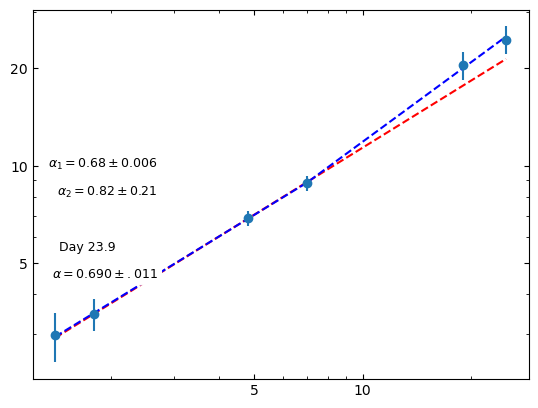

In [59]:
fig,ax = plt.subplots()
x_freq = np.arange(1,36,0.5)
mask = df3['Flux'] > 3 * df3['Error (gaussfit or image)']  # apply detection threshold
mask2 = df3['Flux'] < 3 * df3['Error (gaussfit or image)']  # apply detection threshold
if mask.any():  # proceed only if at least one detection
    ax.errorbar(df3['Freq'][mask], df3['Flux'][mask], yerr=yerr3, fmt='o')
    ax.scatter(df3['Freq'][mask2], (df3['Flux'][mask2] + 3*df3['Error (gaussfit or image)'][mask2]), marker='v')
    ax.set_xscale('log')
    ax.set_xticks([1, 5, 10, 50], labels=['1', '5', '10', '50'])
    ax.set_yscale('log')
    ax.set_yticks([1, 5, 10, 20, 50], labels=['1', '5', '10', '20', '50'])
    ax.annotate('Day 23.9', xy=(60, 100), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
    ax.tick_params(axis='both', which='both', direction='in', top=True, right=True)
    ax.plot(df3['Freq'][mask], fit_model_weights3(df3['Freq'][mask]), 'r--')
    ax.annotate('${\u03B1 = 0.690 \\pm .011}$', xy=(90, 80), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))

    ax.plot(df3['Freq'][mask], fw_BPL3(df3['Freq'][mask]), 'b--')
    ax.annotate('${\u03B1_1 = 0.68 \\pm 0.006}$', xy=(90, 160), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
    ax.annotate('${\u03B1_2 = 0.82 \\pm 0.21}$', xy=(90, 140), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))

plt.show();

### Day 28.9 (df4)

In [60]:
x4= df4['Freq'].values.tolist()
y4 = df4['Flux'].values.tolist()
yerr4=df4['Error (gaussfit or image)'].values.tolist()

In [61]:
yerr4 = error(yerr4, x4, y4)

In [62]:


PL4 =  PowerLaw1D(amplitude = y4[0], x_0= x4[0], alpha= -4.5) 

#Initialize fitters
#setting calc_uncertainties=True to output errors on measurement 

fit4 = fitting.LevMarLSQFitter(calc_uncertainties=True)

#Fit the data w/o weights
fit_model4 = fit4(PL4, x4, y4)


#weight is 1/error^2
y_weight4 = 1/ (np.power(yerr4, 2))  

# fit the data using the uncertainties as weights
fit_model_weights4 = fit4(PL4, x4, y4, weights=y_weight4)

fit_model_weights4


<PowerLaw1D(amplitude=29.35917396, x_0=24.82727106, alpha=-0.71866879)>

In [63]:
fit4.fit_info

{'nfev': 19,
 'fvec': array([ 0.23433849,  0.10188076, -0.16853515,  0.10214174]),
 'fjac': array([[ 7.94474601e+01,  1.78334548e+00, -1.51558088e+00,
         -8.51406947e-01],
        [ 1.78334548e+00, -2.82876147e-01,  2.40403042e-01,
         -1.57986995e-02],
        [-1.51558088e+00,  2.40403042e-01,  6.55776527e-17,
         -9.06014116e-01]]),
 'ipvt': array([2, 0, 1], dtype=int32),
 'qtf': array([ 6.47746740e-06, -1.02728913e-06,  3.21567586e-01]),
 'message': 'Both actual and predicted relative reductions in the sum of squares\n  are at most 0.000000',
 'ierr': 1,
 'param_jac': None,
 'param_cov': array([[ 1.67948267e+32,  1.97620456e+32, -1.51791091e+15],
        [ 1.97620456e+32,  2.32534965e+32, -1.78608717e+15],
        [-1.51791091e+15, -1.78608717e+15,  2.01740363e-02]]),
 'njev': 11,
 'cov_x': array([[ 1.67948267e+32,  1.97620456e+32, -1.51791091e+15],
        [ 1.97620456e+32,  2.32534965e+32, -1.78608717e+15],
        [-1.51791091e+15, -1.78608717e+15,  2.01740363e-0

In [64]:
fvec4 = np.array([ 0.23433851,  0.10188078, -0.16853495,  0.102142  ])
var4 = np.var(fvec4)

param_cov4= np.array([[ 1.11119164e+31,  1.30833518e+31, -3.74708070e+13],
        [ 1.30833518e+31,  1.54045521e+31, -4.41187401e+13],
        [-3.74708070e+13, -4.41187401e+13,  6.58156374e-03]])

def stand(cov):
    diag = np.diagonal(cov)
    sd1 = np.sqrt(diag[0])
    sd2 = np.sqrt(diag[1])
    sd3 = np.sqrt(diag[2])
    return(sd1,sd2,sd3)

diag4 = stand(param_cov4*var4) 

#The last diagonal element corresponds to alpha
#So here we are calculating the standard deviation on the slope

#print(diag)  #prints standard deviations of all three variances

print(diag4[2]) #Just showing the standard devation on the slope


0.011890665425042057


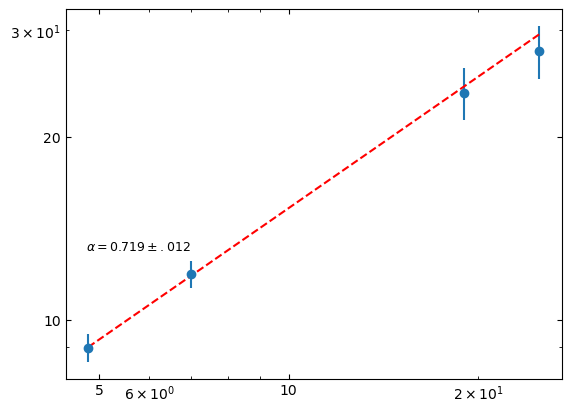

In [65]:
fig,ax = plt.subplots()
mask = df4['Flux'] > 3 * df4['Error (gaussfit or image)']  # apply detection threshold
mask2 = df4['Flux'] < 3 * df4['Error (gaussfit or image)']  # apply detection threshold
if mask.any():  # proceed only if at least one detection
    ax.errorbar(df4['Freq'][mask], df4['Flux'][mask], yerr=yerr4, fmt='o')
    ax.scatter(df4['Freq'][mask2], (df4['Flux'][mask2] + 3*df4['Error (gaussfit or image)'][mask2]), marker='v')
    ax.set_xscale('log')
    ax.set_xticks([1, 5, 10, 50], labels=['1', '5', '10', '50'])
    ax.set_yscale('log')
    ax.set_yticks([1, 5, 10, 20, 50], labels=['1', '5', '10', '20', '50'])
    ax.annotate('Day 28.9', xy=(60, 100), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
    ax.tick_params(axis='both', which='both', direction='in', top=True, right=True)
    ax.plot(df4['Freq'][mask], fit_model_weights4(df4['Freq'][mask]), 'r--')
    ax.annotate('${\u03B1 = 0.719 \\pm .012}$', xy=(90, 100), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))

plt.show();

### Day 32.9 (df5)

In [66]:
x5= df5['Freq'].values.tolist()
y5 = df5['Flux'].values.tolist()
yerr5=df5['Error (gaussfit or image)'].values.tolist()

In [67]:
yerr5 = error(yerr5, x5, y5)

In [69]:


PL5 =  PowerLaw1D(amplitude = y5[0], x_0= x5[0], alpha= -0.7) 

#Initialize fitters
#setting calc_uncertainties=True to output errors on measurement 

fit5 = fitting.LevMarLSQFitter(calc_uncertainties=True)

#Fit the data w/o weights
fit_model5 = fit5(PL5, x5, y5)


#weight is 1/error^2
y_weight5 = 1/ (np.power(yerr5, 2))  

# fit the data using the uncertainties as weights
fit_model_weights5 = fit5(PL5, x5, y5, weights=y_weight5)

fit_model_weights5

<PowerLaw1D(amplitude=213.70653998, x_0=275.42688001, alpha=-0.75226882)>

In [70]:
fit5.fit_info

{'nfev': 16,
 'fvec': array([-0.24620993, -0.24264462, -0.01050214, -0.06291961,  1.43002146,
        -1.76035259,  0.64323969, -0.15441145]),
 'fjac': array([[-2.93969120e+02, -2.99870972e-01,  1.75032614e-01,
          3.06393086e-02,  3.88585034e-01,  4.70700717e-01,
          5.66523481e-01,  5.52163917e-01],
        [-2.99870972e-01, -4.47371742e-02,  2.61127795e-02,
          1.44588478e-01,  6.18775443e-01,  3.82366373e-01,
         -3.78459299e-01, -5.29449914e-01],
        [ 1.75032614e-01,  2.61127795e-02, -1.51043022e-17,
          1.43562034e-01,  6.89097765e-01, -2.29699255e-01,
          3.44548882e-01,  5.74248137e-01]]),
 'ipvt': array([2, 0, 1], dtype=int32),
 'qtf': array([-1.05657957e-05, -1.57612307e-06, -1.66379458e+00]),
 'message': 'Both actual and predicted relative reductions in the sum of squares\n  are at most 0.000000',
 'ierr': 1,
 'param_jac': None,
 'param_cov': array([[ 1.49337121e+33,  2.55848704e+33, -5.51026355e+14],
        [ 2.55848704e+33,  4.38327

In [71]:
fvec5 = np.array([-0.24621005, -0.24264476, -0.01050243, -0.06291996,  1.43001824,
        -1.76035613,  0.64323626, -0.15441463])
var5 = np.var(fvec5)

param_cov5= np.array([[2.59003316e+32, 2.98184269e+32, 3.83708318e+14],
        [2.98184269e+32, 3.43292354e+32, 4.41754129e+14],
        [3.83708318e+14, 4.41754129e+14, 1.09993681e-03]])

def stand(cov):
    diag = np.diagonal(cov)
    sd1 = np.sqrt(diag[0])
    sd2 = np.sqrt(diag[1])
    sd3 = np.sqrt(diag[2])
    return(sd1,sd2,sd3)

diag5 = stand(param_cov5*var5) 

#The last diagonal element corresponds to alpha
#So here we are calculating the standard deviation on the slope

#print(diag)  #prints standard deviations of all three variances

print(diag5[2]) #Just showing the standard devation on the slope


0.02795685521986715


In [72]:
Xhi = cs(df5['Flux'], fit_model_weights5( df5["Freq"] ))
print("The chi squared is", Xhi/(8-4))

The chi squared is 0.951583861715734


In [73]:
#BROKEN POWER
#Input values for function above 
#Going through a range of x values (the point where the line breaks)
#And different alpha 1 and alpha 2 values (the alpha values on either side of that break)

x_val = np.arange(1.1,40,0.5)   #Going through a range of freq values from 0.1 to 40
                                #because thats what my data ranges from, may be different for you
    
a1 = np.arange(-1,0,0.2)
a2 = np.arange(0,1,0.2)

#Will output many BPL functions 
#Check through them, if they are very far off they won't work in fitBPL
BM5 = bpl_func(x_val, y5, yerr5, a1, a2)

#BM3[43] worked for me and gives me a reasonable output in fitBPL
BM5[50]

#Apply error as weighting in the function 

weight5 = 1/ (np.power(yerr5,2))
fw_BPL5 = fitBPL(BM5[50], x5, y5, weights=weight5)   
print(fw_BPL5)
print("")
print(fitBPL.fit_info)

"""
#taking fvec
fvec4 = np.array(   )
var4 = np.var(fvec4)

#taking cov_x
cov_x4 = np.array(   )

def stand(cov):
    diag = np.diagonal(cov)
    sd1 = np.sqrt(diag[0])
    sd2 = np.sqrt(diag[1])
    sd3 = np.sqrt(diag[2]) #err 1
    sd4 = np.sqrt(diag[3]) #err 2
    return(sd1,sd2,sd3, sd4)

diag4 = stand(cov_x4*var4) 

#The last diagonal element corresponds to alpha
#So here we are calculating the standard deviation on the slope

#print(diag)  #prints standard deviations of all three variances
print("")
print('The error/standard deviation of the first one is', diag4[2], diag4[3]) #Just showing the standard deviation on the slope
"""

Xhi = cs(df5['Flux'], fw_BPL5( df5["Freq"] ))
print("")
print("The chi squared is", Xhi/(8-4))

"""
#for plotting
x_freq = np.arange(1,36,0.5)

    #in the if
    ax.plot(df3['Freq'][mask], fw_BPL3(df3['Freq'][mask]), 'b--')
    ax.annotate('${\u03B1_1 = 0.68 \\pm 0.006}$', xy=(90, 160), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
    ax.annotate('${\u03B1_2 = 0.82 \\pm 0.21}$', xy=(90, 140), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
""";

Model: BrokenPowerLaw1D
Inputs: ('x',)
Outputs: ('y',)
Model set size: 1
Parameters:
        amplitude           x_break            alpha_1             alpha_2      
    ------------------ ----------------- ------------------- -------------------
    10.523304365999085 4.799998752415392 -0.7903845041847898 -0.5891792336222994

{'nfev': 53, 'fvec': array([-0.59190398, -0.61786373, -0.59886071, -0.6428167 ,  0.62938901,
       -0.52713494,  0.57945573, -0.50602848]), 'fjac': array([[-4.95126614e+01,  0.00000000e+00, -2.28042692e-01,
         1.31603286e-01,  0.00000000e+00,  0.00000000e+00,
         6.54553100e-01,  7.56016031e-01],
       [ 0.00000000e+00,  1.29511564e+01,  2.26300337e-01,
        -1.75197039e-01,  8.82843001e-01,  7.10463626e-07,
        -1.00174788e-01, -1.15702982e-01],
       [ 7.34324930e+00,  3.50113163e+00, -4.62438049e+00,
        -2.09772266e-01, -2.11861700e-01, -9.39667258e-01,
        -1.89006589e-01,  5.88701936e-02],
       [-4.23778430e+00, -2.71050368e+0

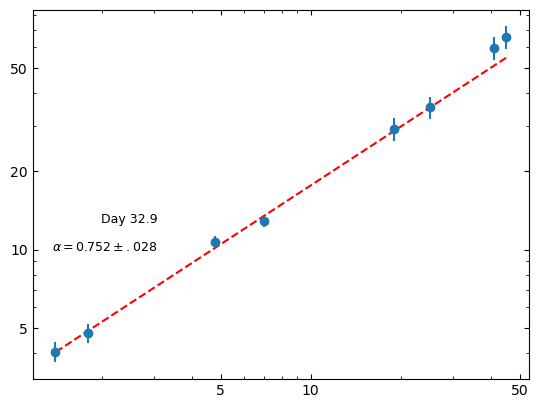

In [74]:
fig,ax = plt.subplots()
mask = df5['Flux'] > 3 * df5['Error (gaussfit or image)']  # apply detection threshold
mask2 = df5['Flux'] < 3 * df5['Error (gaussfit or image)']  # apply detection threshold
if mask.any():  # proceed only if at least one detection
    ax.errorbar(df5['Freq'][mask], df5['Flux'][mask], yerr=yerr5, fmt='o')
    ax.scatter(df5['Freq'][mask2], (df5['Flux'][mask2] + 3*df5['Error (gaussfit or image)'][mask2]), marker='v')
    ax.set_xscale('log')
    ax.set_xticks([1, 5, 10, 50], labels=['1', '5', '10', '50'])
    ax.set_yscale('log')
    ax.set_yticks([1, 5, 10, 20, 50], labels=['1', '5', '10', '20', '50'])
    ax.annotate('Day 32.9', xy=(90, 120), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
    ax.tick_params(axis='both', which='both', direction='in', top=True, right=True)
    ax.plot(df5['Freq'][mask], fit_model_weights5(df5['Freq'][mask]), 'r--')
    ax.annotate('${\u03B1 = 0.752 \\pm .028}$', xy=(90, 100), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))

plt.show();

### Day 35.8 (df6)

In [75]:
x6= df6['Freq'].values.tolist()
y6 = df6['Flux'].values.tolist()
yerr6=df6['Error (gaussfit or image)'].values.tolist()

In [76]:
yerr6 = error(yerr6, x6, y6)

In [77]:

PL6 =  PowerLaw1D(amplitude = y6[0], x_0= x6[0], alpha= -2.5) 

#Initialize fitters
#setting calc_uncertainties=True to output errors on measurement 

fit6 = fitting.LevMarLSQFitter(calc_uncertainties=True)

#Fit the data w/o weights
fit_model6 = fit6(PL6, x6, y6)


#weight is 1/error^2
y_weight6 = 1/ (np.power(yerr6, 2))  

# fit the data using the uncertainties as weights
fit_model_weights6 = fit6(PL6, x6, y6, weights=y_weight6)

fit_model_weights6

<PowerLaw1D(amplitude=113.4224827, x_0=73.0270855, alpha=-0.84314276)>

In [78]:
fit6.fit_info

{'nfev': 26,
 'fvec': array([ 0.62742054,  0.58075425,  1.88172748, -2.25621203, -2.84507386,
         3.15887513]),
 'fjac': array([[-1.88706617e+02,  6.50845654e-01, -4.97157925e-01,
          3.97250279e-01,  5.95773845e-01,  6.00147472e-01],
        [ 6.50845654e-01,  1.39639345e-01, -1.06665546e-01,
          3.46817634e-01, -3.81373539e-01, -5.44393418e-01],
        [-4.97157925e-01, -1.06665546e-01, -5.67972945e-17,
         -6.10847222e-01,  1.22169444e-01,  6.10847222e-01]]),
 'ipvt': array([2, 1, 0], dtype=int32),
 'qtf': array([-4.42362090e-04, -9.49090651e-05, -3.78540733e+00]),
 'message': 'Both actual and predicted relative reductions in the sum of squares\n  are at most 0.000000',
 'ierr': 1,
 'param_jac': None,
 'param_cov': array([[ 3.09987872e+32,  2.36788748e+32, -3.04051812e+13],
        [ 2.36788748e+32,  1.80874531e+32, -2.32254401e+13],
        [-3.04051812e+13, -2.32254401e+13,  6.41115161e-04]]),
 'njev': 19,
 'cov_x': array([[ 3.09987872e+32,  2.36788748e+32, 

In [79]:
#taking fvec
fvec6 = np.array([ 0.62742077,  0.58075452,  1.88172948, -2.2562101 , -2.84507172,
         3.15887715])
var6 = np.var(fvec6)

#taking paramcov
param_cov6= np.array([[3.32306999e+31, 2.13996112e+31, 2.06690184e+14],
        [2.13996112e+31, 1.37807317e+31, 1.33102510e+14],
        [2.06690184e+14, 1.33102510e+14, 1.92371809e-03]])

def stand(cov):
    diag = np.diagonal(cov)
    sd1 = np.sqrt(diag[0])
    sd2 = np.sqrt(diag[1])
    sd3 = np.sqrt(diag[2])
    return(sd1,sd2,sd3)

diag6 = stand(param_cov6*var6) 

#The last diagonal element corresponds to alpha
#So here we are calculating the standard deviation on the slope

#print(diag)  #prints standard deviations of all three variances

print(diag6[2]) #Just showing the standard deviation on the slope



0.09341264077931907


In [80]:
Xhi = cs(df6['Flux'], fit_model_weights6( df6["Freq"] ))
print("The chi squared is", Xhi/(6-4))

The chi squared is 1.3658874052384238


In [81]:
#BROKEN POWER
#Input values for function above 
#Going through a range of x values (the point where the line breaks)
#And different alpha 1 and alpha 2 values (the alpha values on either side of that break)

x_val = np.arange(1.1,40,0.5)   #Going through a range of freq values from 0.1 to 40
                                #because thats what my data ranges from, may be different for you
    
a1 = np.arange(-1,0,0.2)
a2 = np.arange(0,1,0.2)

#Will output many BPL functions 
#Check through them, if they are very far off they won't work in fitBPL
BM6 = bpl_func(x_val, y6, yerr6, a1, a2)

#BM3[43] worked for me and gives me a reasonable output in fitBPL
BM6[50]

#Apply error as weighting in the function 

weight6 = 1/ (np.power(yerr6,2))
fw_BPL6 = fitBPL(BM6[50], x6, y6, weights=weight6)   
print(fw_BPL6)
print("")
print(fitBPL.fit_info)


#taking fvec
fvec6 = np.array( [-6.00885689e-01, -6.11754357e-01,  4.18313631e-01, -2.87233919e-01,
       -9.31522050e-11, -7.14775816e-11]  )
var6 = np.var(fvec4)

#taking cov_x
cov_x6 = np.array( [[ 1.78114846e+00,  3.25356622e-01,  5.21573154e-02,
         1.45627837e-01],
       [ 3.25356622e-01,  6.94953597e-02,  2.77876943e-02,
         2.42511818e-02],
       [ 5.21573154e-02,  2.77876943e-02,  3.87878084e-02,
        -1.73472348e-17],
       [ 1.45627837e-01,  2.42511818e-02, -1.73472348e-17,
         1.31726386e-02]]  )

def stand(cov):
    diag = np.diagonal(cov)
    sd1 = np.sqrt(diag[0])
    sd2 = np.sqrt(diag[1])
    sd3 = np.sqrt(diag[2]) #err 1
    sd4 = np.sqrt(diag[3]) #err 2
    return(sd1,sd2,sd3, sd4)

diag6 = stand(cov_x6*var6) 

#The last diagonal element corresponds to alpha
#So here we are calculating the standard deviation on the slope

#print(diag)  #prints standard deviations of all three variances
print("")
print('The error/standard deviation of the first one is', diag6[2], diag6[3]) #Just showing the standard deviation on the slope


Xhi = cs(df6['Flux'], fw_BPL6( df6["Freq"] ))
print("")
print("The chi squared is", Xhi/(6-4))

"""
#for plotting
x_freq = np.arange(1,36,0.5)

    #in the if
    ax.plot(d6['Freq'][mask], fw_BPL6(df6['Freq'][mask]), 'b--', alpha=0.6)
    ax.annotate('${\u03B1_1 = 0.68 \\pm 0.006}$', xy=(90, 160), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
    ax.annotate('${\u03B1_2 = 0.82 \\pm 0.21}$', xy=(90, 140), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
""";

Model: BrokenPowerLaw1D
Inputs: ('x',)
Outputs: ('y',)
Model set size: 1
Parameters:
        amplitude          x_break             alpha_1             alpha_2      
    ----------------- ------------------ ------------------- -------------------
    8.407593027150288 2.3312228780552275 -1.6650334230897044 -0.5204470623732566

{'nfev': 16, 'fvec': array([-6.00885689e-01, -6.11754357e-01,  4.18313631e-01, -2.87233919e-01,
       -9.31522050e-11, -7.14744375e-11]), 'fjac': array([[ 3.73414255e+01,  1.47323395e-01,  7.97202986e-01,
         5.70296536e-01, -0.00000000e+00, -0.00000000e+00],
       [ 8.72052869e+00, -2.99519200e+01,  1.41041794e-02,
        -6.53266113e-02, -7.91422313e-01, -6.07264264e-01],
       [ 0.00000000e+00,  1.46785691e+01, -5.18054839e+00,
        -1.81403914e-01, -5.40912901e-01,  8.20348653e-01],
       [-4.64600955e+00,  5.04138816e+00,  1.51701838e-01,
        -7.49290006e-01, -4.96771118e-01,  9.89199734e-02]]), 'ipvt': array([3, 1, 2, 0], dtype=int32), 'qtf

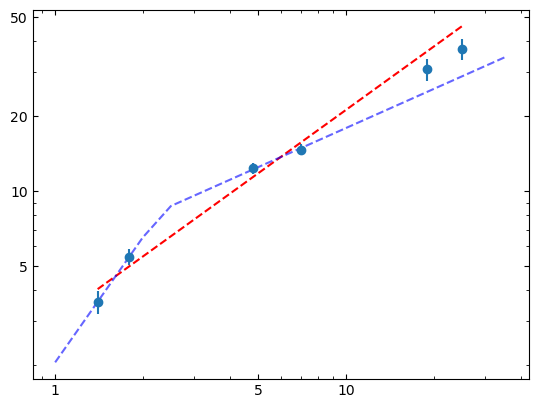

In [82]:
#plotting to check
fig,ax = plt.subplots()
x_freq = np.arange(1,36,0.5)
mask = df6['Flux'] > 3 * df6['Error (gaussfit or image)']  # apply detection threshold
mask2 = df6['Flux'] < 3 * df6['Error (gaussfit or image)']  # apply detection threshold
if mask.any():  # proceed only if at least one detection
    ax.errorbar(df6['Freq'][mask], df6['Flux'][mask], yerr=yerr6, fmt='o')
    ax.scatter(df6['Freq'][mask2], (df6['Flux'][mask2] + 3*df6['Error (gaussfit or image)'][mask2]), marker='v')
    ax.set_xscale('log')
    ax.set_xticks([1, 5, 10, 50], labels=['1', '5', '10', '50'])
    ax.set_yscale('log')
    ax.set_yticks([1, 5, 10, 20, 50], labels=['1', '5', '10', '20', '50'])
    #ax.annotate('Day 35.8', xy=(90, 120), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
    ax.tick_params(axis='both', which='both', direction='in', top=True, right=True)
    ax.plot(df6['Freq'][mask], fit_model_weights6(df6['Freq'][mask]), 'r--')
    #ax.annotate('${\u03B1 = .843 \\pm .093}$', xy=(90, 100), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
    
    ax.plot(x_freq, fw_BPL6(x_freq), 'b--', alpha=0.6)
    #ax.annotate('${\u03B1_1 = 1.67 \\pm 0.04}$', xy=(90, 160), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
    #ax.annotate('${\u03B1_2 = 0.52 \\pm 0.02}$', xy=(90, 140), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
plt.show();


### Day 38.9 (df7)

In [83]:
x7 = df7['Freq'].values.tolist()
y7 = df7['Flux'].values.tolist()
yerr7 =df7['Error (gaussfit or image)'].values.tolist()

In [84]:
yerr7 = error(yerr7, x7, y7)

In [85]:


PL7 =  PowerLaw1D(amplitude = y7[0], x_0= x7[0], alpha= -1.5) 

#Initialize fitters
#setting calc_uncertainties=True to output errors on measurement 

fit7 = fitting.LevMarLSQFitter(calc_uncertainties=True)

#Fit the data w/o weights
fit_model7 = fit7(PL7, x7, y7)


#weight is 1/error^2
y_weight7 = 1/ (np.power(yerr7, 2))  

# fit the data using the uncertainties as weights
fit_model_weights7 = fit7(PL7, x7, y7, weights=y_weight7)

fit_model_weights7


<PowerLaw1D(amplitude=40.98389476, x_0=23.85842248, alpha=-0.76177124)>

In [86]:
fit7.fit_info

{'nfev': 17,
 'fvec': array([ 0.68658402,  0.62317502,  0.8245801 , -1.62629294,  1.06327025,
        -0.36794742]),
 'fjac': array([[ 1.29725146e+02, -1.74833379e+00,  1.33657813e+00,
         -3.42096594e-01, -5.74862280e-01, -7.02567706e-01],
        [-1.74833379e+00,  5.57553819e-01, -4.26242541e-01,
          5.79426941e-01, -3.37989568e-02, -2.19788686e-01],
        [ 1.33657813e+00, -4.26242541e-01,  9.96522768e-17,
         -2.78524250e-01, -6.61495093e-01, -4.17786374e-01]]),
 'ipvt': array([2, 1, 0], dtype=int32),
 'qtf': array([ 2.56592158e-04, -8.21248127e-05,  2.65854798e-01]),
 'message': 'Both actual and predicted relative reductions in the sum of squares\n  are at most 0.000000',
 'ierr': 1,
 'param_jac': None,
 'param_cov': array([[1.00699091e+32, 7.69831266e+31, 4.65454909e+14],
        [7.69831266e+31, 5.88525850e+31, 3.55834139e+14],
        [4.65454909e+14, 3.55834139e+14, 2.79515254e-03]]),
 'njev': 9,
 'cov_x': array([[1.00699091e+32, 7.69831266e+31, 4.65454909e+

In [87]:
#taking fvec
fvec7 = np.array([0.68658397,  0.62317496,  0.82457972, -1.62629335,  1.06326982,
        -0.3679479 ])
var7 = np.var(fvec7)

#taking cov_x
cov_x7 = np.array([[ 4.55464637e+30,  2.76868911e+30, -3.25093560e+13],
        [ 2.76868911e+30,  1.68303723e+30, -1.97618635e+13],
        [-3.25093560e+13, -1.97618635e+13,  8.75755675e-04]])

def stand(cov):
    diag = np.diagonal(cov)
    sd1 = np.sqrt(diag[0])
    sd2 = np.sqrt(diag[1])
    sd3 = np.sqrt(diag[2])
    return(sd1,sd2,sd3)

diag7 = stand(cov_x7*var7) 

#The last diagonal element corresponds to alpha
#So here we are calculating the standard deviation on the slope

#print(diag)  #prints standard deviations of all three variances

print(diag7[2]) #Just showing the standard deviation on the slope


0.027573799690408678


In [88]:
Xhi = cs(df7['Flux'], fit_model_weights7( df7["Freq"] ))
print("The chi squared is", Xhi/(6-4))

The chi squared is 1.2188192612563933


In [89]:
#BROKEN POWER
#Input values for function above 
#Going through a range of x values (the point where the line breaks)
#And different alpha 1 and alpha 2 values (the alpha values on either side of that break)

x_val = np.arange(1.1,40,0.5)   #Going through a range of freq values from 0.1 to 40
                                #because thats what my data ranges from, may be different for you
    
a1 = np.arange(-1,0,0.2)
a2 = np.arange(0,1,0.2)

#Will output many BPL functions 
#Check through them, if they are very far off they won't work in fitBPL
BM7 = bpl_func(x_val, y7, yerr7, a1, a2)

#BM3[43] worked for me and gives me a reasonable output in fitBPL
BM7[50]

#Apply error as weighting in the function 

weight7 = 1/ (np.power(yerr7,2))
fw_BPL7 = fitBPL(BM7[50], x7, y7, weights=weight7)   
print(fw_BPL7)
print("")
print(fitBPL.fit_info)

"""
#taking fvec
fvec4 = np.array(   )
var4 = np.var(fvec4)

#taking cov_x
cov_x4 = np.array(   )

def stand(cov):
    diag = np.diagonal(cov)
    sd1 = np.sqrt(diag[0])
    sd2 = np.sqrt(diag[1])
    sd3 = np.sqrt(diag[2]) #err 1
    sd4 = np.sqrt(diag[3]) #err 2
    return(sd1,sd2,sd3, sd4)

diag4 = stand(cov_x4*var4) 

#The last diagonal element corresponds to alpha
#So here we are calculating the standard deviation on the slope

#print(diag)  #prints standard deviations of all three variances
print("")
print('The error/standard deviation of the first one is', diag4[2], diag4[3]) #Just showing the standard deviation on the slope
"""

Xhi = cs(df7['Flux'], fw_BPL7( df7["Freq"] ))
print("")
print("The chi squared is", Xhi/(6-4))

"""
#for plotting
x_freq = np.arange(1,36,0.5)

    #in the if
    ax.plot(df3['Freq'][mask], fw_BPL3(df3['Freq'][mask]), 'b--')
    ax.annotate('${\u03B1_1 = 0.68 \\pm 0.006}$', xy=(90, 160), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
    ax.annotate('${\u03B1_2 = 0.82 \\pm 0.21}$', xy=(90, 140), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
""";

Model: BrokenPowerLaw1D
Inputs: ('x',)
Outputs: ('y',)
Model set size: 1
Parameters:
        amplitude           x_break            alpha_1             alpha_2      
    ------------------ ----------------- ------------------- -------------------
    12.651870550707297 4.800000628457715 -0.8090982828919956 -0.5699292695874517

{'nfev': 25, 'fvec': array([-0.16388286, -0.16909143,  0.16083456, -0.32068218,  1.05526943,
       -0.7565528 ]), 'fjac': array([[-4.82539395e+01,  0.00000000e+00, -2.64865627e-01,
         1.24196935e-01,  5.86005893e-01,  8.10306790e-01],
       [ 0.00000000e+00,  1.13674454e+01,  1.45034141e-01,
        -9.65463456e-02, -2.32979350e-01, -3.22155035e-01],
       [ 7.18217281e+00,  2.73801655e+00,  5.09993259e+00,
        -2.04369906e-01,  1.92640810e-01, -2.36855040e-03],
       [-3.36775993e+00, -1.82264321e+00, -2.45103192e+00,
         2.37274417e-01, -8.99274544e-02, -3.82584179e-01]]), 'ipvt': array([2, 3, 1, 0], dtype=int32), 'qtf': array([-0.00535421, -

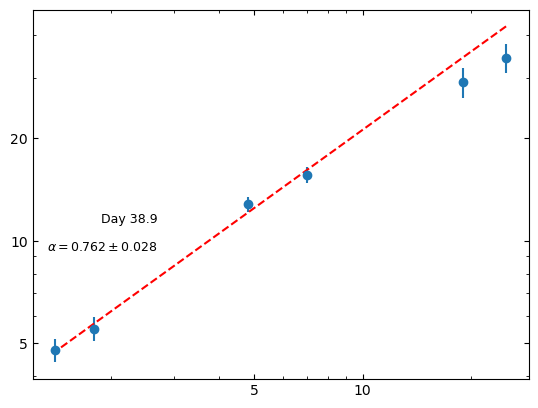

In [90]:
#plotting to check
fig,ax = plt.subplots()
mask = df7['Flux'] > 3 * df7['Error (gaussfit or image)']  # apply detection threshold
mask2 = df7['Flux'] < 3 * df7['Error (gaussfit or image)']  # apply detection threshold
if mask.any():  # proceed only if at least one detection
    ax.errorbar(df7['Freq'][mask], df7['Flux'][mask], yerr=yerr7, fmt='o')
    ax.scatter(df7['Freq'][mask2], (df7['Flux'][mask2] + 3*df7['Error (gaussfit or image)'][mask2]), marker='v')
    ax.set_xscale('log')
    ax.set_xticks([1, 5, 10, 50], labels=['1', '5', '10', '50'])
    ax.set_yscale('log')
    ax.set_yticks([1, 5, 10, 20, 50], labels=['1', '5', '10', '20', '50'])
    ax.annotate('Day 38.9', xy=(90, 120), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
    ax.tick_params(axis='both', which='both', direction='in', top=True, right=True)
    ax.plot(df7['Freq'][mask], fit_model_weights7(df7['Freq'][mask]), 'r--')
    ax.annotate('${\u03B1 = 0.762 \\pm 0.028}$', xy=(90, 100), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))

plt.show();


### Day 42.8 (df8)

In [91]:
x8 = df8['Freq'].values.tolist()
y8 = df8['Flux'].values.tolist()
yerr8 = df8['Error (gaussfit or image)'].values.tolist()


In [92]:
yerr8 = error(yerr8, x8, y8)

In [95]:

PL8 =  PowerLaw1D(amplitude = y8[0], x_0= x8[0], alpha= -0.7) 

#Initialize fitters
#setting calc_uncertainties=True to output errors on measurement 

fit8 = fitting.LevMarLSQFitter(calc_uncertainties=True)

#Fit the data w/o weights
fit_model8 = fit8(PL8, x8, y8)


#weight is 1/error^2
y_weight8 = 1/ (np.power(yerr8, 2))  

# fit the data using the uncertainties as weights
fit_model_weights8 = fit8(PL8, x8, y8, weights=y_weight8)

fit_model_weights8


<PowerLaw1D(amplitude=114.68300193, x_0=127.27606385, alpha=-0.6700956)>

In [96]:
fit8.fit_info

{'nfev': 13,
 'fvec': array([ 0.88340347,  0.3741081 ,  1.11797484, -1.88223937, -0.23838427,
         0.62484654]),
 'fjac': array([[-2.29208619e+02, -5.01786124e-01,  3.02975652e-01,
          3.66369780e-01,  5.58560204e-01,  6.65493494e-01],
        [-5.01786124e-01, -8.94316580e-02,  5.39983343e-02,
          3.57271315e-01, -3.32443631e-01, -5.90701340e-01],
        [ 3.02975652e-01,  5.39983343e-02, -3.12250226e-17,
          1.11111111e-01,  8.88888889e-01, -4.44444444e-01]]),
 'ipvt': array([2, 0, 1], dtype=int32),
 'qtf': array([-6.50524415e-05, -1.16206747e-05,  9.07910387e-01]),
 'message': 'Both actual and predicted relative reductions in the sum of squares\n  are at most 0.000000',
 'ierr': 1,
 'param_jac': None,
 'param_cov': array([[ 3.73914787e+32,  6.19275016e+32, -1.27943451e+14],
        [ 6.19275016e+32,  1.02563889e+33, -2.11899035e+14],
        [-1.27943451e+14, -2.11899035e+14,  6.62042142e-04]]),
 'njev': 6,
 'cov_x': array([[ 3.73914787e+32,  6.19275016e+32, -

In [97]:
#taking fvec
fvec8 = np.array([ 0.88340032,  0.37410519,  1.11795486, -1.88225901, -0.23840742,
         0.62482048])
var8 = np.var(fvec8)

#taking cov_x
cov_x8 = np.array([[ 2.48942172e+32,  3.98857084e+32, -6.87865905e+14],
        [ 3.98857084e+32,  6.39051921e+32, -1.10210410e+15],
        [-6.87865905e+14, -1.10210410e+15,  2.51894471e-03]])

def stand(cov):
    diag = np.diagonal(cov)
    sd1 = np.sqrt(diag[0])
    sd2 = np.sqrt(diag[1])
    sd3 = np.sqrt(diag[2])
    return(sd1,sd2,sd3)

diag8 = stand(cov_x8*var8) 

#The last diagonal element corresponds to alpha
#So here we are calculating the standard deviation on the slope

#print(diag)  #prints standard deviations of all three variances

print('The error / standard deviation is', diag8[2]) #Just showing the standard deviation on the slope


The error / standard deviation is 0.05032007113555803


In [98]:
Xhi = cs(df8['Flux'], fit_model_weights8( df8["Freq"] ))
print("The chi squared is", Xhi/(6-4))

The chi squared is 1.0808735943559702


In [99]:
#BROKEN POWER
#Input values for function above 
#Going through a range of x values (the point where the line breaks)
#And different alpha 1 and alpha 2 values (the alpha values on either side of that break)

x_val = np.arange(1.1,40,0.5)   #Going through a range of freq values from 0.1 to 40
                                #because thats what my data ranges from, may be different for you
    
a1 = np.arange(-1,0,0.2)
a2 = np.arange(0,1,0.2)

#Will output many BPL functions 
#Check through them, if they are very far off they won't work in fitBPL
BM8 = bpl_func(x_val, y8, yerr8, a1, a2)

#BM3[43] worked for me and gives me a reasonable output in fitBPL
BM8[50]

#Apply error as weighting in the function 

weight8 = 1/ (np.power(yerr8,2))
fw_BPL8 = fitBPL(BM8[50], x8, y8, weights=weight8)   
print(fw_BPL8)
print("")
print(fitBPL.fit_info)

"""
#taking fvec
fvec4 = np.array(   )
var4 = np.var(fvec4)

#taking cov_x
cov_x4 = np.array(   )

def stand(cov):
    diag = np.diagonal(cov)
    sd1 = np.sqrt(diag[0])
    sd2 = np.sqrt(diag[1])
    sd3 = np.sqrt(diag[2]) #err 1
    sd4 = np.sqrt(diag[3]) #err 2
    return(sd1,sd2,sd3, sd4)

diag4 = stand(cov_x4*var4) 

#The last diagonal element corresponds to alpha
#So here we are calculating the standard deviation on the slope

#print(diag)  #prints standard deviations of all three variances
print("")
print('The error/standard deviation of the first one is', diag4[2], diag4[3]) #Just showing the standard deviation on the slope
"""

Xhi = cs(df8['Flux'], fw_BPL8( df8["Freq"] ))
print("")
print("The chi squared is", Xhi/(6-4))

"""
#for plotting
x_freq = np.arange(1,36,0.5)

    #in the if
    ax.plot(df3['Freq'][mask], fw_BPL3(df3['Freq'][mask]), 'b--')
    ax.annotate('${\u03B1_1 = 0.68 \\pm 0.006}$', xy=(90, 160), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
    ax.annotate('${\u03B1_2 = 0.82 \\pm 0.21}$', xy=(90, 140), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
""";

Model: BrokenPowerLaw1D
Inputs: ('x',)
Outputs: ('y',)
Model set size: 1
Parameters:
        amplitude          x_break            alpha_1             alpha_2       
    ----------------- ----------------- ------------------- --------------------
    12.74504819804583 4.153998150536284 -0.7757204519630254 -0.42998742298848625

{'nfev': 8, 'fvec': array([-2.95491189e-01, -5.23493777e-01,  3.70389069e-01, -2.56502666e-01,
        6.90810254e-12,  7.56774000e-12]), 'fjac': array([[-4.41111972e+01,  0.00000000e+00,  0.00000000e+00,
         0.00000000e+00,  5.74475482e-01,  8.18521790e-01],
       [ 0.00000000e+00,  1.54394094e+01,  8.56717884e-01,
         2.55077064e-01, -1.98038135e-01, -2.82167880e-01],
       [ 8.32506453e+00,  3.15934764e+00,  2.48732782e+00,
         8.58010249e-01,  4.95454210e-01, -4.30687598e-02],
       [-3.49789707e+00, -2.39477457e+00, -1.72981075e+00,
        -3.26383187e-01, -6.97463308e-01,  6.18207588e-01]]), 'ipvt': array([2, 3, 1, 0], dtype=int32), 'qtf'

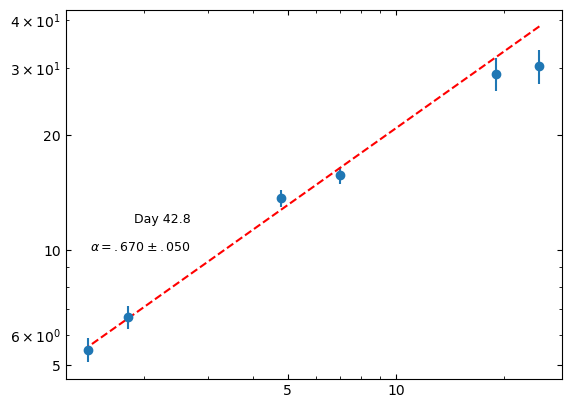

In [100]:
#plotting to check
fig,ax = plt.subplots()
mask = df8['Flux'] > 3 * df8['Error (gaussfit or image)']  # apply detection threshold
mask2 = df8['Flux'] < 3 * df8['Error (gaussfit or image)']  # apply detection threshold
if mask.any():  # proceed only if at least one detection
    ax.errorbar(df8['Freq'][mask], df8['Flux'][mask], yerr=yerr8, fmt='o')
    ax.scatter(df8['Freq'][mask2], (df8['Flux'][mask2] + 3*df8['Error (gaussfit or image)'][mask2]), marker='v')
    ax.set_xscale('log')
    ax.set_xticks([1, 5, 10, 50], labels=['1', '5', '10', '50'])
    ax.set_yscale('log')
    ax.set_yticks([1, 5, 10, 20, 50], labels=['1', '5', '10', '20', '50'])
    ax.annotate('Day 42.8', xy=(90, 120), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
    ax.tick_params(axis='both', which='both', direction='in', top=True, right=True)
    ax.plot(df8['Freq'][mask], fit_model_weights8(df8['Freq'][mask]), 'r--')
    ax.annotate('${\u03B1 = .670 \\pm .050}$', xy=(90, 100), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))

plt.show();


### Day 45.8 (df9)

In [101]:
x9 = df9['Freq'].values.tolist()
y9 = df9['Flux'].values.tolist()
yerr9 = df9['Error (gaussfit or image)'].values.tolist()

In [102]:
yerr9 = error(yerr9, x9, y9)

In [103]:


PL9 =  PowerLaw1D(amplitude = y9[0], x_0= x9[0], alpha= -1.5) 

#Initialize fitters
#setting calc_uncertainties=True to output errors on measurement 

fit9 = fitting.LevMarLSQFitter(calc_uncertainties=True)

#Fit the data w/o weights
fit_model9 = fit9(PL9, x9, y9)


#weight is 1/error^2
y_weight9 = 1/ (np.power(yerr9, 2))  

# fit the data using the uncertainties as weights
fit_model_weights9 = fit9(PL9, x9, y9, weights=y_weight9)

fit_model_weights9


<PowerLaw1D(amplitude=26.79458822, x_0=14.18342228, alpha=-0.65896798)>

In [104]:
fit9.fit_info

{'nfev': 21,
 'fvec': array([ 0.44235393,  0.22798389,  1.15687833, -1.70739276,  0.16455662,
         0.24622547]),
 'fjac': array([[ 1.05513530e+02, -2.54432766e+00,  2.04382015e+00,
         -2.72981994e-01, -6.49788567e-01, -6.87671793e-01],
        [-2.54432766e+00,  1.02311053e+00, -8.21849306e-01,
          5.81861392e-01,  1.96492289e-02, -1.52439370e-01],
        [ 2.04382015e+00, -8.21849306e-01,  2.81538726e-16,
          1.97170570e-01, -1.35554767e-01, -8.87267567e-01]]),
 'ipvt': array([2, 1, 0], dtype=int32),
 'qtf': array([ 3.32617954e-05, -1.33750434e-05,  4.76371222e-01]),
 'message': 'Both actual and predicted relative reductions in the sum of squares\n  are at most 0.000000',
 'ierr': 1,
 'param_jac': None,
 'param_cov': array([[1.26160592e+31, 1.01342906e+31, 9.04676305e+13],
        [1.01342906e+31, 8.14072326e+30, 7.26712871e+13],
        [9.04676305e+13, 7.26712871e+13, 1.29405108e-03]]),
 'njev': 13,
 'cov_x': array([[1.26160592e+31, 1.01342906e+31, 9.04676305e

In [105]:
#taking fvec
fvec9 = np.array([ 0.44235221,  0.22798211,  1.15686525, -1.70740621,  0.16453981,
         0.24620962])
var9 = np.var(fvec9)

#taking cov_x
cov_x9 = np.array([[1.59978336e+31, 1.33405177e+31, 9.60651430e+13],
        [1.33405177e+31, 1.11245946e+31, 8.01082681e+13],
        [9.60651430e+13, 8.01082681e+13, 1.22218011e-03]])

def stand(cov):
    diag = np.diagonal(cov)
    sd1 = np.sqrt(diag[0])
    sd2 = np.sqrt(diag[1])
    sd3 = np.sqrt(diag[2])
    return(sd1,sd2,sd3)

diag9 = stand(cov_x9*var9) 

#The last diagonal element corresponds to alpha
#So here we are calculating the standard deviation on the slope

#print(diag)  #prints standard deviations of all three variances

print('The error/standard deviation is', diag9[2]) #Just showing the standard deviation on the slope


The error/standard deviation is 0.030416956481627695


In [106]:
Xhi = cs(df9['Flux'], fit_model_weights9( df9["Freq"] ))
print("The chi squared is", Xhi/(6-4))

The chi squared is 0.44278322538208575


In [107]:
#BROKEN POWER
#Input values for function above 
#Going through a range of x values (the point where the line breaks)
#And different alpha 1 and alpha 2 values (the alpha values on either side of that break)

x_val = np.arange(1.1,40,0.5)   #Going through a range of freq values from 0.1 to 40
                                #because thats what my data ranges from, may be different for you
    
a1 = np.arange(-1,0,0.2)
a2 = np.arange(0,1,0.2)

#Will output many BPL functions 
#Check through them, if they are very far off they won't work in fitBPL
BM9 = bpl_func(x_val, y9, yerr9, a1, a2)

#BM3[43] worked for me and gives me a reasonable output in fitBPL
BM9[50]

#Apply error as weighting in the function 

weight9 = 1/ (np.power(yerr9,2))
fw_BPL9 = fitBPL(BM9[50], x9, y9, weights=weight9)   
print(fw_BPL9)
print("")
print(fitBPL.fit_info)


#taking fvec
fvec4 = np.array( [-0.43982167, -0.5290633 ,  0.40649521, -0.31677205,  0.17432912,
       -0.14904393]  )
var4 = np.var(fvec4)

#taking cov_x
cov_x4 = np.array( [[1.54782125e+01, 7.76551978e+00, 2.58267594e-02, 8.52393289e-01],
       [7.76551978e+00, 3.94996351e+00, 2.01414867e-02, 4.16969891e-01],
       [2.58267594e-02, 2.01414867e-02, 1.39729059e-03, 8.67361738e-19],
       [8.52393289e-01, 4.16969891e-01, 8.67361738e-19, 5.72991158e-02]]  )

def stand(cov):
    diag = np.diagonal(cov)
    sd1 = np.sqrt(diag[0])
    sd2 = np.sqrt(diag[1])
    sd3 = np.sqrt(diag[2]) #err 1
    sd4 = np.sqrt(diag[3]) #err 2
    return(sd1,sd2,sd3, sd4)

diag4 = stand(cov_x4*var4) 

#The last diagonal element corresponds to alpha
#So here we are calculating the standard deviation on the slope

#print(diag)  #prints standard deviations of all three variances
print("")
print('The error/standard deviation of the first one is', diag4[2], diag4[3]) #Just showing the standard deviation on the slope


Xhi = cs(df9['Flux'], fw_BPL9( df9["Freq"] ))
print("")
print("The chi squared is", Xhi/(6-4))

"""
#for plotting
x_freq = np.arange(1,36,0.5)

    #in the if
    ax.plot(df3['Freq'][mask], fw_BPL3(df3['Freq'][mask]), 'b--')
    ax.annotate('${\u03B1_1 = 0.68 \\pm 0.006}$', xy=(90, 160), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
    ax.annotate('${\u03B1_2 = 0.82 \\pm 0.21}$', xy=(90, 140), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
""";

Model: BrokenPowerLaw1D
Inputs: ('x',)
Outputs: ('y',)
Model set size: 1
Parameters:
       amplitude          x_break            alpha_1             alpha_2      
    ---------------- ----------------- ------------------- -------------------
    13.8076508159905 4.799999316213878 -0.7106516816396755 -0.4457587068825112

{'nfev': 29, 'fvec': array([-0.43982167, -0.5290633 ,  0.40649521, -0.31677205,  0.17432912,
       -0.14904393]), 'fjac': array([[-5.01509854e+01,  0.00000000e+00, -7.70703685e-02,
         3.77009340e-02,  6.49758200e-01,  7.60140962e-01],
       [ 0.00000000e+00,  1.10145272e+01,  2.74134972e-02,
        -2.13789342e-02, -2.44655540e-01, -2.86218315e-01],
       [ 6.67793287e+00,  2.18065335e+00,  4.30523744e+00,
        -5.03634376e-02,  2.02404924e-01, -3.58280339e-02],
       [-3.26668098e+00, -1.70062375e+00, -2.15996560e+00,
         2.54178959e-01, -1.45504786e-01, -4.23587803e-01]]), 'ipvt': array([2, 3, 1, 0], dtype=int32), 'qtf': array([ 2.87790467e-05, -1.

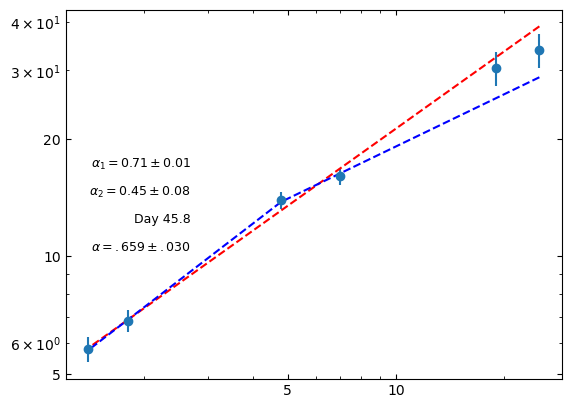

In [108]:
#plotting to check
fig,ax = plt.subplots()
mask = df9['Flux'] > 3 * df9['Error (gaussfit or image)']  # apply detection threshold
mask2 = df9['Flux'] < 3 * df9['Error (gaussfit or image)']  # apply detection threshold
if mask.any():  # proceed only if at least one detection
    ax.errorbar(df9['Freq'][mask], df9['Flux'][mask], yerr=yerr9, fmt='o')
    ax.scatter(df9['Freq'][mask2], (df9['Flux'][mask2] + 3*df9['Error (gaussfit or image)'][mask2]), marker='v')
    ax.set_xscale('log')
    ax.set_xticks([1, 5, 10, 50], labels=['1', '5', '10', '50'])
    ax.set_yscale('log')
    ax.set_yticks([1, 5, 10, 20, 50], labels=['1', '5', '10', '20', '50'])
    ax.annotate('Day 45.8', xy=(90, 120), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
    ax.tick_params(axis='both', which='both', direction='in', top=True, right=True)
    ax.plot(df9['Freq'][mask], fit_model_weights9(df9['Freq'][mask]), 'r--')
    ax.annotate('${\u03B1 = .659 \\pm .030}$', xy=(90, 100), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))

    ax.plot(df9['Freq'][mask], fw_BPL9(df9['Freq'][mask]), 'b--')
    ax.annotate('${\u03B1_1 = 0.71 \\pm 0.01}$', xy=(90, 160), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
    ax.annotate('${\u03B1_2 = 0.45 \\pm 0.08}$', xy=(90, 140), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))

plt.show();


### Day 49.8 (df10)

In [109]:
mask = df10['Flux'] > 3 * df10['Error (gaussfit or image)']  # apply detection threshold

x10 = df10['Freq'][mask].values.tolist()
y10 = df10['Flux'][mask].values.tolist()
yerr10 = df10['Error (gaussfit or image)'][mask].values.tolist()

In [110]:
yerr10 = error(yerr10, x10, y10)

In [111]:


PL10 =  PowerLaw1D(amplitude = y10[0], x_0= x10[0], alpha= -2.5) 

#Initialize fitters
#setting calc_uncertainties=True to output errors on measurement 

fit10 = fitting.LevMarLSQFitter(calc_uncertainties=True)

#Fit the data w/o weights
fit_model10 = fit10(PL10, x10, y10)


#weight is 1/error^2
y_weight10 = 1/ (np.power(yerr10, 2))  

# fit the data using the uncertainties as weights
fit_model_weights10 = fit10(PL10, x10, y10, weights=y_weight10)

fit_model_weights10


<PowerLaw1D(amplitude=43.34632167, x_0=28.94791851, alpha=-0.64902691)>

In [112]:
fit10.fit_info

{'nfev': 21,
 'fvec': array([ 0.13533976, -0.0046359 ,  0.51246711, -0.35263935, -1.04947733,
         0.80587877]),
 'fjac': array([[-1.60527782e+02, -1.40325601e+00,  1.36349689e+00,
          3.15781667e-01,  5.61791960e-01,  7.34631766e-01],
        [-1.40325601e+00, -3.66739939e-01,  3.56348922e-01,
          5.12841724e-01, -2.01515853e-01, -4.84939696e-01],
        [ 1.36349689e+00,  3.56348922e-01, -2.14993764e-16,
          3.87298335e-01, -1.29099445e-01,  9.03696114e-01]]),
 'ipvt': array([2, 0, 1], dtype=int32),
 'qtf': array([-5.09450672e-05, -1.33146281e-05, -6.92672717e-01]),
 'message': 'Both actual and predicted relative reductions in the sum of squares\n  are at most 0.000000',
 'ierr': 1,
 'param_jac': None,
 'param_cov': array([[ 2.04259731e+31,  2.10215877e+31, -3.02501364e+13],
        [ 2.10215877e+31,  2.16345702e+31, -3.11322203e+13],
        [-3.02501364e+13, -3.11322203e+13,  6.51747561e-04]]),
 'njev': 12,
 'cov_x': array([[ 2.04259731e+31,  2.10215877e+31, 

In [113]:
#taking fvec
fvec10 = np.array([ 0.13533984, -0.00463581,  0.51246781, -0.35263853, -1.04947639,
         0.8058799 ])
var10 = np.var(fvec10)

#taking cov_x
cov_x10 = np.array([[1.38964998e+31, 1.26587497e+31, 5.06284922e+12],
        [1.26587497e+31, 1.15312451e+31, 4.61190532e+12],
        [5.06284922e+12, 4.61190532e+12, 6.08791699e-04]])

def stand(cov):
    diag = np.diagonal(cov)
    sd1 = np.sqrt(diag[0])
    sd2 = np.sqrt(diag[1])
    sd3 = np.sqrt(diag[2])
    return(sd1,sd2,sd3)

diag10 = stand(cov_x10*var10) 

#The last diagonal element corresponds to alpha
#So here we are calculating the standard deviation on the slope

#print(diag)  #prints standard deviations of all three variances

print('The error/standard deviation is', diag10[2]) #Just showing the standard deviation on the slope



The error/standard deviation is 0.014789793543899869


In [114]:
Xhi = cs(df10['Flux'], fit_model_weights10( df10["Freq"] ))
print("The chi squared is", Xhi/(6-4))

The chi squared is 0.05609651818417904


In [115]:
#Will output many BPL functions 
#Check through them, if they are very far off they won't work in fitBPL
BM10 = bpl_func(x_val, y10, yerr10, a1, a2)

#BM3[43] worked for me and gives me a reasonable output in fitBPL
BM10[50]

#Apply error as weighting in the function 

weight10 = 1/ (np.power(yerr10,2))
fw_BPL10 = fitBPL(BM10[50], x10, y10, weights=weight10)   
print(fw_BPL10)
print("")
print(fitBPL.fit_info)

"""
#taking fvec
fvec4 = np.array(   )
var4 = np.var(fvec4)

#taking cov_x
cov_x4 = np.array(   )

def stand(cov):
    diag = np.diagonal(cov)
    sd1 = np.sqrt(diag[0])
    sd2 = np.sqrt(diag[1])
    sd3 = np.sqrt(diag[2]) #err 1
    sd4 = np.sqrt(diag[3]) #err 2
    return(sd1,sd2,sd3, sd4)

diag4 = stand(cov_x4*var4) 

#The last diagonal element corresponds to alpha
#So here we are calculating the standard deviation on the slope

#print(diag)  #prints standard deviations of all three variances
print("")
print('The error/standard deviation of the first one is', diag4[2], diag4[3]) #Just showing the standard deviation on the slope
"""

Xhi = cs(df10['Flux'], fw_BPL10( df10["Freq"] ))
print("")
print("The chi squared is", Xhi/(6-4))

"""
#for plotting
x_freq = np.arange(1,36,0.5)

    #in the if
    ax.plot(df3['Freq'][mask], fw_BPL3(df3['Freq'][mask]), 'b--')
    ax.annotate('${\u03B1_1 = 0.68 \\pm 0.006}$', xy=(90, 160), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
    ax.annotate('${\u03B1_2 = 0.82 \\pm 0.21}$', xy=(90, 140), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
""";

Model: BrokenPowerLaw1D
Inputs: ('x',)
Outputs: ('y',)
Model set size: 1
Parameters:
        amplitude          x_break            alpha_1             alpha_2      
    ----------------- ----------------- ------------------- -------------------
    33.04204826046903 19.01830501061288 -0.6495708082980801 -0.4634712612251335

{'nfev': 28, 'fvec': array([ 1.72066206e-06, -9.71907880e-04,  5.28507539e-01, -3.39547215e-01,
       -1.05172872e+00,  7.97858910e-01]), 'fjac': array([[-1.35029857e+02,  0.00000000e+00,  2.05135060e+00,
        -1.81707266e+00,  5.66492288e-01,  7.51668197e-01],
       [ 0.00000000e+00, -7.31415532e-01, -6.51055756e-02,
         8.07122797e-02,  5.66492288e-01,  7.51668197e-01],
       [ 2.05135060e+00, -6.51055756e-02,  6.37598096e-01,
        -5.64780135e-01, -1.74037931e-01, -4.53460099e-01],
       [-1.81707266e+00,  8.07122797e-02, -5.64780135e-01,
        -2.11835237e-16,  3.27560891e-01, -5.24097426e-01]]), 'ipvt': array([2, 3, 1, 0], dtype=int32), 'qtf': 

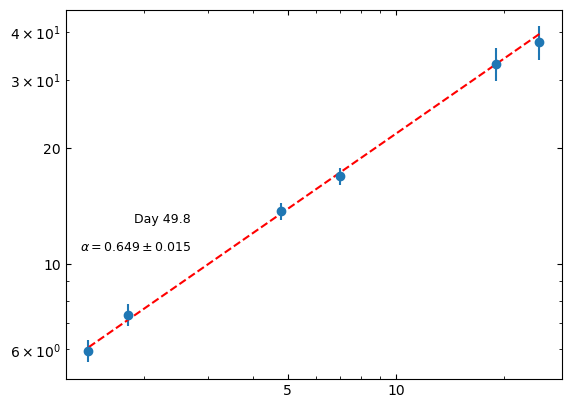

In [116]:
#plotting to check
fig,ax = plt.subplots()
mask = df10['Flux'] > 3 * df10['Error (gaussfit or image)']  # apply detection threshold
mask2 = df10['Flux'] < 3 * df10['Error (gaussfit or image)']  # apply detection threshold
if mask.any():  # proceed only if at least one detection
    ax.errorbar(df10['Freq'][mask], df10['Flux'][mask], yerr=yerr10, fmt='o')
    ax.scatter(df10['Freq'][mask2], (df10['Flux'][mask2] + 3*df10['Error (gaussfit or image)'][mask2]), marker='v')
    ax.set_xscale('log')
    ax.set_xticks([1, 5, 10, 50], labels=['1', '5', '10', '50'])
    ax.set_yscale('log')
    ax.set_yticks([1, 5, 10, 20, 50], labels=['1', '5', '10', '20', '50'])
    ax.annotate('Day 49.8', xy=(90, 120), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
    ax.tick_params(axis='both', which='both', direction='in', top=True, right=True)
    ax.plot(df10['Freq'][mask], fit_model_weights10(df10['Freq'][mask]), 'r--')
    ax.annotate('${\u03B1 = 0.649 \\pm 0.015}$', xy=(90, 100), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))

plt.show();


### Day 52.8 (df11)

In [117]:
mask = df11['Flux'] > 3 * df11['Error (gaussfit or image)']  # apply detection threshold

x11 = df11['Freq'][mask].values.tolist()
y11 = df11['Flux'][mask].values.tolist()
yerr11 = df11['Error (gaussfit or image)'][mask].values.tolist()

In [118]:
yerr11 = error(yerr11, x11, y11)

In [119]:


PL11 =  PowerLaw1D(amplitude = y11[0], x_0= x11[0], alpha= -1.5) 

#Initialize fitters
#setting calc_uncertainties=True to output errors on measurement 

fit11 = fitting.LevMarLSQFitter(calc_uncertainties=True)

#Fit the data w/o weights
fit_model11 = fit11(PL11, x11, y11)


#weight is 1/error^2
y_weight11 = 1/ (np.power(yerr11, 2))  

# fit the data using the uncertainties as weights
fit_model_weights11 = fit11(PL11, x11, y11, weights=y_weight11)

fit_model_weights11


<PowerLaw1D(amplitude=48.23082966, x_0=38.97156185, alpha=-0.62528412)>

In [120]:
fit11.fit_info

{'nfev': 21,
 'fvec': array([ 0.1477667 ,  0.20222651,  0.58173541, -0.2556516 , -2.05704869,
         1.64846237]),
 'fjac': array([[-1.78702041e+02, -1.28308182e+00,  9.92907228e-01,
          3.40427753e-01,  5.85037877e-01,  6.95206527e-01],
        [-1.28308182e+00, -3.06496923e-01,  2.37181296e-01,
          4.81475751e-01, -2.49732681e-01, -5.03245210e-01],
        [ 9.92907228e-01,  2.37181296e-01,  1.87735234e-16,
          2.21766381e-01,  5.17454890e-01,  8.13143398e-01]]),
 'ipvt': array([2, 0, 1], dtype=int32),
 'qtf': array([-1.76470964e-05, -4.21546213e-06, -2.18531826e-01]),
 'message': 'Both actual and predicted relative reductions in the sum of squares\n  are at most 0.000000',
 'ierr': 1,
 'param_jac': None,
 'param_cov': array([[1.69909266e+31, 2.19564814e+31, 5.58736348e+13],
        [2.19564814e+31, 2.83732069e+31, 7.22025615e+13],
        [5.58736348e+13, 7.22025615e+13, 7.63830190e-04]]),
 'njev': 12,
 'cov_x': array([[1.69909266e+31, 2.19564814e+31, 5.58736348e

In [121]:
#taking fvec
fvec11 = np.array([ 0.14776609,  0.20222577,  0.58173035, -0.25565745, -2.05705554,
         1.64845484])
var11 = np.var(fvec11)

#taking cov_x
cov_x11 = np.array([[2.52543622e+30, 1.84301098e+30, 1.14683521e+13],
        [1.84301098e+30, 1.34499120e+30, 8.36936556e+12],
        [1.14683521e+13, 8.36936556e+12, 6.32170186e-04]])

def stand(cov):
    diag = np.diagonal(cov)
    sd1 = np.sqrt(diag[0])
    sd2 = np.sqrt(diag[1])
    sd3 = np.sqrt(diag[2])
    return(sd1,sd2,sd3)

diag11 = stand(cov_x11*var11) 

#The last diagonal element corresponds to alpha
#So here we are calculating the standard deviation on the slope

#print(diag)  #prints standard deviations of all three variances

print('The error/standard deviation is', diag11[2]) #Just showing the standard deviation on the slope


The error/standard deviation is 0.027929214307167414


In [122]:
Xhi = cs(df11['Flux'], fit_model_weights11( df11["Freq"] ))
print("The chi squared is", Xhi/(6-4))

The chi squared is 0.11489015045622465


In [123]:
#Will output many BPL functions 
#Check through them, if they are very far off they won't work in fitBPL
BM11 = bpl_func(x_val, y11, yerr11, a1, a2)

#BM3[43] worked for me and gives me a reasonable output in fitBPL
BM11[50]

#Apply error as weighting in the function 

weight11 = 1/ (np.power(yerr11,2))
fw_BPL11 = fitBPL(BM11[50], x11, y11, weights=weight11)   
print(fw_BPL11)
print("")
print(fitBPL.fit_info)

"""
#taking fvec
fvec4 = np.array(   )
var4 = np.var(fvec4)

#taking cov_x
cov_x4 = np.array(   )

def stand(cov):
    diag = np.diagonal(cov)
    sd1 = np.sqrt(diag[0])
    sd2 = np.sqrt(diag[1])
    sd3 = np.sqrt(diag[2]) #err 1
    sd4 = np.sqrt(diag[3]) #err 2
    return(sd1,sd2,sd3, sd4)

diag4 = stand(cov_x4*var4) 

#The last diagonal element corresponds to alpha
#So here we are calculating the standard deviation on the slope

#print(diag)  #prints standard deviations of all three variances
print("")
print('The error/standard deviation of the first one is', diag4[2], diag4[3]) #Just showing the standard deviation on the slope
"""

Xhi = cs(df11['Flux'], fw_BPL11( df11["Freq"] ))
print("")
print("The chi squared is", Xhi/(6-4))

"""
#for plotting
x_freq = np.arange(1,36,0.5)

    #in the if
    ax.plot(df3['Freq'][mask], fw_BPL3(df3['Freq'][mask]), 'b--')
    ax.annotate('${\u03B1_1 = 0.68 \\pm 0.006}$', xy=(90, 160), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
    ax.annotate('${\u03B1_2 = 0.82 \\pm 0.21}$', xy=(90, 140), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
""";

Model: BrokenPowerLaw1D
Inputs: ('x',)
Outputs: ('y',)
Model set size: 1
Parameters:
        amplitude           x_break             alpha_1             alpha_2      
    ------------------ ------------------ ------------------- -------------------
    7.6779749325067055 1.8463211062730733 -1.0386506800769861 -0.5593159543979548

{'nfev': 21, 'fvec': array([-1.47198078e-01, -9.26757693e-02,  1.17066556e-01, -7.44117700e-02,
       -2.56945006e-14, -3.30292451e-14]), 'fjac': array([[ 4.43967944e+01,  1.75533718e-01,  7.40169666e-01,
         6.29038376e-01, -0.00000000e+00, -0.00000000e+00],
       [ 1.14089644e+01, -2.86441812e+01,  1.17538218e-02,
        -7.75275363e-02, -7.08108740e-01, -7.01124985e-01],
       [ 0.00000000e+00,  7.57516143e+00, -6.40716333e+00,
        -8.90533274e-02, -6.70396665e-01,  7.36515806e-01],
       [-4.90511984e+00,  6.67155594e+00,  4.70750774e-02,
        -4.71691828e-01, -4.57143309e-01, -1.25971839e-01]]), 'ipvt': array([3, 1, 2, 0], dtype=int32), '

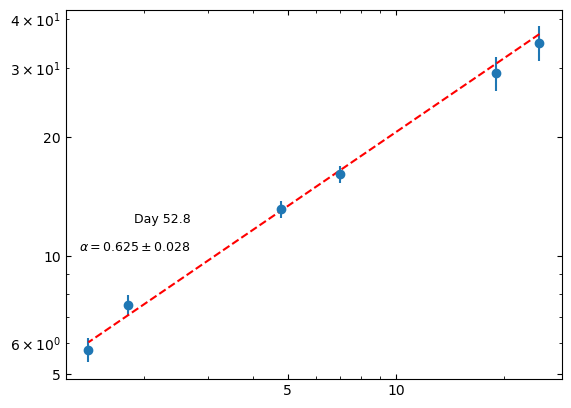

In [124]:
#plotting to check
fig,ax = plt.subplots()
mask = df11['Flux'] > 3 * df11['Error (gaussfit or image)']  # apply detection threshold
mask2 = df11['Flux'] < 3 * df11['Error (gaussfit or image)']  # apply detection threshold
if mask.any():  # proceed only if at least one detection
    ax.errorbar(df11['Freq'][mask], df11['Flux'][mask], yerr=yerr11, fmt='o')
    ax.scatter(df11['Freq'][mask2], (df11['Flux'][mask2] + 3*df11['Error (gaussfit or image)'][mask2]), marker='v')
    ax.set_xscale('log')
    ax.set_xticks([1, 5, 10, 50], labels=['1', '5', '10', '50'])
    ax.set_yscale('log')
    ax.set_yticks([1, 5, 10, 20, 50], labels=['1', '5', '10', '20', '50'])
    ax.annotate('Day 52.8', xy=(90, 120), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
    ax.tick_params(axis='both', which='both', direction='in', top=True, right=True)
    ax.plot(df11['Freq'][mask], fit_model_weights11(df11['Freq'][mask]), 'r--')
    ax.annotate('${\u03B1 = 0.625 \\pm 0.028}$', xy=(90, 100), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))

plt.show();


---

### Day 57.8 (df12)

In [125]:
mask = df12['Flux'] > 3 * df12['Error (gaussfit or image)']  # apply detection threshold

x12 = df12['Freq'][mask].values.tolist()
y12 = df12['Flux'][mask].values.tolist()
yerr12 = df12['Error (gaussfit or image)'][mask].values.tolist()

In [126]:
yerr12 = error(yerr12, x12, y12)

In [129]:


PL12 =  PowerLaw1D(amplitude = y12[0], x_0= x12[0], alpha= -0.7) 

#Initialize fitters
#setting calc_uncertainties=True to output errors on measurement 

fit12 = fitting.LevMarLSQFitter(calc_uncertainties=True)

#Fit the data w/o weights
fit_model12 = fit12(PL12, x12, y12)


#weight is 1/error^2
y_weight12 = 1/ (np.power(yerr12, 2))  

# fit the data using the uncertainties as weights
fit_model_weights12 = fit12(PL12, x12, y12, weights=y_weight12)

fit_model_weights12


<PowerLaw1D(amplitude=61.86845055, x_0=56.78327923, alpha=-0.60748667)>

In [130]:
fit12.fit_info

{'nfev': 15,
 'fvec': array([ 0.92991587,  0.52340912,  0.22627025, -0.7216392 , -0.21867988,
         0.43315885]),
 'fjac': array([[-1.81709111e+02, -9.11944176e-01,  6.03606320e-01,
          3.68429461e-01,  5.65141182e-01,  6.86370431e-01],
        [-9.11944176e-01, -2.01059409e-01,  1.33079121e-01,
          4.13765791e-01, -3.14880392e-01, -5.79590969e-01],
        [ 6.03606320e-01,  1.33079121e-01,  1.18977246e-16,
          6.41533028e-01,  2.91605922e-01,  6.99854212e-01]]),
 'ipvt': array([2, 0, 1], dtype=int32),
 'qtf': array([-1.78883489e-05, -3.96761018e-06,  9.62576377e-01]),
 'message': 'Both actual and predicted relative reductions in the sum of squares\n  are at most 0.000000',
 'ierr': 1,
 'param_jac': None,
 'param_cov': array([[ 3.09487580e+31,  4.67581909e+31, -2.49760668e+13],
        [ 4.67581909e+31,  7.06434947e+31, -3.77344933e+13],
        [-2.49760668e+13, -3.77344933e+13,  6.73508707e-04]]),
 'njev': 7,
 'cov_x': array([[ 3.09487580e+31,  4.67581909e+31, -

In [131]:
#taking fvec
fvec12 = np.array([ 0.92991752,  0.5234107 ,  0.22627921, -0.72162883, -0.21866847,
         0.43317177])
var12 = np.var(fvec12)

#taking cov_x
cov_x12 = np.array([[3.80716948e+31, 4.82249071e+31, 2.69867932e+13],
        [4.82249071e+31, 6.10858454e+31, 3.41838104e+13],
        [2.69867932e+13, 3.41838104e+13, 6.72481539e-04]])

def stand(cov):
    diag = np.diagonal(cov)
    sd1 = np.sqrt(diag[0])
    sd2 = np.sqrt(diag[1])
    sd3 = np.sqrt(diag[2])
    return(sd1,sd2,sd3)

diag12 = stand(cov_x12*var12) 

#The last diagonal element corresponds to alpha
#So here we are calculating the standard deviation on the slope

#print(diag)  #prints standard deviations of all three variances

print('The error/standard deviation is', diag12[2]) #Just showing the standard deviation on the slope



The error/standard deviation is 0.013872301096853725


In [132]:
Xhi = cs(df12['Flux'], fit_model_weights12( df12["Freq"] ))
print("The chi squared is", Xhi/(6-4))

The chi squared is 1.1342590118466986


In [133]:
#Will output many BPL functions 
#Check through them, if they are very far off they won't work in fitBPL
BM12 = bpl_func(x_val, y12, yerr12, a1, a2)

#BM3[43] worked for me and gives me a reasonable output in fitBPL
BM12[50]

#Apply error as weighting in the function 

weight12 = 1/ (np.power(yerr12,2))
fw_BPL12 = fitBPL(BM12[50], x12, y12, weights=weight12)   
print(fw_BPL12)
print("")
print(fitBPL.fit_info)

"""
#taking fvec
fvec4 = np.array(   )
var4 = np.var(fvec4)

#taking cov_x
cov_x4 = np.array(   )

def stand(cov):
    diag = np.diagonal(cov)
    sd1 = np.sqrt(diag[0])
    sd2 = np.sqrt(diag[1])
    sd3 = np.sqrt(diag[2]) #err 1
    sd4 = np.sqrt(diag[3]) #err 2
    return(sd1,sd2,sd3, sd4)

diag4 = stand(cov_x4*var4) 

#The last diagonal element corresponds to alpha
#So here we are calculating the standard deviation on the slope

#print(diag)  #prints standard deviations of all three variances
print("")
print('The error/standard deviation of the first one is', diag4[2], diag4[3]) #Just showing the standard deviation on the slope
"""

Xhi = cs(df12['Flux'], fw_BPL12( df12["Freq"] ))
print("")
print("The chi squared is", Xhi/(6-4))

"""
#for plotting
x_freq = np.arange(1,36,0.5)

    #in the if
    ax.plot(df3['Freq'][mask], fw_BPL3(df3['Freq'][mask]), 'b--')
    ax.annotate('${\u03B1_1 = 0.68 \\pm 0.006}$', xy=(90, 160), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
    ax.annotate('${\u03B1_2 = 0.82 \\pm 0.21}$', xy=(90, 140), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
""";

Model: BrokenPowerLaw1D
Inputs: ('x',)
Outputs: ('y',)
Model set size: 1
Parameters:
        amplitude           x_break            alpha_1             alpha_2      
    ------------------ ----------------- ------------------- -------------------
    15.326687600587578 5.419819811264711 -0.6367509902178516 -0.4463759753092813

{'nfev': 7, 'fvec': array([ 0.09565867, -0.12228223,  0.00395   ,  0.05132383, -0.23584201,
        0.16705912]), 'fjac': array([[-5.59623313e+01,  0.00000000e+00,  0.00000000e+00,
         6.04823837e-02,  5.85700166e-01,  8.08268023e-01],
       [ 0.00000000e+00,  9.08856694e+00,  6.52935173e-01,
        -3.54538026e-02, -3.43328036e-01, -4.73793742e-01],
       [ 5.41745524e+00,  1.55282405e+00,  3.22380615e+00,
         9.22321938e-01,  1.79649737e-01, -2.97387231e-02],
       [-3.00858472e+00, -1.23014974e+00, -1.89336440e+00,
         2.60865638e-01, -4.82347991e-02, -3.54929316e-01]]), 'ipvt': array([2, 3, 1, 0], dtype=int32), 'qtf': array([-2.31671802e-08

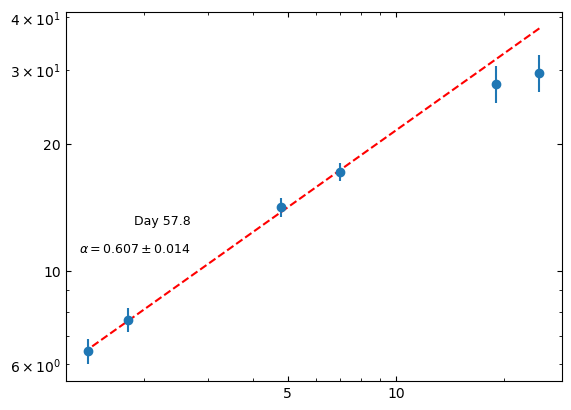

In [134]:
#plotting to check
fig,ax = plt.subplots()
mask = df12['Flux'] > 3 * df12['Error (gaussfit or image)']  # apply detection threshold
mask2 = df12['Flux'] < 3 * df12['Error (gaussfit or image)']  # apply detection threshold
if mask.any():  # proceed only if at least one detection
    ax.errorbar(df12['Freq'][mask], df12['Flux'][mask], yerr=yerr12, fmt='o')
    ax.scatter(df12['Freq'][mask2], (df12['Flux'][mask2] + 3*df12['Error (gaussfit or image)'][mask2]), marker='v')
    ax.set_xscale('log')
    ax.set_xticks([1, 5, 10, 50], labels=['1', '5', '10', '50'])
    ax.set_yscale('log')
    ax.set_yticks([1, 5, 10, 20, 50], labels=['1', '5', '10', '20', '50'])
    ax.annotate('Day 57.8', xy=(90, 120), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
    ax.tick_params(axis='both', which='both', direction='in', top=True, right=True)
    ax.plot(df12['Freq'][mask], fit_model_weights12(df12['Freq'][mask]), 'r--')
    ax.annotate('${\u03B1 = 0.607 \\pm 0.014}$', xy=(90, 100), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))

plt.show();


### Day 61.8-65 (df13)

In [135]:
mask = df13['Flux'] > 3 * df13['Error (gaussfit or image)']  # apply detection threshold

x13 = df13['Freq'][mask].values.tolist()
y13 = df13['Flux'][mask].values.tolist()
yerr13 = df13['Error (gaussfit or image)'][mask].values.tolist()

In [136]:
yerr13 = error(yerr13, x13, y13)

In [137]:


PL13 =  PowerLaw1D(amplitude = y13[0], x_0= x13[0], alpha= -2.3) 

#Initialize fitters
#setting calc_uncertainties=True to output errors on measurement 

fit13 = fitting.LevMarLSQFitter(calc_uncertainties=True)

#Fit the data w/o weights
fit_model13 = fit13(PL13, x13, y13)


#weight is 1/error^2
y_weight13 = 1/ (np.power(yerr13, 2))  

# fit the data using the uncertainties as weights
fit_model_weights13 = fit13(PL13, x13, y13, weights=y_weight13)

fit_model_weights13


<PowerLaw1D(amplitude=59.59964738, x_0=35.38718207, alpha=-0.73798022)>

In [138]:
fit13.fit_info

{'nfev': 20,
 'fvec': array([ 0.78181764,  0.5609058 ,  1.7197816 ,  1.17855048,  0.57859198,
        -2.41379429, -0.18937161,  0.94102742]),
 'fjac': array([[ 1.69760292e+02, -1.23548253e+00,  9.93700592e-01,
         -1.72431079e-02, -1.88593386e-01, -2.81068018e-01,
         -6.32407965e-01, -6.96471012e-01],
        [-1.23548253e+00,  3.15608292e-01, -2.53844257e-01,
          2.47831055e-01,  7.11943814e-01,  5.35268001e-01,
          3.24564150e-02, -1.68746746e-01],
        [ 9.93700592e-01, -2.53844257e-01,  1.75207071e-16,
          2.37623762e-01,  3.16831683e-01,  1.58415842e-01,
          3.66336634e-01,  7.92079208e-01]]),
 'ipvt': array([2, 1, 0], dtype=int32),
 'qtf': array([ 1.90274113e-04, -5.69645331e-05, -1.71050832e+00]),
 'message': 'Both actual and predicted relative reductions in the sum of squares\n  are at most 0.000000',
 'ierr': 1,
 'param_jac': None,
 'param_cov': array([[3.25759238e+31, 2.62008680e+31, 5.36370930e+13],
        [2.62008680e+31, 2.10734003e+

In [139]:
#taking fvec
fvec13 = np.array([ 0.78181948,  0.56090748,  1.71978501,  1.17855369,  0.57860662,
        -2.41377788, -0.18934673,  0.94105272])
var13 = np.var(fvec13)

#taking cov_x
cov_x13 = np.array([[ 6.38560720e+31,  5.07699907e+31, -1.08828412e+14],
        [ 5.07699907e+31,  4.03656515e+31, -8.65261091e+13],
        [-1.08828412e+14, -8.65261091e+13,  7.51922467e-04]])

def stand(cov):
    diag = np.diagonal(cov)
    sd1 = np.sqrt(diag[0])
    sd2 = np.sqrt(diag[1])
    sd3 = np.sqrt(diag[2])
    return(sd1,sd2,sd3)

diag13 = stand(cov_x13*var13) 

#The last diagonal element corresponds to alpha
#So here we are calculating the standard deviation on the slope

#print(diag)  #prints standard deviations of all three variances

print('The error/standard deviation is', diag13[2]) #Just showing the standard deviation on the slope



The error/standard deviation is 0.03231275835660854


In [140]:
Xhi = cs(df13['Flux'], fit_model_weights13( df13["Freq"] ))
print("The chi squared is", Xhi/(8-4))

The chi squared is 4.317295554774775


In [141]:
#Will output many BPL functions 
#Check through them, if they are very far off they won't work in fitBPL
BM13 = bpl_func(x_val, y13, yerr13, a1, a2)

#BM3[43] worked for me and gives me a reasonable output in fitBPL
BM13[50]

#Apply error as weighting in the function 

weight13 = 1/ (np.power(yerr13,2))
fw_BPL13 = fitBPL(BM13[50], x13, y13, weights=weight13)   
print(fw_BPL13)
print("")
print(fitBPL.fit_info)


#taking fvec
fvec4 = np.array( [-2.41395036e-01, -3.32864578e-01,  3.32816184e-01,  1.21877572e-01,
       -5.51824878e-02,  1.60342684e-02,  0.00000000e+00,  5.91763642e-15]  )
var4 = np.var(fvec4)

#taking cov_x
cov_x4 = np.array( [[ 1.05777614e+01,  6.22498871e+00,  4.62145786e-01,
         7.71875778e-02],
       [ 6.22498871e+00,  3.77556851e+00,  2.92979935e-01,
         2.74174883e-02],
       [ 4.62145786e-01,  2.92979935e-01,  2.44887262e-02,
        -5.20417043e-18],
       [ 7.71875778e-02,  2.74174883e-02, -5.20417043e-18,
         7.55470403e-03]]  )

def stand(cov):
    diag = np.diagonal(cov)
    sd1 = np.sqrt(diag[0])
    sd2 = np.sqrt(diag[1])
    sd3 = np.sqrt(diag[2]) #err 1
    sd4 = np.sqrt(diag[3]) #err 2
    return(sd1,sd2,sd3, sd4)

diag4 = stand(cov_x4*var4) 

#The last diagonal element corresponds to alpha
#So here we are calculating the standard deviation on the slope

#print(diag)  #prints standard deviations of all three variances
print("")
print('The error/standard deviation of the first one is', diag4[2], diag4[3]) #Just showing the standard deviation on the slope


Xhi = cs(df13['Flux'], fw_BPL13( df13["Freq"] ))
print("")
print("The chi squared is", Xhi/(8-4))

"""
#for plotting
x_freq = np.arange(1,36,0.5)

    #in the if
    ax.plot(df3['Freq'][mask], fw_BPL3(df3['Freq'][mask]), 'b--')
    ax.annotate('${\u03B1_1 = 0.68 \\pm 0.006}$', xy=(90, 160), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
    ax.annotate('${\u03B1_2 = 0.82 \\pm 0.21}$', xy=(90, 140), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
""";

Model: BrokenPowerLaw1D
Inputs: ('x',)
Outputs: ('y',)
Model set size: 1
Parameters:
        amplitude           x_break             alpha_1             alpha_2      
    ------------------ ------------------ ------------------- -------------------
    14.459969727417942 4.4295774805820285 -0.8624117480446257 -0.4832101372978526

{'nfev': 8, 'fvec': array([-2.41395036e-01, -3.32864578e-01,  3.32816184e-01,  1.21877572e-01,
       -5.51824878e-02,  1.60342684e-02,  0.00000000e+00, -5.91763642e-15]), 'fjac': array([[-52.48157232,   0.        ,   0.        ,   0.        ,
          0.        ,   0.        ,   0.62195801,   0.7830506 ],
       [  0.        ,  15.61578701,   0.4022627 ,   0.3412129 ,
          0.76820057,   0.13540601,  -0.15606989,  -0.19649336],
       [  9.82862225,   2.50673253,  -2.98571701,   0.11631928,
         -0.19468264,  -0.86272534,  -0.39216562,   0.15554673],
       [ -3.49118529,  -1.58915727,   1.75708772,   0.30747026,
         -0.07394845,  -0.32769847,  

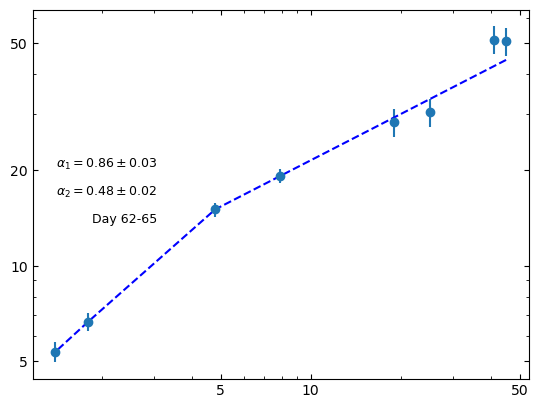

In [142]:
#plotting to check
fig,ax = plt.subplots()
mask = df13['Flux'] > 3 * df13['Error (gaussfit or image)']  # apply detection threshold
mask2 = df13['Flux'] < 3 * df13['Error (gaussfit or image)']  # apply detection threshold
if mask.any():  # proceed only if at least one detection
    ax.errorbar(df13['Freq'][mask], df13['Flux'][mask], yerr=yerr13, fmt='o')
    ax.scatter(df13['Freq'][mask2], (df13['Flux'][mask2] + 3*df13['Error (gaussfit or image)'][mask2]), marker='v')
    ax.set_xscale('log')
    ax.set_xticks([1, 5, 10, 50], labels=['1', '5', '10', '50'])
    ax.set_yscale('log')
    ax.set_yticks([1, 5, 10, 20, 50], labels=['1', '5', '10', '20', '50'])
    ax.annotate('Day 62-65', xy=(90, 120), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
    ax.tick_params(axis='both', which='both', direction='in', top=True, right=True)
    #ax.plot(df13['Freq'][mask], fit_model_weights13(df13['Freq'][mask]), 'r--')
    #ax.annotate('${\u03B1 = 0.738 \\pm 0.032}$', xy=(90, 100), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
    ax.plot(df13['Freq'][mask], fw_BPL13(df13['Freq'][mask]), 'b--')
    ax.annotate('${\u03B1_1 = 0.86 \\pm 0.03}$', xy=(90, 160), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
    ax.annotate('${\u03B1_2 = 0.48 \\pm 0.02}$', xy=(90, 140), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))

plt.show();


### Day 66.7 (df14)

In [143]:
mask = df14['Flux'] > 3 * df14['Error (gaussfit or image)']  # apply detection threshold

x14 = df14['Freq'][mask].values.tolist()
y14 = df14['Flux'][mask].values.tolist()
yerr14 = df14['Error (gaussfit or image)'][mask].values.tolist()

In [144]:
yerr14 = error(yerr14, x14, y14)

In [152]:

PL14 =  PowerLaw1D(amplitude = y14[0], x_0= x14[0], alpha= -1.7) 

#Initialize fitters
#setting calc_uncertainties=True to output errors on measurement 

fit14 = fitting.LevMarLSQFitter(calc_uncertainties=True)

#Fit the data w/o weights
fit_model14 = fit14(PL14, x14, y14)


#weight is 1/error^2
y_weight14 = 1/ (np.power(yerr14, 2))  

# fit the data using the uncertainties as weights
fit_model_weights14 = fit14(PL14, x14, y14, weights=y_weight14)

fit_model_weights14


<PowerLaw1D(amplitude=61.46391386, x_0=39.78477836, alpha=-0.68991857)>

In [153]:
fit14.fit_info

{'nfev': 24,
 'fvec': array([ 0.94389078,  0.8689975 ,  1.79496234,  0.9862834 ,  0.2707174 ,
        -1.91294818, -1.47803984,  1.8640867 ]),
 'fjac': array([[ 1.74842012e+02, -1.00915426e+00,  9.46796080e-01,
         -1.88562322e-02, -1.85306407e-01, -2.77382993e-01,
         -6.09347654e-01, -7.18932047e-01],
        [-1.00915426e+00,  2.46261469e-01, -2.31044355e-01,
          2.41090233e-01,  6.93458446e-01,  5.40335314e-01,
          6.30447105e-02, -1.40311274e-01],
        [ 9.46796080e-01, -2.31044355e-01, -1.13607834e-16,
         -6.10776007e-02, -4.88620805e-01,  6.10776007e-01,
          3.81735004e-01, -4.88620805e-01]]),
 'ipvt': array([2, 1, 0], dtype=int32),
 'qtf': array([ 2.32008310e-05, -5.69209041e-06,  2.92382069e+00]),
 'message': 'Both actual and predicted relative reductions in the sum of squares\n  are at most 0.000000',
 'ierr': 1,
 'param_jac': None,
 'param_cov': array([[7.74788993e+31, 7.26912835e+31, 8.94708207e+13],
        [7.26912835e+31, 6.81995065e+

In [154]:

#taking fvec
fvec14 = np.array([ 0.94389147,  0.8689982 ,  1.79496352,  0.9862844 ,  0.27072187,
        -1.9129431 , -1.47803231,  1.8640949 ])
var14 = np.var(fvec14)

#taking cov_x
cov_x14 = np.array([[4.61986652e+31, 4.34761504e+31, 2.03908142e+14],
        [4.34761504e+31, 4.09140749e+31, 1.91891714e+14],
        [2.03908142e+14, 1.91891714e+14, 1.48203258e-03]])

def stand(cov):
    diag = np.diagonal(cov)
    sd1 = np.sqrt(diag[0])
    sd2 = np.sqrt(diag[1])
    sd3 = np.sqrt(diag[2])
    return(sd1,sd2,sd3)

diag14 = stand(cov_x14*var14) 

#The last diagonal element corresponds to alpha
#So here we are calculating the standard deviation on the slope

#print(diag)  #prints standard deviations of all three variances

print('The error/standard deviation is', diag14[2]) #Just showing the standard deviation on the slope


The error/standard deviation is 0.050635217434888004


In [155]:
Xhi = cs(df14['Flux'], fit_model_weights14( df14["Freq"] ))
print("The chi squared is", Xhi/(8-4))

The chi squared is 4.662447783291413


In [156]:
#Input values for function above 
#Going through a range of x values (the point where the line breaks)
#And different alpha 1 and alpha 2 values (the alpha values on either side of that break)

x_val = np.arange(1.1,40,0.5)   #Going through a range of freq values from 0.1 to 40
                                #because thats what my data ranges from, may be different for you
    
a1 = np.arange(-1,0,0.2)
a2 = np.arange(0,1,0.2)



#Will output many BPL functions 
#Check through them, if they are very far off they won't work in fitBPL
BM3 = bpl_func(x_val, y14, yerr14, a1, a2)

#BM3[43] worked for me and gives me a reasonable output in fitBPL
BM3[50]

<BrokenPowerLaw1D(amplitude=46.31, x_break=6.1, alpha_1=-1., alpha_2=0.)>

In [157]:
#Apply error as weighting in the function 

weight14 = 1/ (np.power(yerr14,2))
fw_BPL14 = fitBPL(BM3[50], x14, y14, weights=weight14)   
fw_BPL14

<BrokenPowerLaw1D(amplitude=16.52616461, x_break=5.11428215, alpha_1=-0.78542176, alpha_2=-0.4219527)>

In [158]:
fitBPL.fit_info

{'nfev': 7,
 'fvec': array([-2.26330056e-01, -2.49428283e-01,  3.54673281e-01,  3.15011841e-05,
        -2.15823722e-02,  3.91838218e-01, -1.40579500e+00,  1.05039766e+00]),
 'fjac': array([[-5.97114965e+01,  0.00000000e+00,  0.00000000e+00,
          0.00000000e+00,  0.00000000e+00,  2.68040799e-02,
          6.03127622e-01,  7.97194213e-01],
        [ 0.00000000e+00,  1.27904478e+01,  4.68007785e-01,
          3.56534704e-01,  6.71394718e-01, -8.63597852e-03,
         -1.94321059e-01, -2.56847172e-01],
        [ 7.79657882e+00,  1.44254527e+00, -3.86381060e+00,
          3.82307684e-02, -2.09994344e-01, -9.50636357e-01,
         -1.90626322e-01,  9.94995802e-02],
        [-3.07194591e+00, -1.05797953e+00,  1.59292565e+00,
          2.95847848e-01, -8.25426727e-01,  4.69854479e-01,
         -6.77589803e-02, -2.65958493e-01]]),
 'ipvt': array([2, 3, 1, 0], dtype=int32),
 'qtf': array([ 5.08159471e-07, -3.12802156e-06,  3.56753694e-07, -5.01877967e-06]),
 'message': 'Both actual and pre

In [159]:
#taking fvec
fvec14 = np.array([-2.26330056e-01, -2.49428283e-01,  3.54673281e-01,  3.15011841e-05,
        -2.15823722e-02,  3.91838218e-01, -1.40579500e+00,  1.05039766e+00])
var14 = np.var(fvec14)

#taking cov_x
cov_x14 = np.array([[ 1.14251831e+01,  4.71023795e+00,  2.72342343e-02,
          4.13814937e-01],
        [ 4.71023795e+00,  2.00886419e+00,  1.99739051e-02,
          1.63048066e-01],
        [ 2.72342343e-02,  1.99739051e-02,  1.48737227e-03,
         -9.54097912e-18],
        [ 4.13814937e-01,  1.63048066e-01, -9.54097912e-18,
          2.19528560e-02]])

def stand(cov):
    diag = np.diagonal(cov)
    sd1 = np.sqrt(diag[0])
    sd2 = np.sqrt(diag[1])
    sd3 = np.sqrt(diag[2]) #err 1
    sd4 = np.sqrt(diag[3]) #err 2
    return(sd1,sd2,sd3, sd4)

diag14 = stand(cov_x14*var14) 

#The last diagonal element corresponds to alpha
#So here we are calculating the standard deviation on the slope

#print(diag)  #prints standard deviations of all three variances

print('The error/standard deviation of the first one is', diag14[2], diag14[3]) #Just showing the standard deviation on the slope



The error/standard deviation of the first one is 0.02540495865183501 0.09760097733418462


In [160]:
Xhi = cs(df14['Flux'], fw_BPL14( df14["Freq"] ))
print("The chi squared is", Xhi/(8-4))

The chi squared is 0.38911529470226264


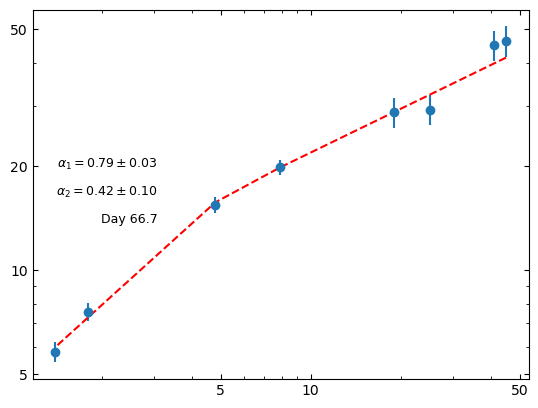

In [161]:
x_freq = np.arange(1,36,0.5)

#plotting to check
fig,ax = plt.subplots()
mask = df14['Flux'] > 3 * df14['Error (gaussfit or image)']  # apply detection threshold
mask2 = df14['Flux'] < 3 * df14['Error (gaussfit or image)']  # apply detection threshold
if mask.any():  # proceed only if at least one detection
    ax.errorbar(df14['Freq'][mask], df14['Flux'][mask], yerr=yerr14, fmt='o')
    ax.scatter(df14['Freq'][mask2], (df14['Flux'][mask2] + 3*df14['Error (gaussfit or image)'][mask2]), marker='v')
    ax.set_xscale('log')
    ax.set_xticks([1, 5, 10, 50], labels=['1', '5', '10', '50'])
    ax.set_yscale('log')
    ax.set_yticks([1, 5, 10, 20, 50], labels=['1', '5', '10', '20', '50'])
    ax.annotate('Day 66.7', xy=(90, 120), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
    ax.tick_params(axis='both', which='both', direction='in', top=True, right=True)
    ax.plot(df14['Freq'][mask], fw_BPL14(df14['Freq'][mask]), 'r--')

    ax.annotate('${\u03B1_1 = 0.79 \\pm 0.03}$', xy=(90, 160), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
    ax.annotate('${\u03B1_2 = 0.42 \\pm 0.10}$', xy=(90, 140), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))

    #ax.annotate('${\u03B1 = 0.690 \\pm 0.051}$', xy=(90, 100), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))

plt.show();


### Day 75.7 (df15)

In [162]:
mask = df15['Flux'] > 3 * df15['Error (gaussfit or image)']  # apply detection threshold

x15 = df15['Freq'][mask].values.tolist()
y15 = df15['Flux'][mask].values.tolist()
yerr15 = df15['Error (gaussfit or image)'][mask].values.tolist()

In [163]:
yerr15 = error(yerr15, x15, y15)

In [175]:

#(work for anything with 3+ points)
PL15 =  PowerLaw1D(amplitude = y15[0], x_0= x15[0], alpha= -2.694) 

#Initialize fitters
#setting calc_uncertainties=True to output errors on measurement 

fit15 = fitting.LevMarLSQFitter(calc_uncertainties=True)

#Fit the data w/o weights
fit_model15 = fit15(PL15, x15, y15)


#weight is 1/error^2
y_weight15 = 1/ (np.power(yerr15, 2))  

# fit the data using the uncertainties as weights
fit_model_weights15 = fit15(PL15, x15, y15, weights=y_weight15)

fit_model_weights15


<PowerLaw1D(amplitude=55.50207068, x_0=31.74765896, alpha=-0.69409263)>

In [176]:
fit15.fit_info

{'nfev': 22,
 'fvec': array([ 2.131769  ,  1.61533725,  2.19618417,  1.3049965 , -0.48468291,
        -3.18802549, -2.08130272,  2.88247169]),
 'fjac': array([[ 1.54022289e+02, -1.19037789e+00,  9.81002111e-01,
         -1.60929481e-02, -1.61115103e-01, -2.39828390e-01,
         -6.14554738e-01, -7.33725524e-01],
        [-1.19037789e+00,  3.30376027e-01, -2.72266128e-01,
          2.67043308e-01,  6.55381794e-01,  5.12087613e-01,
          1.79109917e-01,  4.04303469e-03],
        [ 9.81002111e-01, -2.72266128e-01, -7.53270088e-17,
          0.00000000e+00,  3.68467779e-01,  0.00000000e+00,
          1.84233889e-01, -8.92382902e-01]]),
 'ipvt': array([2, 1, 0], dtype=int32),
 'qtf': array([6.95312738e-05, 4.75581409e-07, 4.15837016e+00]),
 'message': 'Both actual and predicted relative reductions in the sum of squares\n  are at most 0.000000',
 'ierr': 1,
 'param_jac': None,
 'param_cov': array([[ 1.76237594e+32,  1.45239132e+32, -3.64005549e+14],
        [ 1.45239132e+32,  1.19692995

In [177]:
#taking fvec
fvec15 = np.array([ 2.13182647,  1.61538608,  2.19624271,  1.3050419 , -0.48456809,
        -3.18793257, -2.08125534,  2.88249296])
var15 = np.var(fvec15)

#taking cov_x
cov_x15 = np.array([[ 9.51585387e+31,  7.91402241e+31, -1.12684806e+13],
        [ 7.91402241e+31,  6.58183191e+31, -9.37162440e+12],
        [-1.12684806e+13, -9.37162440e+12,  5.90729638e-04]])

def stand(cov):
    diag = np.diagonal(cov)
    sd1 = np.sqrt(diag[0])
    sd2 = np.sqrt(diag[1])
    sd3 = np.sqrt(diag[2])
    return(sd1,sd2,sd3)

diag15 = stand(cov_x15*var15) 

#The last diagonal element corresponds to alpha
#So here we are calculating the standard deviation on the slope

#print(diag)  #prints standard deviations of all three variances

print('The error/standard deviation is', diag15[2]) #Just showing the standard deviation on the slope

Xhi = cs(df15['Flux'], fit_model_weights15( df15["Freq"] ))

print("The chi squared is", Xhi/(8-4))

The error/standard deviation is 0.05034396869165565
The chi squared is 8.897879797058883


In [178]:
#Input values for function above 
#Going through a range of x values (the point where the line breaks)
#And different alpha 1 and alpha 2 values (the alpha values on either side of that break)

x_val = np.arange(1.1,40,0.5)   #Going through a range of freq values from 0.1 to 40
                                #because thats what my data ranges from, may be different for you
    
a1 = np.arange(-1,0,0.2)
a2 = np.arange(0,1,0.2)



#Will output many BPL functions 
#Check through them, if they are very far off they won't work in fitBPL
BM3 = bpl_func(x_val, y15, yerr15, a1, a2)

#BM3[43] worked for me and gives me a reasonable output in fitBPL
BM3[50]

<BrokenPowerLaw1D(amplitude=39.97, x_break=6.1, alpha_1=-1., alpha_2=0.)>

In [179]:
#Apply error as weighting in the function 

weight15 = 1/ (np.power(yerr15,2))
fw_BPL15 = fitBPL(BM3[50], x15, y15, weights=weight15)   
fw_BPL15

<BrokenPowerLaw1D(amplitude=19.01528328, x_break=5.17046886, alpha_1=-0.86877898, alpha_2=-0.31029658)>

In [180]:
fitBPL.fit_info

{'nfev': 6,
 'fvec': array([-0.07838846, -0.23435243,  0.26624531,  0.01449851, -0.01823203,
         0.5632987 , -1.94330027,  1.47237934]),
 'fjac': array([[-5.73659691e+01,  0.00000000e+00,  0.00000000e+00,
          0.00000000e+00,  0.00000000e+00,  3.02037476e-02,
          6.09177006e-01,  7.92458900e-01],
        [ 0.00000000e+00,  1.28628666e+01,  4.57895406e-01,
          3.57942218e-01,  6.03304724e-01, -1.24750863e-02,
         -2.51609033e-01, -3.27310150e-01],
        [ 8.14133888e+00,  9.49978933e-01, -3.82610110e+00,
          1.91707924e-02, -1.61312312e-01, -9.60575236e-01,
         -1.87208646e-01,  1.20409303e-01],
        [-2.54810705e+00, -8.32454403e-01,  1.26220622e+00,
          3.67771913e-01, -8.84341759e-01,  3.54794699e-01,
         -9.92714335e-02, -2.66758428e-01]]),
 'ipvt': array([2, 3, 1, 0], dtype=int32),
 'qtf': array([-6.91555435e-05, -2.22716119e-05, -8.62280598e-05, -4.75078479e-06]),
 'message': 'Both actual and predicted relative reductions in th

In [181]:
#taking fvec
fvec15 = np.array([-0.07838846, -0.23435243,  0.26624531,  0.01449851, -0.01823203,
         0.5632987 , -1.94330027,  1.47237934])
var15 = np.var(fvec15)

#taking cov_x
cov_x15 = np.array([[ 7.39337753e+00,  2.43902785e+00,  1.77428337e-02,
          2.98349094e-01],
        [ 2.43902785e+00,  8.72930096e-01,  1.55478185e-02,
          9.33784285e-02],
        [ 1.77428337e-02,  1.55478185e-02,  1.72229911e-03,
         -4.66206934e-18],
        [ 2.98349094e-01,  9.33784285e-02, -4.66206934e-18,
          1.84560450e-02]])

def stand(cov):
    diag = np.diagonal(cov)
    sd1 = np.sqrt(diag[0])
    sd2 = np.sqrt(diag[1])
    sd3 = np.sqrt(diag[2]) #err 1
    sd4 = np.sqrt(diag[3]) #err 2
    return(sd1,sd2,sd3, sd4)

diag15 = stand(cov_x15*var15) 

#The last diagonal element corresponds to alpha
#So here we are calculating the standard deviation on the slope

#print(diag)  #prints standard deviations of all three variances

print('The error/standard deviation of the first one is', diag15[2], diag15[3]) #Just showing the standard deviation on the slope

Xhi = cs(df15['Flux'], fw_BPL15( df15["Freq"] ))
print("The chi squared is", Xhi/(8-4))

The error/standard deviation of the first one is 0.03710154989081352 0.1214526748225166
The chi squared is 0.1616076387825314


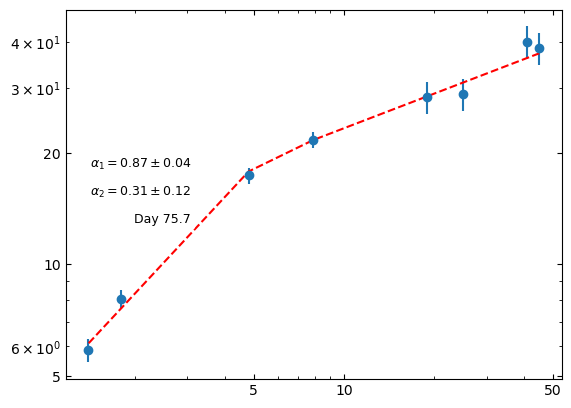

In [182]:
#plotting to check
fig,ax = plt.subplots()
mask = df15['Flux'] > 3 * df15['Error (gaussfit or image)']  # apply detection threshold
mask2 = df15['Flux'] < 3 * df15['Error (gaussfit or image)']  # apply detection threshold
if mask.any():  # proceed only if at least one detection
    ax.errorbar(df15['Freq'][mask], df15['Flux'][mask], yerr=yerr15, fmt='o')
    ax.scatter(df15['Freq'][mask2], (df15['Flux'][mask2] + 3*df15['Error (gaussfit or image)'][mask2]), marker='v')
    ax.set_xscale('log')
    ax.set_xticks([1, 5, 10, 50], labels=['1', '5', '10', '50'])
    ax.set_yscale('log')
    ax.set_yticks([1, 5, 10, 20, 50], labels=['1', '5', '10', '20', '50'])
    ax.annotate('Day 75.7', xy=(90, 120), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
    ax.tick_params(axis='both', which='both', direction='in', top=True, right=True)
    ax.plot(df15['Freq'][mask], fw_BPL15(df15['Freq'][mask]), 'r--')
    #ax.annotate('${\u03B1 = 0.694 \\pm 0.050}$', xy=(90, 100), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
    ax.annotate('${\u03B1_1 = 0.87 \\pm 0.04}$', xy=(90, 160), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
    ax.annotate('${\u03B1_2 = 0.31 \\pm 0.12}$', xy=(90, 140), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))

plt.show();


### Day 79.7 (df16)

In [183]:
mask = df16['Flux'] > 3 * df16['Error (gaussfit or image)']  # apply detection threshold

x16 = df16['Freq'][mask].values.tolist()
y16 = df16['Flux'][mask].values.tolist()
yerr16 = df16['Error (gaussfit or image)'][mask].values.tolist()

In [184]:
yerr16 = error(yerr16, x16, y16)

In [186]:
#(work for anything with 3+ points)


PL16 =  PowerLaw1D(amplitude = y16[0], x_0= x16[0], alpha= -2.6) 

#Initialize fitters
#setting calc_uncertainties=True to output errors on measurement 

fit16 = fitting.LevMarLSQFitter(calc_uncertainties=True)

#Fit the data w/o weights
fit_model16 = fit16(PL16, x16, y16)


#weight is 1/error^2
y_weight16 = 1/ (np.power(yerr16, 2))  

# fit the data using the uncertainties as weights
fit_model_weights16 = fit16(PL16, x16, y16, weights=y_weight16)

fit_model_weights16


<PowerLaw1D(amplitude=67.43520288, x_0=47.40342825, alpha=-0.67840406)>

In [187]:
fit16.fit_info

{'nfev': 21,
 'fvec': array([ 2.20771581,  1.71239478,  2.1367748 ,  1.33701086, -0.57159473,
        -4.05604954, -0.91075987,  2.09579673]),
 'fjac': array([[-1.76819938e+02, -8.17214149e-01,  7.88992117e-01,
          2.62159850e-02,  1.86386776e-01,  2.33745039e-01,
          6.15590632e-01,  7.28378702e-01],
        [-8.17214149e-01, -1.99822602e-01,  1.92921840e-01,
          2.60461509e-01,  5.37840347e-01,  3.01305675e-01,
         -2.66041083e-01, -5.23602269e-01],
        [ 7.88992117e-01,  1.92921840e-01, -6.39734408e-17,
         -1.08465229e-01,  0.00000000e+00,  4.33860916e-01,
          2.16930458e-01, -8.67721831e-01]]),
 'ipvt': array([2, 0, 1], dtype=int32),
 'qtf': array([-1.91296356e-04, -9.55976244e-06,  3.69004851e+00]),
 'message': 'Both actual and predicted relative reductions in the sum of squares\n  are at most 0.000000',
 'ierr': 1,
 'param_jac': None,
 'param_cov': array([[2.27758269e+32, 2.35905120e+32, 1.24924225e+13],
        [2.35905120e+32, 2.44343382e+

In [188]:
#taking fvec
fvec16 = np.array([ 2.20760043,  1.71229616,  2.13666787,  1.33692841, -0.5717584 ,
        -4.05613481, -0.91064373,  2.09600129])
var16 = np.var(fvec16)

#taking cov_x
cov_x16 = np.array([[ 3.95603570e+31,  3.53542656e+31, -1.15944600e+13],
        [ 3.53542656e+31,  3.15953695e+31, -1.03617270e+13],
        [-1.15944600e+13, -1.03617270e+13,  5.70354430e-04]])

def stand(cov):
    diag = np.diagonal(cov)
    sd1 = np.sqrt(diag[0])
    sd2 = np.sqrt(diag[1])
    sd3 = np.sqrt(diag[2])
    return(sd1,sd2,sd3)

diag16 = stand(cov_x16*var16) 

#The last diagonal element corresponds to alpha
#So here we are calculating the standard deviation on the slope

#print(diag)  #prints standard deviations of all three variances

print('The error/standard deviation is', diag16[2]) #Just showing the standard deviation on the slope
Xhi = cs(df16['Flux'], fit_model_weights16( df16["Freq"] ))
print("The chi squared is", Xhi/(8-4))

The error/standard deviation is 0.04938497046785771
The chi squared is 7.965247559225937


In [189]:
#Input values for function above 
#Going through a range of x values (the point where the line breaks)
#And different alpha 1 and alpha 2 values (the alpha values on either side of that break)

x_val = np.arange(1.1,40,0.5)   #Going through a range of freq values from 0.1 to 40
                                #because thats what my data ranges from, may be different for you
    
a1 = np.arange(-1,0,0.2)
a2 = np.arange(0,1,0.2)



#Will output many BPL functions 
#Check through them, if they are very far off they won't work in fitBPL
BM3 = bpl_func(x_val, y16, yerr16, a1, a2)

#BM3[43] worked for me and gives me a reasonable output in fitBPL
BM3[50]

<BrokenPowerLaw1D(amplitude=37.05, x_break=6.1, alpha_1=-1., alpha_2=0.)>

In [190]:
#Apply error as weighting in the function 

weight16 = 1/ (np.power(yerr16,2))
fw_BPL16 = fitBPL(BM3[50], x16, y16, weights=weight16)   
fw_BPL16

<BrokenPowerLaw1D(amplitude=17.72767294, x_break=4.83199965, alpha_1=-0.88640005, alpha_2=-0.30534565)>

In [191]:
fitBPL.fit_info

{'nfev': 6,
 'fvec': array([-0.06351243, -0.2129583 ,  0.23446822,  0.02966174, -0.01762096,
         0.20077456, -0.65477337,  0.4998269 ]),
 'fjac': array([[-5.45463734e+01,  0.00000000e+00,  0.00000000e+00,
          0.00000000e+00,  0.00000000e+00,  2.71701929e-03,
          6.07298163e-01,  7.94469357e-01],
        [ 0.00000000e+00,  1.46856088e+01,  4.32743479e-01,
          3.51463323e-01,  6.34672103e-01, -1.09309098e-03,
         -2.44323678e-01, -3.19625001e-01],
        [ 8.84668219e+00,  1.07123265e+00, -4.24259054e+00,
          1.88225572e-02, -1.47014107e-01, -9.59299470e-01,
         -2.12320333e-01,  1.07199576e-01],
        [-2.72035606e+00, -9.56231358e-01,  1.36746511e+00,
          3.90024739e-01, -8.81454178e-01,  3.53520279e-01,
         -1.00865362e-01, -2.74138572e-01]]),
 'ipvt': array([2, 3, 1, 0], dtype=int32),
 'qtf': array([-3.27295854e-06, -1.40852218e-05, -3.94642149e-06, -1.75579650e-05]),
 'message': 'Both actual and predicted relative reductions in th

In [192]:
#taking fvec
fvec16 = np.array([-0.06351243, -0.2129583 ,  0.23446822,  0.02966174, -0.01762096,
         0.20077456, -0.65477337,  0.4998269 ])
var16 = np.var(fvec16)

#taking cov_x
cov_x16 = np.array([[ 6.57378792e+00,  2.11885298e+00,  1.57989442e-02,
          2.73483906e-01],
        [ 2.11885298e+00,  7.38502229e-01,  1.41028617e-02,
          8.40963410e-02],
        [ 1.57989442e-02,  1.41028617e-02,  1.83546219e-03,
         -7.37257477e-18],
        [ 2.73483906e-01,  8.40963410e-02, -7.37257477e-18,
          1.63099139e-02]])

def stand(cov):
    diag = np.diagonal(cov)
    sd1 = np.sqrt(diag[0])
    sd2 = np.sqrt(diag[1])
    sd3 = np.sqrt(diag[2]) #err 1
    sd4 = np.sqrt(diag[3]) #err 2
    return(sd1,sd2,sd3, sd4)

diag16 = stand(cov_x16*var16) 

#The last diagonal element corresponds to alpha
#So here we are calculating the standard deviation on the slope

#print(diag)  #prints standard deviations of all three variances

print('The error/standard deviation of the first one is', diag16[2], diag16[3]) #Just showing the standard deviation on the slope

Xhi = cs(df16['Flux'], fw_BPL16( df16["Freq"] ))
print("The chi squared is", Xhi/(8-4))

The error/standard deviation of the first one is 0.013752850145873172 0.040996409617613104
The chi squared is 0.09947762487705326


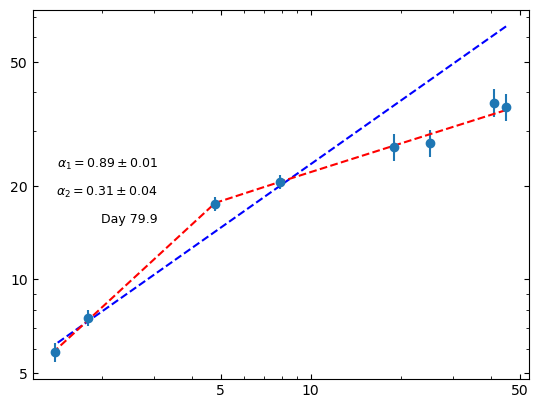

In [193]:
#plotting to check
fig,ax = plt.subplots()
mask = df16['Flux'] > 3 * df16['Error (gaussfit or image)']  # apply detection threshold
mask2 = df16['Flux'] < 3 * df16['Error (gaussfit or image)']  # apply detection threshold
if mask.any():  # proceed only if at least one detection
    ax.errorbar(df16['Freq'][mask], df16['Flux'][mask], yerr=yerr16, fmt='o')
    ax.scatter(df16['Freq'][mask2], (df16['Flux'][mask2] + 3*df16['Error (gaussfit or image)'][mask2]), marker='v')
    ax.set_xscale('log')
    ax.set_xticks([1, 5, 10, 50], labels=['1', '5', '10', '50'])
    ax.set_yscale('log')
    ax.set_yticks([1, 5, 10, 20, 50], labels=['1', '5', '10', '20', '50'])
    ax.annotate('Day 79.9', xy=(90, 120), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
    ax.tick_params(axis='both', which='both', direction='in', top=True, right=True)
    ax.plot(df16['Freq'][mask], fit_model_weights16(df16['Freq'][mask]), 'b--')
    ax.plot(df16['Freq'][mask], fw_BPL16(df16['Freq'][mask]), 'r--')
    
    #ax.annotate('${\u03B1 = 0.678 \\pm 0.049}$', xy=(90, 100), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))

    ax.annotate('${\u03B1_1 = 0.89 \\pm 0.01}$', xy=(90, 160), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
    ax.annotate('${\u03B1_2 = 0.31 \\pm 0.04}$', xy=(90, 140), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
    
plt.show();


### Day 96.7 (df17)

In [194]:
mask = df17['Flux'] > 3 * df17['Error (gaussfit or image)']  # apply detection threshold

x17 = df17['Freq'][mask].values.tolist()
y17 = df17['Flux'][mask].values.tolist()
yerr17 = df17['Error (gaussfit or image)'][mask].values.tolist()


In [195]:
yerr17= error(yerr17, x17, y17)

In [196]:
#(work for anything with 3+ points)

PL17 =  PowerLaw1D(amplitude = y17[0], x_0= x17[0], alpha= -2.5) 

#Initialize fitters
#setting calc_uncertainties=True to output errors on measurement 

fit17 = fitting.LevMarLSQFitter(calc_uncertainties=True)

#Fit the data w/o weights
fit_model17 = fit17(PL17, x17, y17)


#weight is 1/error^2
y_weight17 = 1/ (np.power(yerr17, 2))  

# fit the data using the uncertainties as weights
fit_model_weights17 = fit17(PL17, x17, y17, weights=y_weight17)

fit_model_weights17


<PowerLaw1D(amplitude=25.03687845, x_0=9.08734606, alpha=-0.77441198)>

In [197]:
fit17.fit_info

{'nfev': 18,
 'fvec': array([ 2.22224557, -2.64989851, -1.97447626,  1.88761785]),
 'fjac': array([[-9.58419979e+01,  4.83423656e+00, -2.26508246e+00,
          7.84777638e-01],
        [ 4.83423656e+00,  2.06982621e+00, -9.69817466e-01,
         -8.05863692e-01],
        [-2.26508246e+00, -9.69817466e-01, -4.47545209e-16,
         -4.96138938e-01]]),
 'ipvt': array([2, 1, 0], dtype=int32),
 'qtf': array([-1.97932659e-04, -8.45246271e-05,  2.87177590e+00]),
 'message': 'Both actual and predicted relative reductions in the sum of squares\n  are at most 0.000000',
 'ierr': 1,
 'param_jac': None,
 'param_cov': array([[4.99259313e+30, 2.33928047e+30, 3.41642083e+13],
        [2.33928047e+30, 1.09607031e+30, 1.60076463e+13],
        [3.41642083e+13, 1.60076463e+13, 9.36499343e-04]]),
 'njev': 9,
 'cov_x': array([[4.99259313e+30, 2.33928047e+30, 3.41642083e+13],
        [2.33928047e+30, 1.09607031e+30, 1.60076463e+13],
        [3.41642083e+13, 1.60076463e+13, 9.36499343e-04]])}

In [198]:
#taking fvec
fvec17 = np.array([ 2.22224996, -2.64989443, -1.9744691 ,  1.88762591])
var17 = np.var(fvec17)

#taking cov_x
cov_x17 = np.array([[ 3.39365808e+31,  2.11779632e+31, -5.68532297e+13],
        [ 2.11779632e+31,  1.32160080e+31, -3.54789898e+13],
        [-5.68532297e+13, -3.54789898e+13,  7.97955805e-04]])

def stand(cov):
    diag = np.diagonal(cov)
    sd1 = np.sqrt(diag[0])
    sd2 = np.sqrt(diag[1])
    sd3 = np.sqrt(diag[2])
    return(sd1,sd2,sd3)

diag17 = stand(cov_x17*var17) 

#The last diagonal element corresponds to alpha
#So here we are calculating the standard deviation on the slope

#print(diag)  #prints standard deviations of all three variances

print('The error/standard deviation is', diag17[2]) #Just showing the standard deviation on the slope


The error/standard deviation is 0.062139137344593004


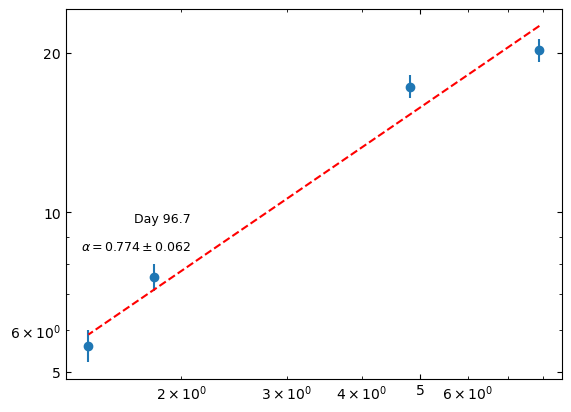

In [199]:
#plotting to check
fig,ax = plt.subplots()
mask = df17['Flux'] > 3 * df17['Error (gaussfit or image)']  # apply detection threshold
mask2 = df17['Flux'] < 3 * df17['Error (gaussfit or image)']  # apply detection threshold
if mask.any():  # proceed only if at least one detection
    ax.errorbar(df17['Freq'][mask], df17['Flux'][mask], yerr=yerr17, fmt='o')
    ax.scatter(df17['Freq'][mask2], (df17['Flux'][mask2] + 3*df17['Error (gaussfit or image)'][mask2]), marker='v')
    ax.set_xscale('log')
    ax.set_xticks([1, 5, 10, 50], labels=['1', '5', '10', '50'])
    ax.set_yscale('log')
    ax.set_yticks([1, 5, 10, 20, 50], labels=['1', '5', '10', '20', '50'])
    ax.annotate('Day 96.7', xy=(90, 120), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
    ax.tick_params(axis='both', which='both', direction='in', top=True, right=True)
    ax.plot(df17['Freq'][mask], fit_model_weights17(df17['Freq'][mask]), 'r--')
    ax.annotate('${\u03B1 = 0.774 \\pm 0.062}$', xy=(90, 100), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))

plt.show();


### Day 101.8 (df18)

In [200]:
mask = df18['Flux'] > 3 * df18['Error (gaussfit or image)']  # apply detection threshold

x18 = df18['Freq'][mask].values.tolist()
y18 = df18['Flux'][mask].values.tolist()
yerr18 = df18['Error (gaussfit or image)'][mask].values.tolist()

In [202]:
yerr18 = error(yerr18, x18, y18)

In [203]:
#(work for anything with 3+ points)


PL18 =  PowerLaw1D(amplitude = y18[0], x_0= x18[0], alpha= -3.5) 

#Initialize fitters
#setting calc_uncertainties=True to output errors on measurement 

fit18 = fitting.LevMarLSQFitter(calc_uncertainties=True)

#Fit the data w/o weights
fit_model18 = fit18(PL18, x18, y18)


#weight is 1/error^2
y_weight18 = 1/ (np.power(yerr18, 2))  

# fit the data using the uncertainties as weights
fit_model_weights18 = fit18(PL18, x18, y18, weights=y_weight18)

fit_model_weights18


<PowerLaw1D(amplitude=28.14340026, x_0=11.51481097, alpha=-0.72693359)>

In [204]:
fit18.fit_info

{'nfev': 19,
 'fvec': array([ 1.31145851, -1.79804723, -1.30632246,  1.16486673]),
 'fjac': array([[-5.89254876e+01,  1.94250868e+00, -1.09332298e+00,
          7.91156825e-01],
        [ 1.94250868e+00,  6.93342391e-01, -3.90241327e-01,
         -8.36924869e-01],
        [-1.09332298e+00, -3.90241327e-01, -7.85046229e-17,
          7.07106781e-01]]),
 'ipvt': array([2, 1, 0], dtype=int32),
 'qtf': array([-4.86893630e-05, -1.83442430e-05,  2.58875832e+00]),
 'message': 'Both actual and predicted relative reductions in the sum of squares\n  are at most 0.000000',
 'ierr': 1,
 'param_jac': None,
 'param_cov': array([[ 1.62259277e+32,  9.13261273e+31, -5.76878251e+14],
        [ 9.13261273e+31,  5.14020627e+31, -3.24690567e+14],
        [-5.76878251e+14, -3.24690567e+14,  4.59957009e-03]]),
 'njev': 11,
 'cov_x': array([[ 1.62259277e+32,  9.13261273e+31, -5.76878251e+14],
        [ 9.13261273e+31,  5.14020627e+31, -3.24690567e+14],
        [-5.76878251e+14, -3.24690567e+14,  4.59957009e-0

In [205]:
#taking fvec
fvec18 = np.array([ 2.37588349, -3.61066221, -1.82877625,  2.10913123])
var18 = np.var(fvec18)

#taking cov_x
cov_x18 = np.array([[ 3.24518554e+30,  1.66632191e+30, -2.49937356e+13],
        [ 1.66632191e+30,  8.55614784e+29, -1.28336605e+13],
        [-2.49937356e+13, -1.28336605e+13,  9.55111661e-04]])

def stand(cov):
    diag = np.diagonal(cov)
    sd1 = np.sqrt(diag[0])
    sd2 = np.sqrt(diag[1])
    sd3 = np.sqrt(diag[2])
    return(sd1,sd2,sd3)

diag18 = stand(cov_x18*var18) 

#The last diagonal element corresponds to alpha
#So here we are calculating the standard deviation on the slope

#print(diag)  #prints standard deviations of all three variances

print('The error/standard deviation is', diag18[2]) #Just showing the standard deviation on the slope



The error/standard deviation is 0.07916541748693731


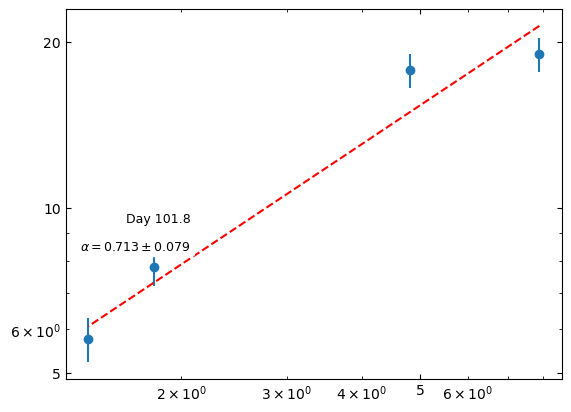

In [206]:
#plotting to check
fig,ax = plt.subplots()
mask = df18['Flux'] > 3 * df18['Error (gaussfit or image)']  # apply detection threshold
mask2 = df18['Flux'] < 3 * df18['Error (gaussfit or image)']  # apply detection threshold
if mask.any():  # proceed only if at least one detection
    ax.errorbar(df18['Freq'][mask], df18['Flux'][mask], yerr=yerr18, fmt='o')
    ax.scatter(df18['Freq'][mask2], (df18['Flux'][mask2] + 3*df18['Error (gaussfit or image)'][mask2]), marker='v')
    ax.set_xscale('log')
    ax.set_xticks([1, 5, 10, 50], labels=['1', '5', '10', '50'])
    ax.set_yscale('log')
    ax.set_yticks([1, 5, 10, 20, 50], labels=['1', '5', '10', '20', '50'])
    ax.annotate('Day 101.8', xy=(90, 120), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
    ax.tick_params(axis='both', which='both', direction='in', top=True, right=True)
    ax.plot(df18['Freq'][mask], fit_model_weights18(df18['Freq'][mask]), 'r--')
    ax.annotate('${\u03B1 = 0.713 \\pm 0.079}$', xy=(90, 100), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))

plt.show();


### Day 102.7 (df19)

In [207]:
mask = df19['Flux'] > 3 * df19['Error (gaussfit or image)']  # apply detection threshold

x19 = df19['Freq'][mask].values.tolist()
y19 = df19['Flux'][mask].values.tolist()
yerr19 = df19['Error (gaussfit or image)'][mask].values.tolist()

In [208]:
yerr19 = error(yerr19, x19, y19)

In [211]:
#(work for anything with 3+ points)

PL19 =  PowerLaw1D(amplitude = y19[0], x_0= x19[0], alpha= -2.6) 

#Initialize fitters
#setting calc_uncertainties=True to output errors on measurement 

fit19 = fitting.LevMarLSQFitter(calc_uncertainties=True)

#Fit the data w/o weights
fit_model19 = fit19(PL19, x19, y19)


#weight is 1/error^2
y_weight19 = 1/ (np.power(yerr19, 2))  

# fit the data using the uncertainties as weights
fit_model_weights19 = fit19(PL19, x19, y19, weights=y_weight19)

fit_model_weights19

<PowerLaw1D(amplitude=33.94551906, x_0=25.05431563, alpha=-0.58413086)>

In [212]:
fit19.fit_info

{'nfev': 19,
 'fvec': array([ 2.31021141,  2.70241632,  2.2633841 ,  1.09912694, -1.15284914,
        -5.79666932, -0.44347212,  2.2782701 ]),
 'fjac': array([[ 1.46018424e+02,  1.64530283e+00, -1.30530022e+00,
         -1.00727489e-02, -1.56289053e-01, -1.87139669e-01,
         -6.43713586e-01, -7.24637412e-01],
        [ 1.64530283e+00, -5.52075756e-01,  4.37989038e-01,
          2.64391509e-01,  6.54509495e-01,  3.98215683e-01,
          2.28877091e-01,  6.94224889e-02],
        [-1.30530022e+00,  4.37989038e-01, -1.45923141e-16,
          3.80413627e-01,  3.80413627e-01,  5.70620441e-01,
         -3.80413627e-01,  3.09086072e-01]]),
 'ipvt': array([2, 0, 1], dtype=int32),
 'qtf': array([-7.85633706e-06, -2.65852527e-04,  2.48964090e+00]),
 'message': 'Both actual and predicted relative reductions in the sum of squares\n  are at most 0.000000',
 'ierr': 1,
 'param_jac': None,
 'param_cov': array([[ 2.95583913e+31,  3.72577161e+31, -1.16712011e+14],
        [ 3.72577161e+31,  4.69625

In [213]:
#taking fvec
fvec19 = np.array([ 2.3102501 ,  2.70245791,  2.26341674,  1.09914822, -1.15283138,
        -5.79668298, -0.44362248,  2.27808379])
var19 = np.var(fvec19)

#taking cov_x
cov_x19 = np.array([[2.10928917e+31, 3.07912594e+31, 1.06757982e+14],
        [3.07912594e+31, 4.49488704e+31, 1.55844573e+14],
        [1.06757982e+14, 1.55844573e+14, 1.00380272e-03]])

def stand(cov):
    diag = np.diagonal(cov)
    sd1 = np.sqrt(diag[0])
    sd2 = np.sqrt(diag[1])
    sd3 = np.sqrt(diag[2])
    return(sd1,sd2,sd3)

diag19 = stand(cov_x19*var19) 

#The last diagonal element corresponds to alpha
#So here we are calculating the standard deviation on the slope

#print(diag)  #prints standard deviations of all three variances

print('The error/standard deviation is', diag19[2]) #Just showing the standard deviation on the slope

Xhi = cs(df19['Flux'], fit_model_weights19( df19["Freq"] ))
print("The chi squared is", Xhi/(8-4))

The error/standard deviation is 0.08527933048827416
The chi squared is 5.75777876098113


In [214]:
#Input values for function above 
#Going through a range of x values (the point where the line breaks)
#And different alpha 1 and alpha 2 values (the alpha values on either side of that break)

x_val = np.arange(1.1,40,0.5)   #Going through a range of freq values from 0.1 to 40
                                #because thats what my data ranges from, may be different for you
    
a1 = np.arange(-1,0,0.2)
a2 = np.arange(0,1,0.2)



#Will output many BPL functions 
#Check through them, if they are very far off they won't work in fitBPL
BM3 = bpl_func(x_val, y19, yerr19, a1, a2)

#BM3[43] worked for me and gives me a reasonable output in fitBPL
BM3[50]

<BrokenPowerLaw1D(amplitude=28.133, x_break=6.1, alpha_1=-1., alpha_2=0.)>

In [215]:
#Apply error as weighting in the function 

weight19 = 1/ (np.power(yerr19,2))
fw_BPL19 = fitBPL(BM3[50], x19, y19, weights=weight19)   
fw_BPL19

<BrokenPowerLaw1D(amplitude=17.09188139, x_break=4.63498218, alpha_1=-0.88777108, alpha_2=-0.16810543)>

In [216]:
fitBPL.fit_info

{'nfev': 7,
 'fvec': array([-3.62793614e-01, -1.80036216e-01,  4.38439303e-02, -2.57528671e-01,
         4.52352187e-01, -3.25113415e-01,  5.53918739e-12,  5.27910378e-12]),
 'fjac': array([[-5.36382671e+01,  0.00000000e+00,  0.00000000e+00,
          0.00000000e+00,  0.00000000e+00,  0.00000000e+00,
          6.38646067e-01,  7.69500618e-01],
        [ 0.00000000e+00,  1.79830258e+01,  4.20889219e-01,
          3.19641461e-01,  6.36845803e-01,  4.29294426e-02,
         -2.37607386e-01, -2.86291641e-01],
        [-2.90549153e+00, -1.19092849e+00,  1.46319163e+00,
          5.16247435e-02, -4.31348134e-01, -8.53537816e-01,
         -2.64329317e-01,  4.78135685e-02],
        [ 9.51179528e+00,  7.38275211e-01, -1.11956156e+00,
          8.83182261e-01, -9.41040943e-02, -1.86210156e-01,
          7.33795598e-01, -6.46442087e-01]]),
 'ipvt': array([2, 3, 0, 1], dtype=int32),
 'qtf': array([-1.32970462e-08, -3.68336535e-05, -2.97778594e-05, -7.16658672e-06]),
 'message': 'Both actual and pre

In [217]:
#taking fvec
fvec19 = np.array([-3.62793614e-01, -1.80036216e-01,  4.38439303e-02, -2.57528671e-01,
         4.52352187e-01, -3.25113415e-01,  5.53918739e-12,  5.27391801e-12])
var19 = np.var(fvec16)

#taking cov_x
cov_x19 = np.array([[1.21765966e+00, 9.80948244e-01, 1.07995268e-01, 4.03678345e-02],
        [9.80948244e-01, 1.28203336e+00, 1.74209618e-01, 1.23308375e-02],
        [1.07995268e-01, 1.74209618e-01, 2.53906467e-02, 6.07153217e-18],
        [4.03678345e-02, 1.23308375e-02, 6.07153217e-18, 5.25938449e-03]])

def stand(cov):
    diag = np.diagonal(cov)
    sd1 = np.sqrt(diag[0])
    sd2 = np.sqrt(diag[1])
    sd3 = np.sqrt(diag[2]) #err 1
    sd4 = np.sqrt(diag[3]) #err 2
    return(sd1,sd2,sd3, sd4)

diag19 = stand(cov_x19*var19) 

#The last diagonal element corresponds to alpha
#So here we are calculating the standard deviation on the slope

#print(diag)  #prints standard deviations of all three variances

print('The error/standard deviation of the first one is', diag19[2], diag19[3]) #Just showing the standard deviation on the slope

Xhi = cs(df19['Flux'], fw_BPL19( df19["Freq"] ))
print("The chi squared is", Xhi/(8-4))

The error/standard deviation of the first one is 0.05115132297966061 0.02328023983822283
The chi squared is 0.1371035501980199


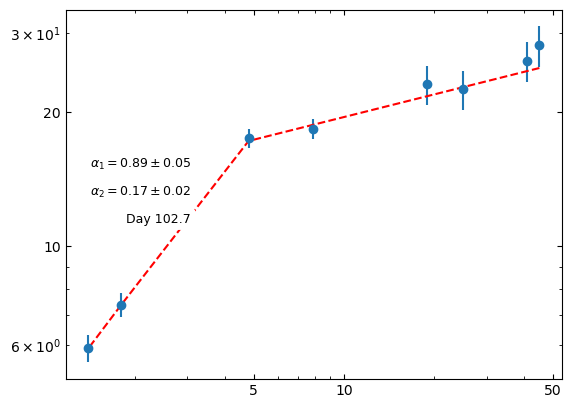

In [218]:
#plotting to check
fig,ax = plt.subplots()
mask = df19['Flux'] > 3 * df19['Error (gaussfit or image)']  # apply detection threshold
mask2 = df19['Flux'] < 3 * df19['Error (gaussfit or image)']  # apply detection threshold
if mask.any():  # proceed only if at least one detection
    ax.errorbar(df19['Freq'][mask], df19['Flux'][mask], yerr=yerr19, fmt='o')
    ax.scatter(df19['Freq'][mask2], (df19['Flux'][mask2] + 3*df19['Error (gaussfit or image)'][mask2]), marker='v')
    ax.set_xscale('log')
    ax.set_xticks([1, 5, 10, 50], labels=['1', '5', '10', '50'])
    ax.set_yscale('log')
    ax.set_yticks([1, 5, 10, 20, 50], labels=['1', '5', '10', '20', '50'])
    ax.annotate('Day 102.7', xy=(90, 120), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
    ax.tick_params(axis='both', which='both', direction='in', top=True, right=True)
    ax.plot(df19['Freq'][mask], fw_BPL19(df19['Freq'][mask]), 'r--')
    #ax.annotate('${\u03B1 = 0.584 \\pm 0.085}$', xy=(90, 100), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
    ax.annotate('${\u03B1_1 = 0.89 \\pm 0.05}$', xy=(90, 160), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
    ax.annotate('${\u03B1_2 = 0.17 \\pm 0.02}$', xy=(90, 140), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
    

plt.show();


### Day 138.5 (df20)

In [219]:
mask = df20['Flux'] > 3 * df20['Error (gaussfit or image)']  # apply detection threshold

x20 = df20['Freq'][mask].values.tolist()
y20 = df20['Flux'][mask].values.tolist()
yerr20 = df20['Error (gaussfit or image)'][mask].values.tolist()

In [220]:
yerr20 = error(yerr20, x20, y20)

In [221]:
#(work for anything with 3+ points)


PL20 =  PowerLaw1D(amplitude = y20[0], x_0= x20[0], alpha= -1) 

#Initialize fitters
#setting calc_uncertainties=True to output errors on measurement 

fit20 = fitting.LevMarLSQFitter(calc_uncertainties=True)

#Fit the data w/o weights
fit_model20 = fit20(PL20, x20, y20)


#weight is 1/error^2
y_weight20 = 1/ (np.power(yerr20, 2))  

# fit the data using the uncertainties as weights
fit_model_weights20 = fit20(PL20, x20, y20, weights=y_weight20)

fit_model_weights20


<PowerLaw1D(amplitude=22.726497, x_0=34.1783213, alpha=-0.35121251)>

In [222]:
fit20.fit_info

{'nfev': 19,
 'fvec': array([ 1.45747568,  1.3304898 ,  3.59630662,  1.62607359, -1.82777048,
        -3.58069741, -0.55213365,  2.43496923]),
 'fjac': array([[ 1.63937347e+02,  2.61434501e+00, -6.10540746e-01,
         -2.97117603e-02, -2.25906722e-01, -3.21651067e-01,
         -5.60059462e-01, -7.28281418e-01],
        [ 2.61434501e+00, -9.36593451e-01,  2.18727238e-01,
          3.15437500e-01,  6.22942628e-01,  4.57668792e-01,
          6.47474427e-02, -6.56747696e-02],
        [-6.10540746e-01,  2.18727238e-01,  1.42543190e-16,
         -0.00000000e+00,  3.89433907e-01,  3.89433907e-01,
          4.86792384e-02,  8.27547052e-01]]),
 'ipvt': array([2, 0, 1], dtype=int32),
 'qtf': array([ 1.39050001e-05, -1.35079048e-04, -1.02741626e+00]),
 'message': 'Both actual and predicted relative reductions in the sum of squares\n  are at most 0.000000',
 'ierr': 1,
 'param_jac': None,
 'param_cov': array([[2.68417335e+30, 1.14936722e+31, 6.78693017e+12],
        [1.14936722e+31, 4.92160840e+

In [223]:
#taking fvec
fvec20 = np.array([ 1.45745112,  1.33046589,  3.59627357,  1.62605339, -1.82778342,
        -3.58068182, -0.5520485 ,  2.43509184])
var20 = np.var(fvec20)

#taking cov_x
cov_x20 = np.array([[1.63281245e+31, 7.86571305e+31, 1.16704759e+13],
        [7.86571305e+31, 3.78913340e+32, 5.62199381e+13],
        [1.16704759e+13, 5.62199381e+13, 3.35463414e-04]])

def stand(cov):
    diag = np.diagonal(cov)
    sd1 = np.sqrt(diag[0])
    sd2 = np.sqrt(diag[1])
    sd3 = np.sqrt(diag[2])
    return(sd1,sd2,sd3)

diag20 = stand(cov_x20*var20) 

#The last diagonal element corresponds to alpha
#So here we are calculating the standard deviation on the slope

#print(diag)  #prints standard deviations of all three variances

print('The error/standard deviation is', diag20[2]) #Just showing the standard deviation on the slope

Xhi = cs(df20['Flux'], fit_model_weights20( df20["Freq"] ))
print("The chi squared is", Xhi/(8-4))

The error/standard deviation is 0.040622919295151584
The chi squared is 1.5407502483358257


In [224]:
#Will output many BPL functions 
#Check through them, if they are very far off they won't work in fitBPL
BM20 = bpl_func(x_val, y20, yerr20, a1, a2)

#BM3[43] worked for me and gives me a reasonable output in fitBPL
BM20[50]

#Apply error as weighting in the function 

weight20 = 1/ (np.power(yerr20,2))
fw_BPL20 = fitBPL(BM20[50], x20, y20, weights=weight20)   
print(fw_BPL20)
print("")
print(fitBPL.fit_info)

"""
#taking fvec
fvec4 = np.array(   )
var4 = np.var(fvec4)

#taking cov_x
cov_x4 = np.array(   )

def stand(cov):
    diag = np.diagonal(cov)
    sd1 = np.sqrt(diag[0])
    sd2 = np.sqrt(diag[1])
    sd3 = np.sqrt(diag[2]) #err 1
    sd4 = np.sqrt(diag[3]) #err 2
    return(sd1,sd2,sd3, sd4)

diag4 = stand(cov_x4*var4) 

#The last diagonal element corresponds to alpha
#So here we are calculating the standard deviation on the slope

#print(diag)  #prints standard deviations of all three variances
print("")
print('The error/standard deviation of the first one is', diag4[2], diag4[3]) #Just showing the standard deviation on the slope
"""

Xhi = cs(df20['Flux'], fw_BPL20( df20["Freq"] ))
print("")
print("The chi squared is", Xhi/(8-4))

"""
#for plotting
x_freq = np.arange(1,36,0.5)

    #in the if
    ax.plot(df3['Freq'][mask], fw_BPL3(df3['Freq'][mask]), 'b--')
    ax.annotate('${\u03B1_1 = 0.68 \\pm 0.006}$', xy=(90, 160), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
    ax.annotate('${\u03B1_2 = 0.82 \\pm 0.21}$', xy=(90, 140), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
""";

Model: BrokenPowerLaw1D
Inputs: ('x',)
Outputs: ('y',)
Model set size: 1
Parameters:
        amplitude           x_break            alpha_1               alpha_2       
    ------------------ ----------------- -------------------- ---------------------
    14.329899338958084 5.830912163847778 -0.49772882116653133 -0.042992231894725674

{'nfev': 6, 'fvec': array([-0.67210342, -0.73910664,  0.8657786 ,  0.09396083, -0.0944961 ,
        0.19149566, -0.9335967 ,  0.64357002]), 'fjac': array([[-6.26332167e+01,  0.00000000e+00,  0.00000000e+00,
         0.00000000e+00,  0.00000000e+00,  9.51606455e-02,
         5.78141949e-01,  8.10368026e-01],
       [ 0.00000000e+00,  1.94347345e+01,  6.10907660e-01,
         4.11101356e-01,  4.22179203e-01, -3.55197740e-02,
        -2.15797941e-01, -3.02478918e-01],
       [-3.45821492e+00, -1.52769613e+00,  2.30070138e+00,
         2.73045661e-02, -5.80765884e-01, -7.96006033e-01,
        -1.25206326e-01,  5.52224102e-02],
       [ 4.23011170e+00,  1.614

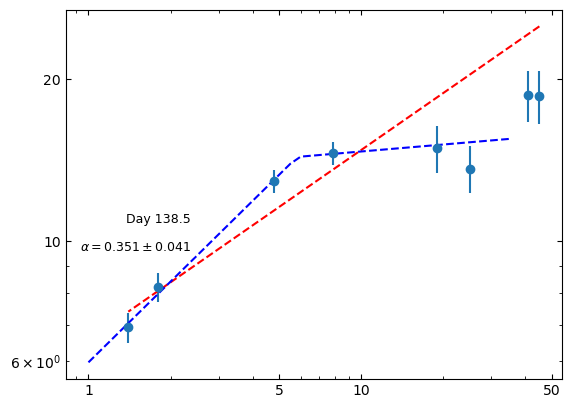

In [226]:
#plotting to check
fig,ax = plt.subplots()
mask = df20['Flux'] > 3 * df20['Error (gaussfit or image)']  # apply detection threshold
mask2 = df20['Flux'] < 3 * df20['Error (gaussfit or image)']  # apply detection threshold
if mask.any():  # proceed only if at least one detection
    ax.errorbar(df20['Freq'][mask], df20['Flux'][mask], yerr=yerr20, fmt='o')
    ax.scatter(df20['Freq'][mask2], (df20['Flux'][mask2] + 3*df20['Error (gaussfit or image)'][mask2]), marker='v')
    ax.set_xscale('log')
    ax.set_xticks([1, 5, 10, 50], labels=['1', '5', '10', '50'])
    ax.set_yscale('log')
    ax.set_yticks([1, 5, 10, 20, 50], labels=['1', '5', '10', '20', '50'])
    ax.annotate('Day 138.5', xy=(90, 120), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
    ax.tick_params(axis='both', which='both', direction='in', top=True, right=True)
    ax.plot(df20['Freq'][mask], fit_model_weights20(df20['Freq'][mask]), 'r--')
    ax.plot(x_freq, fw_BPL20(x_freq),  'b--')
    ax.annotate('${\u03B1 = 0.351 \\pm 0.041}$', xy=(90, 100), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))

plt.show();


### Day 153.6 (df21)

In [227]:
mask = df21['Flux'] > 3 * df21['Error (gaussfit or image)']  # apply detection threshold

x21 = df21['Freq'][mask].values.tolist()
y21 = df21['Flux'][mask].values.tolist()
yerr21 = df21['Error (gaussfit or image)'][mask].values.tolist()

In [228]:
yerr21 = error(yerr21, x21, y21)

In [235]:
#(work for anything with 3+ points)


PL21 =  PowerLaw1D(amplitude = y21[0], x_0= x21[0], alpha= -0.3) 

#Initialize fitters
#setting calc_uncertainties=True to output errors on measurement 

fit21 = fitting.LevMarLSQFitter(calc_uncertainties=True)

#Fit the data w/o weights
fit_model21 = fit21(PL21, x21, y21)


#weight is 1/error^2
y_weight21 = 1/ (np.power(yerr21, 2))  

# fit the data using the uncertainties as weights
fit_model_weights21 = fit21(PL21, x21, y21, weights=y_weight21)

fit_model_weights21


<PowerLaw1D(amplitude=28.44727334, x_0=356.83929917, alpha=-0.22705343)>

In [236]:
fit21.fit_info

{'nfev': 16,
 'fvec': array([ 2.0349264 ,  2.84029397,  1.27260532,  0.77042913, -2.24325723,
        -3.06425437,  1.76924598,  0.60497644]),
 'fjac': array([[-3.25093688e+02, -2.34466639e+00,  4.23929181e-02,
          7.47176984e-02,  3.32539076e-01,  3.91347352e-01,
          6.70490891e-01,  5.18412694e-01],
        [-2.34466639e+00, -4.44694389e-01,  8.04033057e-03,
          2.32916850e-01,  3.66354591e-01,  1.26254146e-01,
         -5.24532302e-01, -5.19698990e-01],
        [ 4.23929181e-02,  8.04033057e-03,  1.57713222e-17,
          6.87451665e-02,  3.02478733e-01,  6.18706499e-01,
          6.04957465e-01,  3.84972933e-01]]),
 'ipvt': array([2, 0, 1], dtype=int32),
 'qtf': array([-3.18938920e-04, -5.87719548e-05,  2.40872241e+00]),
 'message': 'Both actual and predicted relative reductions in the sum of squares\n  are at most 0.000000',
 'ierr': 1,
 'param_jac': None,
 'param_cov': array([[ 1.31428121e+30,  7.26902303e+31, -6.59858264e+11],
        [ 7.26902303e+31,  4.02034

In [237]:
#taking fvec
fvec21 = np.array([ 2.03489194,  2.84025556,  1.27257919,  0.77040863, -2.24328156,
        -3.06425257,  1.76932299,  0.60504738])
var21 = np.var(fvec21)

#taking cov_x
cov_x21 = np.array([[ 1.56880710e+30,  2.30057503e+31, -1.24256941e+13],
        [ 2.30057503e+31,  3.37367512e+32, -1.82216422e+14],
        [-1.24256941e+13, -1.82216422e+14,  3.70922403e-04]])

def stand(cov):
    diag = np.diagonal(cov)
    sd1 = np.sqrt(diag[0])
    sd2 = np.sqrt(diag[1])
    sd3 = np.sqrt(diag[2])
    return(sd1,sd2,sd3)

diag21 = stand(cov_x21*var21) 

#The last diagonal element corresponds to alpha
#So here we are calculating the standard deviation on the slope

#print(diag)  #prints standard deviations of all three variances

print('The error/standard deviation is', diag21[2]) #Just showing the standard deviation on the slope

Xhi = cs(df21['Flux'], fit_model_weights21( df21["Freq"] ))
print("The chi squared is", Xhi/(8-4))

The error/standard deviation is 0.0375151878385926
The chi squared is 0.7831370374350813


In [238]:
#Will output many BPL functions 
#Check through them, if they are very far off they won't work in fitBPL
BM21 = bpl_func(x_val, y21, yerr21, a1, a2)

#BM3[43] worked for me and gives me a reasonable output in fitBPL
BM21[50]

#Apply error as weighting in the function 

weight21 = 1/ (np.power(yerr21,2))
fw_BPL21 = fitBPL(BM21[50], x21, y21, weights=weight21)   
print(fw_BPL21)
print("")
print(fitBPL.fit_info)

"""
#taking fvec
fvec4 = np.array(   )
var4 = np.var(fvec4)

#taking cov_x
cov_x4 = np.array(   )

def stand(cov):
    diag = np.diagonal(cov)
    sd1 = np.sqrt(diag[0])
    sd2 = np.sqrt(diag[1])
    sd3 = np.sqrt(diag[2]) #err 1
    sd4 = np.sqrt(diag[3]) #err 2
    return(sd1,sd2,sd3, sd4)

diag4 = stand(cov_x4*var4) 

#The last diagonal element corresponds to alpha
#So here we are calculating the standard deviation on the slope

#print(diag)  #prints standard deviations of all three variances
print("")
print('The error/standard deviation of the first one is', diag4[2], diag4[3]) #Just showing the standard deviation on the slope
"""

Xhi = cs(df21['Flux'], fw_BPL21( df21["Freq"] ))
print("")
print("The chi squared is", Xhi/(8-4))

"""
#for plotting
x_freq = np.arange(1,36,0.5)

    #in the if
    ax.plot(df3['Freq'][mask], fw_BPL3(df3['Freq'][mask]), 'b--')
    ax.annotate('${\u03B1_1 = 0.68 \\pm 0.006}$', xy=(90, 160), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
    ax.annotate('${\u03B1_2 = 0.82 \\pm 0.21}$', xy=(90, 140), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
""";

Model: BrokenPowerLaw1D
Inputs: ('x',)
Outputs: ('y',)
Model set size: 1
Parameters:
        amplitude           x_break            alpha_1              alpha_2       
    ------------------ ----------------- ------------------- ---------------------
    12.917690643471074 6.356961274235149 -0.3441412878912632 -0.005681262192666333

{'nfev': 8, 'fvec': array([-0.21306124,  0.37574741, -0.1568448 , -0.14595311,  0.02521789,
       -0.21454568,  0.84538254, -0.93893531]), 'fjac': array([[-6.76189977e+01,  0.00000000e+00,  0.00000000e+00,
         0.00000000e+00,  0.00000000e+00,  1.34475222e-01,
         7.51493787e-01,  6.45889698e-01],
       [ 0.00000000e+00,  2.34256142e+01,  4.28688708e-01,
         3.44075179e-01,  2.84133829e-01, -6.99674973e-02,
        -3.91002438e-01, -3.36056599e-01],
       [-4.12310487e+00, -1.70100350e+00,  2.81552073e+00,
        -2.75033681e-02, -6.97708312e-01, -7.05554890e-01,
        -7.68964945e-02,  9.19837561e-02],
       [ 2.88334316e+00,  1.963745

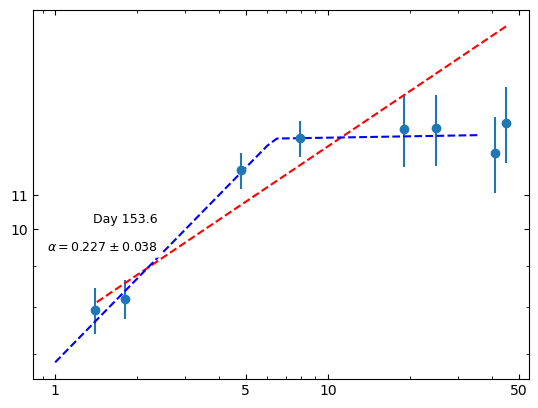

In [239]:
#plotting to check
fig,ax = plt.subplots()
mask = df21['Flux'] > 3 * df21['Error (gaussfit or image)']  # apply detection threshold
mask2 = df21['Flux'] < 3 * df21['Error (gaussfit or image)']  # apply detection threshold
if mask.any():  # proceed only if at least one detection
    ax.errorbar(df21['Freq'][mask], df21['Flux'][mask], yerr=yerr21, fmt='o')
    ax.scatter(df21['Freq'][mask2], (df21['Flux'][mask2] + 3*df21['Error (gaussfit or image)'][mask2]), marker='v')
    ax.set_xscale('log')
    ax.set_xticks([1, 5, 10, 50], labels=['1', '5', '10', '50'])
    ax.set_yscale('log')
    ax.set_yticks([0.1, 1, 5, 10, 11, 20, 50], labels=["0.1",'1', '5', '10', "11", '20', '50'])
    ax.annotate('Day 153.6', xy=(90, 120), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
    ax.tick_params(axis='both', which='both', direction='in', top=True, right=True)
    ax.plot(df21['Freq'][mask], fit_model_weights21(df21['Freq'][mask]), 'r--')
    ax.plot(x_freq, fw_BPL21(x_freq),  'b--')
    ax.annotate('${\u03B1 = 0.227 \\pm 0.038}$', xy=(90, 100), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))

plt.show();


### Day 168.5 (df22)

In [240]:
mask = df22['Flux'] > 3 * df22['Error (gaussfit or image)']  # apply detection threshold

x22 = df22['Freq'][mask].values.tolist()
y22 = df22['Flux'][mask].values.tolist()
yerr22 = df22['Error (gaussfit or image)'][mask].values.tolist()

In [241]:
yerr22 = error(yerr22, x22, y22)

In [242]:
#(work for anything with 3+ points)

PL22 =  PowerLaw1D(amplitude = y22[0], x_0= x22[0], alpha= -4.5) 

#Initialize fitters
#setting calc_uncertainties=True to output errors on measurement 

fit22 = fitting.LevMarLSQFitter(calc_uncertainties=True)

#Fit the data w/o weights
fit_model22 = fit22(PL22, x22, y22)


#weight is 1/error^2
y_weight22 = 1/ (np.power(yerr22, 2))  

# fit the data using the uncertainties as weights
fit_model_weights22 = fit22(PL22, x22, y22, weights=y_weight22)

fit_model_weights22


<PowerLaw1D(amplitude=25.34182546, x_0=89.19447204, alpha=-0.35153419)>

In [243]:
fit22.fit_info

{'nfev': 25,
 'fvec': array([ 1.81978235,  1.90472319,  3.98041904,  2.01087389, -1.56785278,
        -5.69471654,  0.25290108,  2.75650372]),
 'fjac': array([[-2.62579093e+02, -2.88998377e+00,  2.88644263e-01,
          6.11915331e-02,  3.10218280e-01,  3.35654960e-01,
          5.98691192e-01,  6.51234670e-01],
        [-2.88998377e+00, -7.73054280e-01,  7.72107045e-02,
          2.82915741e-01,  4.60805445e-01,  1.82132693e-01,
         -3.65213399e-01, -5.32554892e-01],
        [ 2.88644263e-01,  7.72107045e-02,  3.57201426e-17,
          2.91385759e-01,  1.94257172e-01,  7.77028690e-01,
          2.91385759e-01, -1.94257172e-01]]),
 'ipvt': array([2, 0, 1], dtype=int32),
 'qtf': array([-5.39036148e-05, -1.55924277e-05,  4.46083855e+00]),
 'message': 'Both actual and predicted relative reductions in the sum of squares\n  are at most 0.000000',
 'ierr': 1,
 'param_jac': None,
 'param_cov': array([[7.81823435e+30, 7.82782590e+31, 1.70629180e+13],
        [7.82782590e+31, 7.83742922e+

In [244]:
#taking fvec
fvec22 = np.array([ 1.81977826,  1.90471896,  3.98041206,  2.01086826, -1.56787099,
        -5.69473289,  0.25287924,  2.75648141])
var22 = np.var(fvec22)

#taking cov_x
cov_x22 = np.array([[8.81469749e+30, 8.31171268e+31, 1.49601897e+13],
        [8.31171268e+31, 7.83742922e+32, 1.41065305e+14],
        [1.49601897e+13, 1.41065305e+14, 2.42590813e-04]])

def stand(cov):
    diag = np.diagonal(cov)
    sd1 = np.sqrt(diag[0])
    sd2 = np.sqrt(diag[1])
    sd3 = np.sqrt(diag[2])
    return(sd1,sd2,sd3)

diag22 = stand(cov_x22*var22) 

#The last diagonal element corresponds to alpha
#So here we are calculating the standard deviation on the slope

#print(diag)  #prints standard deviations of all three variances

print('The error/standard deviation is', diag22[2]) #Just showing the standard deviation on the slope

Xhi = cs(df22['Flux'], fit_model_weights22( df22["Freq"] ))
print("The chi squared is", Xhi/(8-4))

The error/standard deviation is 0.044617008133632036
The chi squared is 1.1940452194821378


In [245]:
#Will output many BPL functions 
#Check through them, if they are very far off they won't work in fitBPL
BM22 = bpl_func(x_val, y22, yerr22, a1, a2)

#BM3[43] worked for me and gives me a reasonable output in fitBPL
BM22[50]

#Apply error as weighting in the function 

weight22 = 1/ (np.power(yerr22,2))
fw_BPL22 = fitBPL(BM22[50], x22, y22, weights=weight22)   
print(fw_BPL22)
print("")
print(fitBPL.fit_info)

"""
#taking fvec
fvec4 = np.array(   )
var4 = np.var(fvec4)

#taking cov_x
cov_x4 = np.array(   )

def stand(cov):
    diag = np.diagonal(cov)
    sd1 = np.sqrt(diag[0])
    sd2 = np.sqrt(diag[1])
    sd3 = np.sqrt(diag[2]) #err 1
    sd4 = np.sqrt(diag[3]) #err 2
    return(sd1,sd2,sd3, sd4)

diag4 = stand(cov_x4*var4) 

#The last diagonal element corresponds to alpha
#So here we are calculating the standard deviation on the slope

#print(diag)  #prints standard deviations of all three variances
print("")
print('The error/standard deviation of the first one is', diag4[2], diag4[3]) #Just showing the standard deviation on the slope
"""

Xhi = cs(df22['Flux'], fw_BPL22( df22["Freq"] ))
print("")
print("The chi squared is", Xhi/(8-4))

"""
#for plotting
x_freq = np.arange(1,36,0.5)

    #in the if
    ax.plot(df3['Freq'][mask], fw_BPL3(df3['Freq'][mask]), 'b--')
    ax.annotate('${\u03B1_1 = 0.68 \\pm 0.006}$', xy=(90, 160), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
    ax.annotate('${\u03B1_2 = 0.82 \\pm 0.21}$', xy=(90, 140), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
""";

Model: BrokenPowerLaw1D
Inputs: ('x',)
Outputs: ('y',)
Model set size: 1
Parameters:
        amplitude           x_break           alpha_1             alpha_2       
    ------------------ ----------------- ------------------ --------------------
    10.674946191067853 4.224335768123279 -0.602281396098968 -0.08601848590097347

{'nfev': 7, 'fvec': array([-7.71103375e-01, -6.48073116e-01,  9.85395259e-01,  1.99025173e-01,
       -1.47603337e-01,  2.62714273e-02, -5.56668479e-15, -6.21439269e-15]), 'fjac': array([[-5.44498988e+01,  0.00000000e+00,  0.00000000e+00,
         0.00000000e+00,  0.00000000e+00,  0.00000000e+00,
         6.27069469e-01,  7.78963338e-01],
       [ 0.00000000e+00,  3.54640030e+01,  4.95967090e-01,
         3.63710166e-01,  6.18254383e-01,  1.29258877e-01,
        -2.07309889e-01, -2.57526177e-01],
       [-5.15360594e+00, -3.53428216e+00,  3.46077040e+00,
         8.43406856e-02, -4.09984271e-01, -8.58761587e-01,
        -2.45905219e-01,  7.84656423e-04],
       [

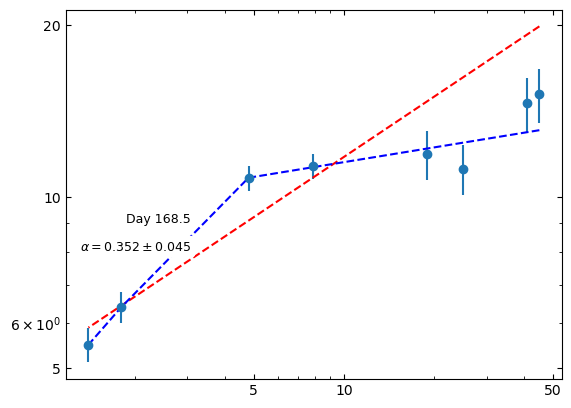

In [246]:
#plotting to check
fig,ax = plt.subplots()
mask = df22['Flux'] > 3 * df22['Error (gaussfit or image)']  # apply detection threshold
mask2 = df22['Flux'] < 3 * df22['Error (gaussfit or image)']  # apply detection threshold
if mask.any():  # proceed only if at least one detection
    ax.errorbar(df22['Freq'][mask], df22['Flux'][mask], yerr=yerr22, fmt='o')
    ax.scatter(df22['Freq'][mask2], (df22['Flux'][mask2] + 3*df22['Error (gaussfit or image)'][mask2]), marker='v')
    ax.set_xscale('log')
    ax.set_xticks([1, 5, 10, 50], labels=['1', '5', '10', '50'])
    ax.set_yscale('log')
    ax.set_yticks([1, 5, 10, 20, 50], labels=['1', '5', '10', '20', '50'])
    ax.annotate('Day 168.5', xy=(90, 120), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
    ax.tick_params(axis='both', which='both', direction='in', top=True, right=True)
    ax.plot(df22['Freq'][mask], fit_model_weights22(df22['Freq'][mask]), 'r--')
    ax.plot(df22['Freq'][mask], fw_BPL22(df22['Freq'][mask]), 'b--')
    ax.annotate('${\u03B1 = 0.352 \\pm 0.045}$', xy=(90, 100), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))

plt.show();


### Day 183.5 (df23)

In [247]:
mask = df23['Flux'] > 3 * df23['Error (gaussfit or image)']  # apply detection threshold

x23 = df23['Freq'][mask].values.tolist()
y23 = df23['Flux'][mask].values.tolist()
yerr23 = df23['Error (gaussfit or image)'][mask].values.tolist()

In [248]:
yerr23 = error(yerr23, x23, y23)

In [252]:
#(work for anything with 3+ points)


PL23 =  PowerLaw1D(amplitude = y23[0], x_0= x23[0], alpha= -2.7) 

#Initialize fitters
#setting calc_uncertainties=True to output errors on measurement 

fit23 = fitting.LevMarLSQFitter(calc_uncertainties=True)

#Fit the data w/o weights
fit_model23 = fit23(PL23, x23, y23)


#weight is 1/error^2
y_weight23 = 1/ (np.power(yerr23, 2))  

# fit the data using the uncertainties as weights
fit_model_weights23 = fit23(PL23, x23, y23, weights=y_weight23)

fit_model_weights23


<PowerLaw1D(amplitude=11.76343122, x_0=18.72084562, alpha=-0.25806269)>

In [253]:
fit23.fit_info

{'nfev': 21,
 'fvec': array([ 3.92952207,  2.8763814 ,  3.4817266 ,  1.78615918, -2.83094597,
        -6.48278423,  0.71352157,  3.05577772]),
 'fjac': array([[ 1.74116264e+02,  6.54951756e+00, -1.06363716e+00,
          1.12725761e-03, -1.77455760e-01, -2.46496740e-01,
         -6.85442858e-01, -6.58135194e-01],
        [ 6.54951756e+00, -3.21081458e+00,  5.21434087e-01,
          3.12209744e-01,  6.52380946e-01,  4.22023337e-01,
          1.98488260e-01,  6.47656196e-02],
        [-1.06363716e+00,  5.21434087e-01,  1.65518438e-16,
          1.67688723e-01, -0.00000000e+00,  3.35377447e-01,
          8.38443616e-01,  2.09610904e-01]]),
 'ipvt': array([2, 0, 1], dtype=int32),
 'qtf': array([ 4.00271967e-04, -8.08419652e-04, -2.39956390e+00]),
 'message': 'Both actual and predicted relative reductions in the sum of squares\n  are at most 0.000000',
 'ierr': 1,
 'param_jac': None,
 'param_cov': array([[9.62665978e+29, 5.92777119e+30, 2.30885109e+12],
        [5.92777119e+30, 3.65012081e+

In [254]:
#taking fvec
fvec23 = np.array([ 3.92952367,  2.87638277,  3.48172882,  1.78616106, -2.83094004,
        -6.48277892,  0.71353041,  3.05578544])
var23 = np.var(fvec23)

#taking cov_x
cov_x23 = np.array([[7.23503964e+29, 4.58675017e+30, 2.32815387e+12],
        [4.58675017e+30, 2.90783163e+31, 1.47596429e+13],
        [2.32815387e+12, 1.47596429e+13, 1.77731389e-04]])

def stand(cov):
    diag = np.diagonal(cov)
    sd1 = np.sqrt(diag[0])
    sd2 = np.sqrt(diag[1])
    sd3 = np.sqrt(diag[2])
    return(sd1,sd2,sd3)

diag23 = stand(cov_x23*var23) 

#The last diagonal element corresponds to alpha
#So here we are calculating the standard deviation on the slope

#print(diag)  #prints standard deviations of all three variances

print('The error/standard deviation is', diag23[2]) #Just showing the standard deviation on the slope

Xhi = cs(df23['Flux'], fit_model_weights23( df23["Freq"] ))
print("The chi squared is", Xhi/(8-4))

The error/standard deviation is 0.04559765913939875
The chi squared is 1.3085496713232843


In [255]:
#Will output many BPL functions 
#Check through them, if they are very far off they won't work in fitBPL
BM23 = bpl_func(x_val, y23, yerr23, a1, a2)

#BM3[43] worked for me and gives me a reasonable output in fitBPL
BM23[50]

#Apply error as weighting in the function 

weight23 = 1/ (np.power(yerr23,2))
fw_BPL23 = fitBPL(BM23[50], x23, y23, weights=weight23)   
print(fw_BPL23)
print("")
print(fitBPL.fit_info)


#taking fvec
fvec4 = np.array( [ 0.18496618, -0.15859331,  0.12925372, -0.2563521 ,  0.02104835,
        0.03238988, -0.12057733,  0.11664496]  )
var4 = np.var(fvec4)

#taking cov_x
cov_x4 = np.array( [[ 1.38307655e-01,  1.40656553e-01, -6.37192568e-04,
         1.53620897e-02],
       [ 1.40656553e-01,  2.37902473e-01,  6.74551349e-03,
         1.65310013e-02],
       [-6.37192568e-04,  6.74551349e-03,  7.52334157e-04,
         2.71050543e-19],
       [ 1.53620897e-02,  1.65310013e-02,  2.71050543e-19,
         2.68499800e-03]]  )

def stand(cov):
    diag = np.diagonal(cov)
    sd1 = np.sqrt(diag[0])
    sd2 = np.sqrt(diag[1])
    sd3 = np.sqrt(diag[2]) #err 1
    sd4 = np.sqrt(diag[3]) #err 2
    return(sd1,sd2,sd3, sd4)

diag4 = stand(cov_x4*var4) 

#The last diagonal element corresponds to alpha
#So here we are calculating the standard deviation on the slope

#print(diag)  #prints standard deviations of all three variances
print("")
print('The error/standard deviation of the first one is', diag4[2], diag4[3]) #Just showing the standard deviation on the slope


Xhi = cs(df23['Flux'], fw_BPL23( df23["Freq"] ))
print("")
print("The chi squared is", Xhi/(8-4))

"""
#for plotting
x_freq = np.arange(1,36,0.5)

    #in the if
    ax.plot(df3['Freq'][mask], fw_BPL3(df3['Freq'][mask]), 'b--')
    ax.annotate('${\u03B1_1 = 0.68 \\pm 0.006}$', xy=(90, 160), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
    ax.annotate('${\u03B1_2 = 0.82 \\pm 0.21}$', xy=(90, 140), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
""";

Model: BrokenPowerLaw1D
Inputs: ('x',)
Outputs: ('y',)
Model set size: 1
Parameters:
        amplitude          x_break            alpha_1              alpha_2      
    ----------------- ----------------- -------------------- -------------------
    10.36693407299515 5.199770408526263 -0.46610629375687584 0.04737939634281797

{'nfev': 11, 'fvec': array([ 0.18496618, -0.15859331,  0.12925372, -0.2563521 ,  0.02104835,
        0.03238988, -0.12057733,  0.11664496]), 'fjac': array([[-7.60025133e+01,  0.00000000e+00,  0.00000000e+00,
         0.00000000e+00,  0.00000000e+00,  4.00975203e-02,
         7.00273777e-01,  7.12747379e-01],
       [ 0.00000000e+00,  3.21078984e+01,  5.17085385e-01,
         3.90355374e-01,  5.04705137e-01, -1.75176062e-02,
        -3.05932142e-01, -3.11381548e-01],
       [-6.37468216e+00, -3.25371325e+00,  4.25835025e+00,
         3.60070227e-02, -5.47822685e-01, -8.08440986e-01,
        -1.84999598e-01,  3.32508816e-02],
       [ 5.92392664e+00, -3.07351235e-0

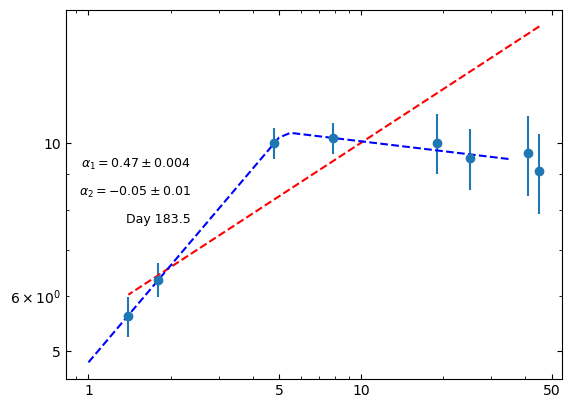

In [256]:
#plotting to check
fig,ax = plt.subplots()
mask = df23['Flux'] > 3 * df23['Error (gaussfit or image)']  # apply detection threshold
mask2 = df23['Flux'] < 3 * df23['Error (gaussfit or image)']  # apply detection threshold
if mask.any():  # proceed only if at least one detection]
    ax.errorbar(df23['Freq'][mask], df23['Flux'][mask], yerr=yerr23, fmt='o')
    ax.scatter(df23['Freq'][mask2], (df23['Flux'][mask2] + 3*df23['Error (gaussfit or image)'][mask2]), marker='v')
    ax.set_xscale('log')
    ax.set_xticks([1, 5, 10, 50], labels=['1', '5', '10', '50'])
    ax.set_yscale('log')
    ax.set_yticks([1, 5, 10, 20, 50], labels=['1', '5', '10', '20', '50'])
    ax.annotate('Day 183.5', xy=(90, 120), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
    ax.tick_params(axis='both', which='both', direction='in', top=True, right=True)
    ax.plot(df23['Freq'][mask], fit_model_weights23(df23['Freq'][mask]), 'r--')
    ax.plot(x_freq, fw_BPL23(x_freq),  'b--')
    #ax.annotate('${\u03B1 = 0.258 \\pm 0.046}$', xy=(90, 100), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
    ax.annotate('${\u03B1_1 = 0.47 \\pm 0.004}$', xy=(90, 160), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
    ax.annotate('${\u03B1_2 = -0.05 \\pm 0.01}$', xy=(90, 140), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))

plt.show();


### Day 203.4 (df24)

In [257]:

mask = df24['Flux'] > 3 * df24['Error (gaussfit or image)']  # apply detection threshold

x24 = df24['Freq'][mask].values.tolist()
y24 = df24['Flux'][mask].values.tolist()
yerr24 = df24['Error (gaussfit or image)'][mask].values.tolist()

In [258]:
yerr24 = error(yerr24, x24, y24)

In [259]:
#(work for anything with 3+ points)


PL24 =  PowerLaw1D(amplitude = y24[0], x_0= x24[0], alpha= -3) 

#Initialize fitters
#setting calc_uncertainties=True to output errors on measurement 

fit24 = fitting.LevMarLSQFitter(calc_uncertainties=True)

#Fit the data w/o weights
fit_model24 = fit24(PL24, x24, y24)


#weight is 1/error^2
y_weight24 = 1/ (np.power(yerr24, 2))  

# fit the data using the uncertainties as weights
fit_model_weights24 = fit24(PL24, x24, y24, weights=y_weight24)

fit_model_weights24


<PowerLaw1D(amplitude=8.43879553, x_0=6.06016328, alpha=-0.29929785)>

In [260]:
fit24.fit_info

{'nfev': 19,
 'fvec': array([ 1.24850386,  0.31616597,  2.75674766,  2.06263753,  0.1598074 ,
        -6.03666911,  3.54639855, -1.40742278]),
 'fjac': array([[ 1.15003557e+02,  8.58450235e+00, -3.57779009e+00,
          1.20778184e-01,  9.98351288e-02, -7.39136923e-02,
         -6.53848877e-01, -7.01024343e-01],
        [ 8.58450235e+00, -8.56164347e+00,  3.56826312e+00,
          2.64789911e-01,  6.79191510e-01,  4.45595086e-01,
          3.34648111e-01,  2.01138261e-01],
        [-3.57779009e+00,  3.56826312e+00,  4.96506831e-16,
         -4.47213595e-01, -0.00000000e+00, -4.47213595e-01,
          4.47213595e-01,  4.47213595e-01]]),
 'ipvt': array([2, 0, 1], dtype=int32),
 'qtf': array([ 1.19182372e-04, -1.25476655e-04, -4.57397529e+00]),
 'message': 'Both actual and predicted relative reductions in the sum of squares\n  are at most 0.000000',
 'ierr': 1,
 'param_jac': None,
 'param_cov': array([[7.04610336e+29, 1.69063275e+30, 1.70563089e+13],
        [1.69063275e+30, 4.05648192e+

In [261]:
#taking fvec
fvec24 = np.array([ 1.24850337,  0.31616555,  2.7567468 ,  2.0626367 ,  0.15980445,
        -6.03667159,  3.54639432, -1.40742654])
var24 = np.var(fvec24)

#taking cov_x
cov_x24 = np.array([[1.84937757e+29, 4.33069471e+29, 1.45208344e+11],
        [4.33069471e+29, 1.01412048e+30, 3.40034950e+11],
        [1.45208344e+11, 3.40034950e+11, 1.51737696e-04]])

def stand(cov):
    diag = np.diagonal(cov)
    sd1 = np.sqrt(diag[0])
    sd2 = np.sqrt(diag[1])
    sd3 = np.sqrt(diag[2])
    return(sd1,sd2,sd3)

diag24 = stand(cov_x24*var24) 

#The last diagonal element corresponds to alpha
#So here we are calculating the standard deviation on the slope

#print(diag)  #prints standard deviations of all three variances

print('The error/standard deviation is', diag24[2]) #Just showing the standard deviation on the slope

Xhi = cs(df24['Flux'], fit_model_weights24( df24["Freq"] ))
print("The chi squared is", Xhi/(8-4))

The error/standard deviation is 0.034749043174645305
The chi squared is 0.4204825518355536


In [262]:
#Will output many BPL functions 
#Check through them, if they are very far off they won't work in fitBPL
BM24 = bpl_func(x_val, y24, yerr24, a1, a2)

#BM3[43] worked for me and gives me a reasonable output in fitBPL
BM24[50]

#Apply error as weighting in the function 

weight24 = 1/ (np.power(yerr24,2))
fw_BPL24 = fitBPL(BM24[50], x24, y24, weights=weight24)   
print(fw_BPL24)
print("")
print(fitBPL.fit_info)

"""
#taking fvec
fvec4 = np.array(   )
var4 = np.var(fvec4)

#taking cov_x
cov_x4 = np.array(   )

def stand(cov):
    diag = np.diagonal(cov)
    sd1 = np.sqrt(diag[0])
    sd2 = np.sqrt(diag[1])
    sd3 = np.sqrt(diag[2]) #err 1
    sd4 = np.sqrt(diag[3]) #err 2
    return(sd1,sd2,sd3, sd4)

diag4 = stand(cov_x4*var4) 

#The last diagonal element corresponds to alpha
#So here we are calculating the standard deviation on the slope

#print(diag)  #prints standard deviations of all three variances
print("")
print('The error/standard deviation of the first one is', diag4[2], diag4[3]) #Just showing the standard deviation on the slope
"""

Xhi = cs(df24['Flux'], fw_BPL24( df24["Freq"] ))
print("")
print("The chi squared is", Xhi/(8-4))

"""
#for plotting
x_freq = np.arange(1,36,0.5)

    #in the if
    ax.plot(df3['Freq'][mask], fw_BPL3(df3['Freq'][mask]), 'b--')
    ax.annotate('${\u03B1_1 = 0.68 \\pm 0.006}$', xy=(90, 160), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
    ax.annotate('${\u03B1_2 = 0.82 \\pm 0.21}$', xy=(90, 140), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
""";

Model: BrokenPowerLaw1D
Inputs: ('x',)
Outputs: ('y',)
Model set size: 1
Parameters:
       amplitude          x_break            alpha_1              alpha_2       
    ---------------- ----------------- -------------------- --------------------
    8.79782342512048 4.800000013724195 -0.41478744427670167 -0.09999770677433252

{'nfev': 27, 'fvec': array([-0.83255573, -1.35643196,  0.28824341,  0.23680235,  0.68859294,
       -1.73824985,  3.43263751, -3.07956928]), 'fjac': array([[-8.94343058e+01,  0.00000000e+00,  1.67921036e-01,
        -1.27662901e-01,  0.00000000e+00,  1.30314644e-09,
         6.78076599e-01,  7.34991242e-01],
       [ 0.00000000e+00,  3.45068140e+01, -9.07974846e-02,
         1.66417066e-02,  6.32925921e-01, -4.42614750e-10,
        -2.30309270e-01, -2.49640375e-01],
       [-9.22221978e+00, -4.54361798e+00,  5.48492402e+00,
        -1.52800865e-01, -4.52553470e-01, -8.44706539e-01,
        -2.33456107e-01,  3.02203013e-02],
       [ 7.01124385e+00,  8.32771497e-0

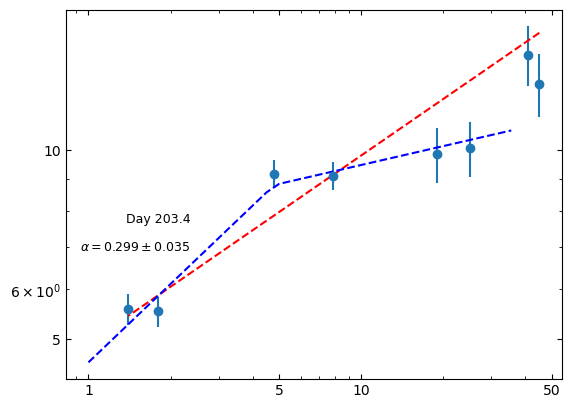

In [263]:
#plotting to check
fig,ax = plt.subplots()
mask = df24['Flux'] > 3 * df24['Error (gaussfit or image)']  # apply detection threshold
mask2 = df24['Flux'] < 3 * df24['Error (gaussfit or image)']  # apply detection threshold
if mask.any():  # proceed only if at least one detection
    ax.errorbar(df24['Freq'][mask], df24['Flux'][mask], yerr=yerr24, fmt='o')
    ax.scatter(df24['Freq'][mask2], (df24['Flux'][mask2] + 3*df24['Error (gaussfit or image)'][mask2]), marker='v')
    ax.set_xscale('log')
    ax.set_xticks([1, 5, 10, 50], labels=['1', '5', '10', '50'])
    ax.set_yscale('log')
    ax.set_yticks([1, 5, 10, 20, 50], labels=['1', '5', '10', '20', '50'])
    ax.annotate('Day 203.4', xy=(90, 120), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
    ax.tick_params(axis='both', which='both', direction='in', top=True, right=True)
    ax.plot(df24['Freq'][mask], fit_model_weights24(df24['Freq'][mask]), 'r--')
    ax.plot(x_freq, fw_BPL24(x_freq),  'b--')
    ax.annotate('${\u03B1 = 0.299 \\pm 0.035}$', xy=(90, 100), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))

plt.show();


### Day 359.6 (df25)

In [264]:
mask = df25['Flux'] > 3 * df25['Error (gaussfit or image)']  # apply detection threshold

x25 = df25['Freq'][mask].values.tolist()
y25 = df25['Flux'][mask].values.tolist()
yerr25 = df25['Error (gaussfit or image)'][mask].values.tolist()

In [265]:
yerr25 = error(yerr25, x25, y25)

In [331]:
#(work for anything with 3+ points)


PL25 =  PowerLaw1D(amplitude = y25[0], x_0= x25[0], alpha= -0.05009805) 

#Initialize fitters
#setting calc_uncertainties=True to output errors on measurement 

fit25 = fitting.LevMarLSQFitter(calc_uncertainties=True)

#Fit the data w/o weights
fit_model25 = fit25(PL25, x25, y25)


#weight is 1/error^2
y_weight25 = 1/ (np.power(yerr25, 2))  

# fit the data using the uncertainties as weights
fit_model_weights25 = fit25(PL25, x25, y25, weights=y_weight25)

fit_model_weights25


<PowerLaw1D(amplitude=5.51961232, x_0=89.38934878, alpha=-0.05009803)>

In [332]:
fit25.fit_info

{'nfev': 14,
 'fvec': array([-0.31702591,  0.01667916,  1.94766881,  2.16097257,  1.00812266,
        -3.5675042 , -1.68631282,  3.45210374]),
 'fjac': array([[-4.94426959e+02, -2.67506034e+01,  8.26057050e-02,
          7.11659339e-02,  4.20403915e-01,  4.40399949e-01,
          5.74964563e-01,  5.37710371e-01],
        [-2.67506034e+01, -7.40845823e+00,  2.28772752e-02,
          2.98426565e-01,  3.99654795e-01,  1.28525304e-01,
         -4.62154160e-01, -5.60139124e-01],
        [ 8.26057050e-02,  2.28772752e-02,  7.00632886e-18,
         -2.47593784e-01,  2.47593784e-01,  5.57086015e-01,
          7.42781353e-01, -0.00000000e+00]]),
 'ipvt': array([2, 0, 1], dtype=int32),
 'qtf': array([-3.19068380e-04, -8.83645403e-05,  3.04252110e+00]),
 'message': 'Both actual and predicted relative reductions in the sum of squares\n  are at most 0.000000',
 'ierr': 1,
 'param_jac': None,
 'param_cov': array([[ 1.94254855e+29,  6.29064856e+31, -4.57272299e+12],
        [ 6.29064856e+31,  2.03713

In [333]:
#taking fvec
fvec25 = np.array([-0.31702273,  0.01668269,  1.94767339,  2.16097716,  1.00813729,
        -3.56749153, -1.68630205,  3.45211264])
var25 = np.var(fvec25)

#taking cov_x
cov_x25 = np.array([[1.76463546e+28, 3.34208578e+30, 1.35201637e+11],
        [3.34208578e+30, 6.32965712e+32, 2.56061651e+13],
        [1.35201637e+11, 2.56061651e+13, 5.84611542e-05]])

def stand(cov):
    diag = np.diagonal(cov)
    sd1 = np.sqrt(diag[0])
    sd2 = np.sqrt(diag[1])
    sd3 = np.sqrt(diag[2])
    return(sd1,sd2,sd3)

diag25 = stand(cov_x25*var25) 

#The last diagonal element corresponds to alpha
#So here we are calculating the standard deviation on the slope

#print(diag)  #prints standard deviations of all three variances

print('The error/standard deviation is', diag25[2]) #Just showing the standard deviation on the slope

Xhi = cs(df25['Flux'], fit_model_weights25( df25["Freq"] ))
print("The chi squared is", Xhi/(8-4))

The error/standard deviation is 0.016204259521049
The chi squared is 0.02755462823884356


In [334]:
#Will output many BPL functions 
#Check through them, if they are very far off they won't work in fitBPL
BM25 = bpl_func(x_val, y25, yerr25, a1, a2)

#BM3[43] worked for me and gives me a reasonable output in fitBPL
BM25[40]

#Apply error as weighting in the function 

weight25 = 1/ (np.power(yerr25,2))
fw_BPL25 = fitBPL(BM25[30], x25, y25, weights=weight25)   
print(fw_BPL25)
print("")
print(fitBPL.fit_info)

"""
#taking fvec
fvec4 = np.array(   )
var4 = np.var(fvec4)

#taking cov_x
cov_x4 = np.array(   )

def stand(cov):
    diag = np.diagonal(cov)
    sd1 = np.sqrt(diag[0])
    sd2 = np.sqrt(diag[1])
    sd3 = np.sqrt(diag[2]) #err 1
    sd4 = np.sqrt(diag[3]) #err 2
    return(sd1,sd2,sd3, sd4)

diag4 = stand(cov_x4*var4) 

#The last diagonal element corresponds to alpha
#So here we are calculating the standard deviation on the slope

#print(diag)  #prints standard deviations of all three variances
print("")
print('The error/standard deviation of the first one is', diag4[2], diag4[3]) #Just showing the standard deviation on the slope
"""

Xhi = cs(df25['Flux'], fw_BPL25( df25["Freq"] ))
print("")
print("The chi squared is", Xhi/(8-4))

"""
#for plotting
x_freq = np.arange(1,36,0.5)

    #in the if
    ax.plot(df3['Freq'][mask], fw_BPL3(df3['Freq'][mask]), 'b--')
    ax.annotate('${\u03B1_1 = 0.68 \\pm 0.006}$', xy=(90, 160), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
    ax.annotate('${\u03B1_2 = 0.82 \\pm 0.21}$', xy=(90, 140), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
""";

Model: BrokenPowerLaw1D
Inputs: ('x',)
Outputs: ('y',)
Model set size: 1
Parameters:
        amplitude           x_break            alpha_1             alpha_2       
    ------------------ ----------------- ------------------- --------------------
    4.9360954006802675 2.214706909375734 -0.2942051182089954 0.006151269761475759

{'nfev': 8, 'fvec': array([-1.69771143e+00, -1.44827362e+00,  5.23288645e-01,  1.00036055e+00,
        1.48185916e+00, -1.44648180e+00,  5.92870333e-11,  4.72637356e-11]), 'fjac': array([[ 1.52205874e+02,  2.96078227e-01,  3.45736264e-01,
         3.24434066e-01,  6.64483958e-01,  4.15085904e-01,
        -0.00000000e+00, -0.00000000e+00],
       [ 0.00000000e+00, -3.51910212e+01,  0.00000000e+00,
         0.00000000e+00,  0.00000000e+00,  0.00000000e+00,
         4.38615741e-01,  8.98674709e-01],
       [-2.24687427e+01, -1.74226077e+01,  1.25014257e+01,
         1.52516456e-01, -3.03143214e-01, -5.97958097e-01,
        -6.91663099e-01,  9.27061706e-02],
     

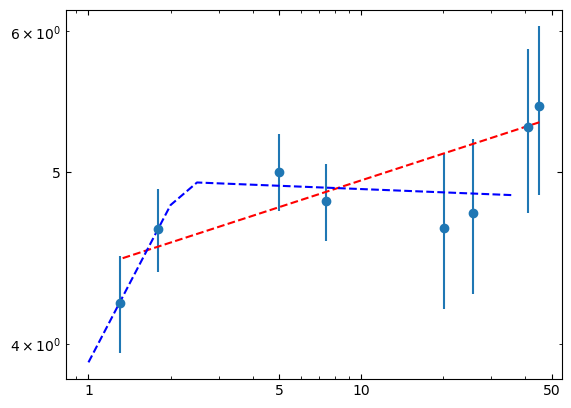

In [335]:
#plotting to check
fig,ax = plt.subplots()
mask = df25['Flux'] > 3 * df25['Error (gaussfit or image)']  # apply detection threshold
mask2 = df25['Flux'] < 3 * df25['Error (gaussfit or image)']  # apply detection threshold
if mask.any():  # proceed only if at least one detection
    ax.errorbar(df25['Freq'][mask], df25['Flux'][mask], yerr=yerr25, fmt='o')
    ax.scatter(df25['Freq'][mask2], (df25['Flux'][mask2] + 3*df25['Error (gaussfit or image)'][mask2]), marker='v')
    ax.set_xscale('log')
    ax.set_xticks([1, 5, 10, 50], labels=['1', '5', '10', '50'])
    ax.set_yscale('log')
    ax.set_yticks([1, 5, 10, 20, 50], labels=['1', '5', '10', '20', '50'])
    #ax.annotate('Day 359.6', xy=(90, 120), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
    ax.tick_params(axis='both', which='both', direction='in', top=True, right=True)
    ax.plot(df25['Freq'][mask], fit_model_weights25(df25['Freq'][mask]), 'r--')
    ax.plot(x_freq, fw_BPL25(x_freq), 'b--')
    #ax.annotate('${\u03B1 = 0.050 \\pm 0.016}$', xy=(90, 100), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))

plt.show();


### Day 469.6 (df26)

In [336]:
mask = df26['Flux'] > 3 * df26['Error (gaussfit or image)']  # apply detection threshold

x26 = df26['Freq'][mask].values.tolist()
y26 = df26['Flux'][mask].values.tolist()
yerr26 = df26['Error (gaussfit or image)'][mask].values.tolist()

In [337]:
yerr26 = error(yerr26, x26, y26)

In [374]:
#(work for anything with 3+ points)


PL26 =  PowerLaw1D(amplitude = y26[0], x_0= x26[0], alpha= -0.0) 

#Initialize fitters
#setting calc_uncertainties=True to output errors on measurement 

fit26 = fitting.LevMarLSQFitter(calc_uncertainties=True)

#Fit the data w/o weights
fit_model26 = fit26(PL26, x26, y26)


#weight is 1/error^2
y_weight26 = 1/ (np.power(yerr26, 2))  

# fit the data using the uncertainties as weights
fit_model_weights26 = fit26(PL26, x26, y26, weights=y_weight26)

fit_model_weights26


<PowerLaw1D(amplitude=2.16766327, x_0=52.78859484, alpha=0.15184981)>

In [375]:
fit26.fit_info

{'nfev': 11,
 'fvec': array([-8.76514959, -9.51722844, -2.8265939 , -0.48365557,  8.45214348,
        -6.15010936, -9.82855352,  5.35224775]),
 'fjac': array([[-5.96653422e+02, -1.00637212e+02, -6.27515638e-01,
          6.13422166e-02,  4.80443314e-01,  4.44164581e-01,
          4.44561094e-01,  6.07254078e-01],
        [-1.00637212e+02, -3.21773500e+01, -2.00639405e-01,
          3.44358523e-01,  5.32446204e-01,  1.70577260e-01,
         -3.17198607e-01, -5.68367517e-01],
        [-6.27515638e-01, -2.00639405e-01, -1.14439170e-16,
          1.21267813e-01,  2.42535625e-01,  1.21267813e-01,
          7.27606875e-01,  6.06339063e-01]]),
 'ipvt': array([2, 0, 1], dtype=int32),
 'qtf': array([ 4.97519584e-04,  1.63714435e-04, -1.80883022e+00]),
 'message': 'Both actual and predicted relative reductions in the sum of squares\n  are at most 0.000000',
 'ierr': 1,
 'param_jac': None,
 'param_cov': array([[ 2.96881076e+27, -4.76120147e+29, -6.74818422e+10],
        [-4.76120147e+29,  7.63573

In [376]:
#taking fvec
fvec26 = np.array([-8.76513175, -9.51720658, -2.82652487, -0.48357908,  8.45243427,
        -6.14988635, -9.8283998 ,  5.35243848])
var26 = np.var(fvec26)

#taking cov_x
cov_x26 = np.array([[ 2.07717850e+27, -2.45798116e+30, -2.22616752e+11],
        [-2.45798116e+30,  2.90859518e+33,  2.63428387e+14],
        [-2.22616752e+11,  2.63428387e+14,  5.41449706e-05]])

def stand(cov):
    diag = np.diagonal(cov)
    sd1 = np.sqrt(diag[0])
    sd2 = np.sqrt(diag[1])
    sd3 = np.sqrt(diag[2])
    return(sd1,sd2,sd3)

diag26 = stand(cov_x26*var26) 

#The last diagonal element corresponds to alpha
#So here we are calculating the standard deviation on the slope

#print(diag)  #prints standard deviations of all three variances

print('The error/standard deviation is', diag26[2]) #Just showing the standard deviation on the slope

Xhi = cs(df26['Flux'], fit_model_weights26( df26["Freq"] ))
print("The chi squared is", Xhi/(8-4))

The error/standard deviation is 0.04793772237176828
The chi squared is 1.0253447969328937


In [377]:
#Will output many BPL functions 
#Check through them, if they are very far off they won't work in fitBPL
BM26 = bpl_func(x_val, y26, yerr26, a1, a2)

#BM3[43] worked for me and gives me a reasonable output in fitBPL
BM26[40]

#Apply error as weighting in the function 

weight26 = 1/ (np.power(yerr26,2))
fw_BPL26 = fitBPL(BM26[40], x26, y26, weights=weight26)   
print(fw_BPL26)
print("")
print(fitBPL.fit_info)


#taking fvec
fvec4 = np.array( [ 0.41445631, -0.4494245 ,  0.03973522, -1.87748834,  5.98490253,
       -7.1629281 , -8.89513922,  7.17534241]  )
var4 = np.var(fvec4)

#taking cov_x
cov_x4 = np.array( [[ 6.41405094e-04, -2.96871356e-03, -1.21714245e-04,
         8.02982306e-04],
       [-2.96871356e-03,  4.99535240e-01, -1.21332246e-03,
        -4.53805398e-02],
       [-1.21714245e-04, -1.21332246e-03,  3.52025537e-05,
         8.13151629e-20],
       [ 8.02982306e-04, -4.53805398e-02,  8.13151629e-20,
         8.00716023e-03]]  )

def stand(cov):
    diag = np.diagonal(cov)
    sd1 = np.sqrt(diag[0])
    sd2 = np.sqrt(diag[1])
    sd3 = np.sqrt(diag[2]) #err 1
    sd4 = np.sqrt(diag[3]) #err 2
    return(sd1,sd2,sd3, sd4)

diag4 = stand(cov_x4*var4) 

#The last diagonal element corresponds to alpha
#So here we are calculating the standard deviation on the slope

#print(diag)  #prints standard deviations of all three variances
print("")
print('The error/standard deviation of the first one is', diag4[2], diag4[3]) #Just showing the standard deviation on the slope


Xhi = cs(df26['Flux'], fw_BPL26( df26["Freq"] ))
print("")
print("The chi squared is", Xhi/(8-4))

"""
#for plotting
x_freq = np.arange(1,36,0.5)

    #in the if
    ax.plot(df3['Freq'][mask], fw_BPL3(df3['Freq'][mask]), 'b--')
    ax.annotate('${\u03B1_1 = 0.68 \\pm 0.006}$', xy=(90, 160), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
    ax.annotate('${\u03B1_2 = 0.82 \\pm 0.21}$', xy=(90, 140), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
""";

Model: BrokenPowerLaw1D
Inputs: ('x',)
Outputs: ('y',)
Model set size: 1
Parameters:
        amplitude          x_break            alpha_1             alpha_2      
    ----------------- ------------------ ------------------ -------------------
    2.362211060382268 22.998790203032527 0.1722746785463288 -0.9766771328988864

{'nfev': 10, 'fvec': array([ 0.41445631, -0.4494245 ,  0.03973522, -1.87748834,  5.98490253,
       -7.1629281 , -8.89513922,  7.17534241]), 'fjac': array([[-4.22271743e+02,  0.00000000e+00,  0.00000000e+00,
         1.16483092e-02,  3.85159693e-01,  4.02685565e-01,
         4.79302404e-01,  6.77960079e-01],
       [-8.72790473e+01, -4.26188426e+01,  3.67205142e-01,
         3.36734396e-01,  5.67301169e-01,  2.10450734e-01,
        -2.77817744e-01, -5.19391427e-01],
       [ 0.00000000e+00,  5.85091361e+00, -1.60446454e+01,
         3.12149393e-01,  8.00096629e-01,  4.91707499e-01,
         1.09233772e-01,  4.05934044e-02],
       [-1.54435207e+00,  2.78247600e-01, 

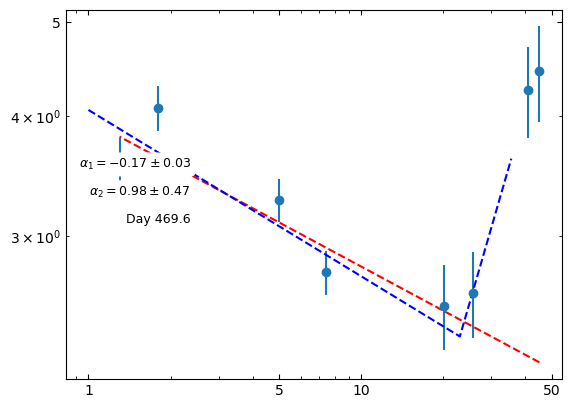

In [378]:
#plotting to check
fig,ax = plt.subplots()
mask = df26['Flux'] > 3 * df26['Error (gaussfit or image)']  # apply detection threshold
mask2 = df26['Flux'] < 3 * df26['Error (gaussfit or image)']  # apply detection threshold
if mask.any():  # proceed only if at least one detection
    ax.errorbar(df26['Freq'][mask], df26['Flux'][mask], yerr=yerr26, fmt='o')
    ax.scatter(df26['Freq'][mask2], (df26['Flux'][mask2] + 3*df26['Error (gaussfit or image)'][mask2]), marker='v')
    ax.set_xscale('log')
    ax.set_xticks([1, 5, 10, 50], labels=['1', '5', '10', '50'])
    ax.set_yscale('log')
    ax.set_yticks([1, 5, 10, 20, 50], labels=['1', '5', '10', '20', '50'])
    ax.annotate('Day 469.6', xy=(90, 120), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
    ax.tick_params(axis='both', which='both', direction='in', top=True, right=True)
    ax.plot(df26['Freq'][mask], fit_model_weights26(df26['Freq'][mask]), 'r--')
    ax.plot(x_freq, fw_BPL26(x_freq), 'b--')
    #ax.annotate('${\u03B1 = -0.152 \\pm 0.048}$', xy=(90, 100), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
    ax.annotate('${\u03B1_1 = -0.17 \\pm 0.03}$', xy=(90, 160), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
    ax.annotate('${\u03B1_2 = 0.98 \\pm 0.47}$', xy=(90, 140), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))

plt.show();


### Day 603.3 (df27)

In [379]:
mask = df27['Flux'] > 3 * df27['Error (gaussfit or image)']  # apply detection threshold

x27 = df27['Freq'][mask].values.tolist()
y27 = df27['Flux'][mask].values.tolist()
yerr27 = df27['Error (gaussfit or image)'][mask].values.tolist()

In [380]:
yerr27 = error(yerr27, x27, y27)

In [386]:
#(work for anything with 3+ points)


PL27 =  PowerLaw1D(amplitude = y27[0], x_0= x27[0], alpha= -0.0) 

#Initialize fitters
#setting calc_uncertainties=True to output errors on measurement 

fit27 = fitting.LevMarLSQFitter(calc_uncertainties=True)

#Fit the data w/o weights
fit_model27 = fit27(PL27, x27, y27)


#weight is 1/error^2
y_weight27 = 1/ (np.power(yerr27, 2))  

# fit the data using the uncertainties as weights
fit_model_weights27 = fit27(PL27, x27, y27, weights=y_weight27)

fit_model_weights27


<PowerLaw1D(amplitude=3.91171864, x_0=98.27548621, alpha=-0.03510044)>

In [387]:
fit27.fit_info

{'nfev': 10,
 'fvec': array([-2.92461911, -2.6178732 , -0.65001543,  0.20376762,  2.49525395,
        -0.56847711, -3.74018281, -0.88367268]),
 'fjac': array([[-4.56074036e+02, -4.16816289e+01,  5.82344141e-02,
          9.44712405e-02,  6.45942434e-01,  7.04503034e-01,
          2.44708168e-01,  1.00130019e-01],
        [-4.16816289e+01, -7.75934674e+00,  1.08407714e-02,
          3.50190266e-01,  3.15583332e-02, -5.04354269e-01,
         -4.90513825e-01, -2.29007929e-01],
        [ 5.82344141e-02,  1.08407714e-02,  2.94934877e-18,
         -0.00000000e+00, -9.55779009e-01, -0.00000000e+00,
         -0.00000000e+00, -0.00000000e+00]]),
 'ipvt': array([2, 0, 1], dtype=int32),
 'qtf': array([-1.36075126e-04,  1.27641434e-05,  4.11296345e+00]),
 'message': 'Both actual and predicted relative reductions in the sum of squares\n  are at most 0.000000',
 'ierr': 1,
 'param_jac': None,
 'param_cov': array([[ 2.24397384e+29,  1.60613765e+32, -1.33966922e+12],
        [ 1.60613765e+32,  1.14960

In [388]:
#taking fvec
fvec27 = np.array([-2.92460789, -2.61786169, -0.65000657,  0.20377359,  2.49521614,
        -0.56853628, -3.74021385, -0.88368632])
var27 = np.var(fvec27)

#taking cov_x
cov_x27 = np.array([[ 4.82304217e+28,  3.81693403e+31, -2.14928546e+11],
        [ 3.81693403e+31,  3.02070454e+34, -1.70093491e+14],
        [-2.14928546e+11, -1.70093491e+14,  1.44494757e-04]])

def stand(cov):
    diag = np.diagonal(cov)
    sd1 = np.sqrt(diag[0])
    sd2 = np.sqrt(diag[1])
    sd3 = np.sqrt(diag[2])
    return(sd1,sd2,sd3)

diag27 = stand(cov_x27*var27) 

#The last diagonal element corresponds to alpha
#So here we are calculating the standard deviation on the slope

#print(diag)  #prints standard deviations of all three variances

print('The error/standard deviation is', diag27[2]) #Just showing the standard deviation on the slope

Xhi = cs(df27['Flux'], fit_model_weights27( df27["Freq"] ))
print("The chi squared is", Xhi/(8-4))

The error/standard deviation is 0.02239162720280233
The chi squared is 0.06938417394269351


In [389]:
#Will output many BPL functions 
#Check through them, if they are very far off they won't work in fitBPL
BM27 = bpl_func(x_val, y27, yerr27, a1, a2)

#BM3[43] worked for me and gives me a reasonable output in fitBPL
BM12[40]

#Apply error as weighting in the function 

weight27 = 1/ (np.power(yerr27,2))
fw_BPL27 = fitBPL(BM27[40], x27, y27, weights=weight27)   
print(fw_BPL27)
print("")
print(fitBPL.fit_info)

"""
#taking fvec
fvec4 = np.array(   )
var4 = np.var(fvec4)

#taking cov_x
cov_x4 = np.array(   )

def stand(cov):
    diag = np.diagonal(cov)
    sd1 = np.sqrt(diag[0])
    sd2 = np.sqrt(diag[1])
    sd3 = np.sqrt(diag[2]) #err 1
    sd4 = np.sqrt(diag[3]) #err 2
    return(sd1,sd2,sd3, sd4)

diag4 = stand(cov_x4*var4) 

#The last diagonal element corresponds to alpha
#So here we are calculating the standard deviation on the slope

#print(diag)  #prints standard deviations of all three variances
print("")
print('The error/standard deviation of the first one is', diag4[2], diag4[3]) #Just showing the standard deviation on the slope
"""

Xhi = cs(df27['Flux'], fw_BPL27( df27["Freq"] ))
print("")
print("The chi squared is", Xhi/(8-4))

"""
#for plotting
x_freq = np.arange(1,36,0.5)

    #in the if
    ax.plot(df3['Freq'][mask], fw_BPL3(df3['Freq'][mask]), 'b--')
    ax.annotate('${\u03B1_1 = 0.68 \\pm 0.006}$', xy=(90, 160), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
    ax.annotate('${\u03B1_2 = 0.82 \\pm 0.21}$', xy=(90, 140), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
""";

Model: BrokenPowerLaw1D
Inputs: ('x',)
Outputs: ('y',)
Model set size: 1
Parameters:
        amplitude           x_break             alpha_1             alpha_2       
    ------------------ ------------------ ------------------- --------------------
    3.4632768863210046 6.9204062727599265 0.06995340728220761 -0.10251642960816947

{'nfev': 8, 'fvec': array([-1.19604972, -0.82466848,  0.88941631,  1.40376165, -0.21846789,
        0.02831914, -0.40712814,  0.78858421]), 'fjac': array([[ 6.87764971e+01,  5.31554752e-01,  5.06398690e-01,
         4.39485353e-01,  1.08330269e-01, -0.00000000e+00,
        -0.00000000e+00, -0.00000000e+00],
       [ 0.00000000e+00, -5.85722390e+01,  0.00000000e+00,
         0.00000000e+00,  0.00000000e+00,  6.01978135e-01,
         7.18138585e-01,  3.49140799e-01],
       [-1.68392400e+01, -2.65649595e+01, -3.61466887e+01,
         4.71728296e-02,  8.44035631e-01,  4.55842192e-01,
        -2.40434386e-01, -1.40500737e-01],
       [ 8.63916121e-01, -9.299800

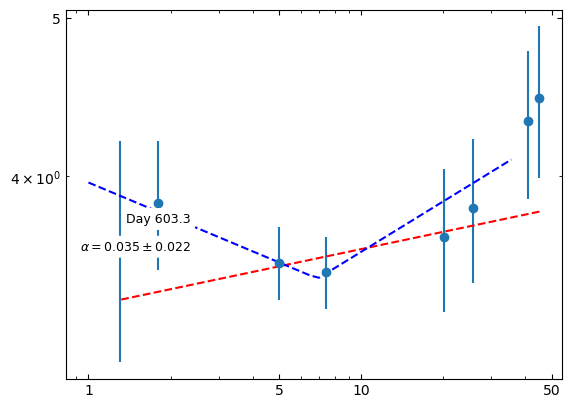

In [390]:
#plotting to check
fig,ax = plt.subplots()
mask = df27['Flux'] > 3 * df27['Error (gaussfit or image)']  # apply detection threshold
mask2 = df27['Flux'] < 3 * df27['Error (gaussfit or image)']  # apply detection threshold
if mask.any():  # proceed only if at least one detection
    ax.errorbar(df27['Freq'][mask], df27['Flux'][mask], yerr=yerr27, fmt='o')
    ax.set_xscale('log')
    ax.set_xticks([1, 5, 10, 50], labels=['1', '5', '10', '50'])
    ax.set_yscale('log')
    ax.set_yticks([1, 5, 10, 20, 50], labels=['1', '5', '10', '20', '50'])
    ax.annotate('Day 603.3', xy=(90, 120), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
    ax.tick_params(axis='both', which='both', direction='in', top=True, right=True)
    ax.plot(df27['Freq'][mask], fit_model_weights27(df27['Freq'][mask]), 'r--')
    ax.plot(x_freq, fw_BPL27(x_freq), 'b--')
    ax.annotate('${\u03B1 = 0.035 \\pm 0.022}$', xy=(90, 100), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))

plt.show();


### Day 669.0 (df28)

In [391]:
mask = df28['Flux'] > 3 * df28['Error (gaussfit or image)']  # apply detection threshold

x28 = df28['Freq'][mask].values.tolist()
y28 = df28['Flux'][mask].values.tolist()
yerr28 = df28['Error (gaussfit or image)'][mask].values.tolist()

In [392]:
yerr28 = error(yerr28, x28, y28)

In [394]:
#(work for anything with 3+ points)


PL28 =  PowerLaw1D(amplitude = y28[0], x_0= x28[0], alpha= -0.0) 

#Initialize fitters
#setting calc_uncertainties=True to output errors on measurement 

fit28 = fitting.LevMarLSQFitter(calc_uncertainties=True)

#Fit the data w/o weights
fit_model28 = fit28(PL28, x28, y28)


#weight is 1/error^2
y_weight28 = 1/ (np.power(yerr28, 2))  

# fit the data using the uncertainties as weights
fit_model_weights28 = fit28(PL28, x28, y28, weights=y_weight28)

fit_model_weights28


<PowerLaw1D(amplitude=3.19277333, x_0=123.63593885, alpha=-0.00121543)>

In [395]:
fit28.fit_info

{'nfev': 9,
 'fvec': array([-4.94048083, -3.65930909,  2.09840423,  0.45366329,  1.09298133,
        -1.09833152, -0.41745035, -1.38116861]),
 'fjac': array([[-5.07147550e+02, -5.39397960e+01,  1.69302352e-03,
          1.13202810e-01,  6.92972054e-01,  6.98083754e-01,
          7.92176958e-02,  2.60354625e-02],
        [-5.39397960e+01, -8.07208779e+00,  2.53360886e-04,
          4.47799987e-01,  7.74822483e-02, -5.18140838e-01,
         -1.76176702e-01, -6.65556418e-02],
        [ 1.69302352e-03,  2.53360886e-04, -1.76345669e-19,
          2.30556167e-01, -1.92130139e-02,  9.22224668e-01,
          3.84260278e-02,  0.00000000e+00]]),
 'ipvt': array([2, 0, 1], dtype=int32),
 'qtf': array([-4.30138050e-05, -4.76084834e-06, -2.55796107e+00]),
 'message': 'Both actual and predicted relative reductions in the sum of squares\n  are at most 0.000000',
 'ierr': 1,
 'param_jac': None,
 'param_cov': array([[ 3.16794616e+28,  1.00930889e+33, -5.77692906e+11],
        [ 1.00930889e+33,  3.215662

In [396]:
#taking fvec
fvec28 = np.array([-4.94048134, -3.65931011,  2.09840154,  0.45366064,  1.092968  ,
        -1.0983443 , -0.41745167, -1.38116903])
var28 = np.var(fvec28)

#taking cov_x
cov_x28 = np.array([[6.36113596e+28, 1.09470760e+33, 3.37371949e+12],
        [1.09470760e+33, 1.88391622e+37, 5.80593839e+16],
        [3.37371949e+12, 5.80593839e+16, 3.56428147e-04]])

def stand(cov):
    diag = np.diagonal(cov)
    sd1 = np.sqrt(diag[0])
    sd2 = np.sqrt(diag[1])
    sd3 = np.sqrt(diag[2])
    return(sd1,sd2,sd3)

diag28 = stand(cov_x28*var28) 

#The last diagonal element corresponds to alpha
#So here we are calculating the standard deviation on the slope

#print(diag)  #prints standard deviations of all three variances

print('The error/standard deviation is', diag28[2]) #Just showing the standard deviation on the slope

Xhi = cs(df28['Flux'], fit_model_weights28( df28["Freq"] ))
print("The chi squared is", Xhi/(8-4))

The error/standard deviation is 0.04178293176824778
The chi squared is 0.5565957246701262


In [397]:
#Will output many BPL functions 
#Check through them, if they are very far off they won't work in fitBPL
BM28 = bpl_func(x_val, y28, yerr28, a1, a2)

#BM3[43] worked for me and gives me a reasonable output in fitBPL
BM28[40]

#Apply error as weighting in the function 

weight28 = 1/ (np.power(yerr28,2))
fw_BPL28 = fitBPL(BM28[40], x28, y28, weights=weight28)   
print(fw_BPL28)
print("")
print(fitBPL.fit_info)


#taking fvec
fvec4 = np.array( [-4.6618352 , -3.15186233,  2.81781388,  0.91344918, -0.33563898,
       -0.00966272,  0.43083925, -1.04520077]  )
var4 = np.var(fvec4)

#taking cov_x
cov_x4 = np.array( [[ 1.04285078e-03,  4.03786271e-02, -2.13750054e-03,
         1.73168049e-04],
       [ 4.03786271e-02,  4.53740144e+00, -1.71550964e-01,
        -5.18367813e-03],
       [-2.13750054e-03, -1.71550964e-01,  7.72101810e-03,
         2.98155597e-19],
       [ 1.73168049e-04, -5.18367813e-03,  2.98155597e-19,
         3.01942542e-04]]  )

def stand(cov):
    diag = np.diagonal(cov)
    sd1 = np.sqrt(diag[0])
    sd2 = np.sqrt(diag[1])
    sd3 = np.sqrt(diag[2]) #err 1
    sd4 = np.sqrt(diag[3]) #err 2
    return(sd1,sd2,sd3, sd4)

diag4 = stand(cov_x4*var4) 

#The last diagonal element corresponds to alpha
#So here we are calculating the standard deviation on the slope

#print(diag)  #prints standard deviations of all three variances
print("")
print('The error/standard deviation of the first one is', diag4[2], diag4[3]) #Just showing the standard deviation on the slope


Xhi = cs(df28['Flux'], fw_BPL28( df28["Freq"] ))
print("")
print("The chi squared is", Xhi/(8-4))

"""
#for plotting
x_freq = np.arange(1,36,0.5)

    #in the if
    ax.plot(df3['Freq'][mask], fw_BPL3(df3['Freq'][mask]), 'b--')
    ax.annotate('${\u03B1_1 = 0.68 \\pm 0.006}$', xy=(90, 160), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
    ax.annotate('${\u03B1_2 = 0.82 \\pm 0.21}$', xy=(90, 140), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
""";

Model: BrokenPowerLaw1D
Inputs: ('x',)
Outputs: ('y',)
Model set size: 1
Parameters:
        amplitude          x_break           alpha_1             alpha_2       
    ----------------- ----------------- ----------------- ---------------------
    3.138845446113475 6.850082232298809 0.072904708751584 -0.027191861698521894

{'nfev': 7, 'fvec': array([-4.6618352 , -3.15186233,  2.81781388,  0.91344918, -0.33563898,
       -0.00966272,  0.43083925, -1.04520077]), 'fjac': array([[ 6.65688524e+01,  4.20666311e-01,  6.94522375e-01,
         5.18473504e-01,  1.43117987e-01, -0.00000000e+00,
        -0.00000000e+00, -0.00000000e+00],
       [-2.13577333e+01,  5.12065570e+01,  4.61954163e-02,
        -2.11304950e-03, -7.13133637e-01, -6.93406940e-01,
        -6.43748779e-02, -2.01253431e-02],
       [ 0.00000000e+00,  2.53281571e+01, -2.84556860e+01,
        -1.76972778e-03, -5.97265898e-01,  6.52305606e-01,
         4.32047730e-01,  1.72062706e-01],
       [ 2.66114310e-01,  5.01921492e-01, -

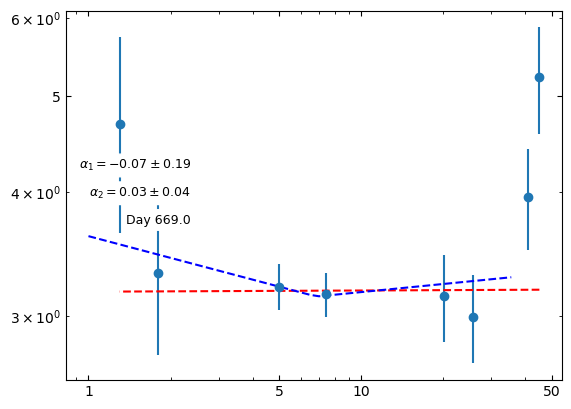

In [398]:
#plotting to check
fig,ax = plt.subplots()
mask = df28['Flux'] > 3 * df28['Error (gaussfit or image)']  # apply detection threshold
mask2 = df28['Flux'] < 3 * df28['Error (gaussfit or image)']  # apply detection threshold
if mask.any():  # proceed only if at least one detection
    ax.errorbar(df28['Freq'][mask], df28['Flux'][mask], yerr=yerr28, fmt='o')
    ax.scatter(df28['Freq'][mask2], (df28['Flux'][mask2] + 3*df28['Error (gaussfit or image)'][mask2]), marker='v')
    ax.set_xscale('log')
    ax.set_xticks([1, 5, 10, 50], labels=['1', '5', '10', '50'])
    ax.set_yscale('log')
    ax.set_yticks([1, 5, 10, 20, 50], labels=['1', '5', '10', '20', '50'])
    ax.annotate('Day 669.0', xy=(90, 120), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
    ax.tick_params(axis='both', which='both', direction='in', top=True, right=True)
    ax.plot(df28['Freq'][mask], fit_model_weights28(df28['Freq'][mask]), 'r--')
    ax.plot(x_freq, fw_BPL28(x_freq), 'b--')
    #ax.annotate('${\u03B1 = 0.001 \\pm 0.042}$', xy=(90, 100), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
    ax.annotate('${\u03B1_1 = -0.07 \\pm 0.19}$', xy=(90, 160), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
    ax.annotate('${\u03B1_2 = 0.03 \\pm 0.04}$', xy=(90, 140), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))

plt.show();


### Day 769.6 (df29)

In [399]:
mask = df29['Flux'] > 3 * df29['Error (gaussfit or image)']  # apply detection threshold

x29 = df29['Freq'][mask].values.tolist()
y29 = df29['Flux'][mask].values.tolist()
yerr29 = df29['Error (gaussfit or image)'][mask].values.tolist()

In [400]:
yerr29 = error(yerr29, x29, y29)

In [402]:
#(work for anything with 3+ points)


PL29 =  PowerLaw1D(amplitude = y29[0], x_0= x29[0], alpha= -0.0) 

#Initialize fitters
#setting calc_uncertainties=True to output errors on measurement 

fit29 = fitting.LevMarLSQFitter(calc_uncertainties=True)

#Fit the data w/o weights
fit_model29 = fit29(PL29, x29, y29)


#weight is 1/error^2
y_weight29 = 1/ (np.power(yerr29, 2))  

# fit the data using the uncertainties as weights
fit_model_weights29 = fit29(PL29, x29, y29, weights=y_weight29)

fit_model_weights29


<PowerLaw1D(amplitude=2.67366538, x_0=51.01400124, alpha=0.03461684)>

In [403]:
fit29.fit_info

{'nfev': 9,
 'fvec': array([ 0.19201124, -1.68040998, -2.54914397, -1.76534618,  2.76708251,
        -0.70391988, -4.21821537,  0.85402682]),
 'fjac': array([[-4.42349654e+02, -7.48395575e+01, -1.35780138e-01,
          6.72023568e-02,  6.22474260e-01,  6.91615030e-01,
          2.77340788e-01,  2.24447644e-01],
        [-7.48395575e+01, -1.93262454e+01, -3.50632788e-02,
          3.32593559e-01,  1.19436726e-01, -3.84934029e-01,
         -4.66633374e-01, -4.28587783e-01],
        [-1.35780138e-01, -3.50632788e-02,  1.74553183e-17,
         -0.00000000e+00, -4.47213595e-01,  7.95046392e-01,
          3.97523196e-01, -0.00000000e+00]]),
 'ipvt': array([2, 0, 1], dtype=int32),
 'qtf': array([1.17060590e-04, 3.84175032e-05, 4.40068659e+00]),
 'message': 'Both actual and predicted relative reductions in the sum of squares\n  are at most 0.000000',
 'ierr': 1,
 'param_jac': None,
 'param_cov': array([[ 1.08032525e+28, -5.95455748e+30, -2.39095157e+11],
        [-5.95455748e+30,  3.28204443e

In [404]:
#taking fvec
fvec29 = np.array([ 0.19202563, -1.6803929 , -2.54912414, -1.76532582,  2.76716135,
        -0.70385145, -4.21819949,  0.85403778])
var29 = np.var(fvec29)

#taking cov_x
cov_x29 = np.array([[ 3.23834871e+28, -2.28767114e+31, -8.81028745e+11],
        [-2.28767114e+31,  1.61608267e+34,  6.22386349e+14],
        [-8.81028745e+11,  6.22386349e+14,  1.05716595e-04]])

def stand(cov):
    diag = np.diagonal(cov)
    sd1 = np.sqrt(diag[0])
    sd2 = np.sqrt(diag[1])
    sd3 = np.sqrt(diag[2])
    return(sd1,sd2,sd3)

diag29 = stand(cov_x29*var29) 

#The last diagonal element corresponds to alpha
#So here we are calculating the standard deviation on the slope

#print(diag)  #prints standard deviations of all three variances

print('The error/standard deviation is', diag29[2]) #Just showing the standard deviation on the slope

Xhi = cs(df29['Flux'], fit_model_weights29( df29["Freq"] ))
print("The chi squared is", Xhi/(8-4))

The error/standard deviation is 0.020832631609869753
The chi squared is 0.02122095947396154


In [405]:
#Will output many BPL functions 
#Check through them, if they are very far off they won't work in fitBPL
BM29 = bpl_func(x_val, y29, yerr29, a1, a2)

#BM3[43] worked for me and gives me a reasonable output in fitBPL
BM29[40]

#Apply error as weighting in the function 

weight29 = 1/ (np.power(yerr29,2))
fw_BPL29 = fitBPL(BM29[40], x29, y29, weights=weight29)   
print(fw_BPL29)
print("")
print(fitBPL.fit_info)

"""
#taking fvec
fvec4 = np.array(   )
var4 = np.var(fvec4)

#taking cov_x
cov_x4 = np.array(   )

def stand(cov):
    diag = np.diagonal(cov)
    sd1 = np.sqrt(diag[0])
    sd2 = np.sqrt(diag[1])
    sd3 = np.sqrt(diag[2]) #err 1
    sd4 = np.sqrt(diag[3]) #err 2
    return(sd1,sd2,sd3, sd4)

diag4 = stand(cov_x4*var4) 

#The last diagonal element corresponds to alpha
#So here we are calculating the standard deviation on the slope

#print(diag)  #prints standard deviations of all three variances
print("")
print('The error/standard deviation of the first one is', diag4[2], diag4[3]) #Just showing the standard deviation on the slope
"""

Xhi = cs(df29['Flux'], fw_BPL29( df29["Freq"] ))
print("")
print("The chi squared is", Xhi/(8-4))

"""
#for plotting
x_freq = np.arange(1,36,0.5)

    #in the if
    ax.plot(df3['Freq'][mask], fw_BPL3(df3['Freq'][mask]), 'b--')
    ax.annotate('${\u03B1_1 = 0.68 \\pm 0.006}$', xy=(90, 160), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
    ax.annotate('${\u03B1_2 = 0.82 \\pm 0.21}$', xy=(90, 140), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
""";

Model: BrokenPowerLaw1D
Inputs: ('x',)
Outputs: ('y',)
Model set size: 1
Parameters:
        amplitude          x_break            alpha_1             alpha_2       
    ----------------- ----------------- ------------------- --------------------
    2.813043406696752 7.400000412707765 0.08298608454531098 -0.01419304206540051

{'nfev': 35, 'fvec': array([ 1.7155368 ,  0.02939816, -1.17656856, -0.70251158,  0.50111807,
       -0.31511566, -2.2461323 ,  2.76077642]), 'fjac': array([[-9.05846193e+01,  0.00000000e+00,  3.09410019e+00,
         9.76077579e-02,  8.64154379e-08,  5.71745050e-01,
         6.03273989e-01,  5.56028859e-01],
       [ 0.00000000e+00,  7.86472397e+01, -9.85161081e-01,
         5.31529565e-03, -4.34442584e-08, -2.87437526e-01,
        -3.03288298e-01, -2.79536412e-01],
       [-4.08649028e+01, -1.96928226e+01, -5.78103615e+01,
         1.75326391e-01,  8.63083356e-01,  4.23032231e-01,
        -1.73083016e-01, -2.00523334e-01],
       [-1.28914104e+00,  1.06249807e-0

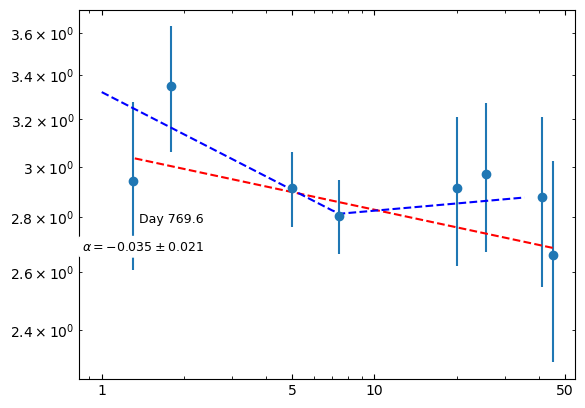

In [406]:
#plotting to check
fig,ax = plt.subplots()
mask = df29['Flux'] > 3 * df29['Error (gaussfit or image)']  # apply detection threshold
mask2 = df29['Flux'] < 3 * df29['Error (gaussfit or image)']  # apply detection threshold
if mask.any():  # proceed only if at least one detection
    ax.errorbar(df29['Freq'][mask], df29['Flux'][mask], yerr=yerr29, fmt='o')
    ax.scatter(df29['Freq'][mask2], (df29['Flux'][mask2] + 3*df29['Error (gaussfit or image)'][mask2]), marker='v')
    ax.set_xscale('log')
    ax.set_xticks([1, 5, 10, 50], labels=['1', '5', '10', '50'])
    ax.set_yscale('log')
    ax.set_yticks([1, 5, 10, 20, 50], labels=['1', '5', '10', '20', '50'])
    ax.annotate('Day 769.6', xy=(90, 120), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
    ax.tick_params(axis='both', which='both', direction='in', top=True, right=True)
    ax.plot(df29['Freq'][mask], fit_model_weights29(df29['Freq'][mask]), 'r--')
    ax.plot(x_freq, fw_BPL29(x_freq),  'b--')
    ax.annotate('${\u03B1 = -0.035 \\pm 0.021}$', xy=(90, 100), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))

plt.show();


## Now all together with their alpha

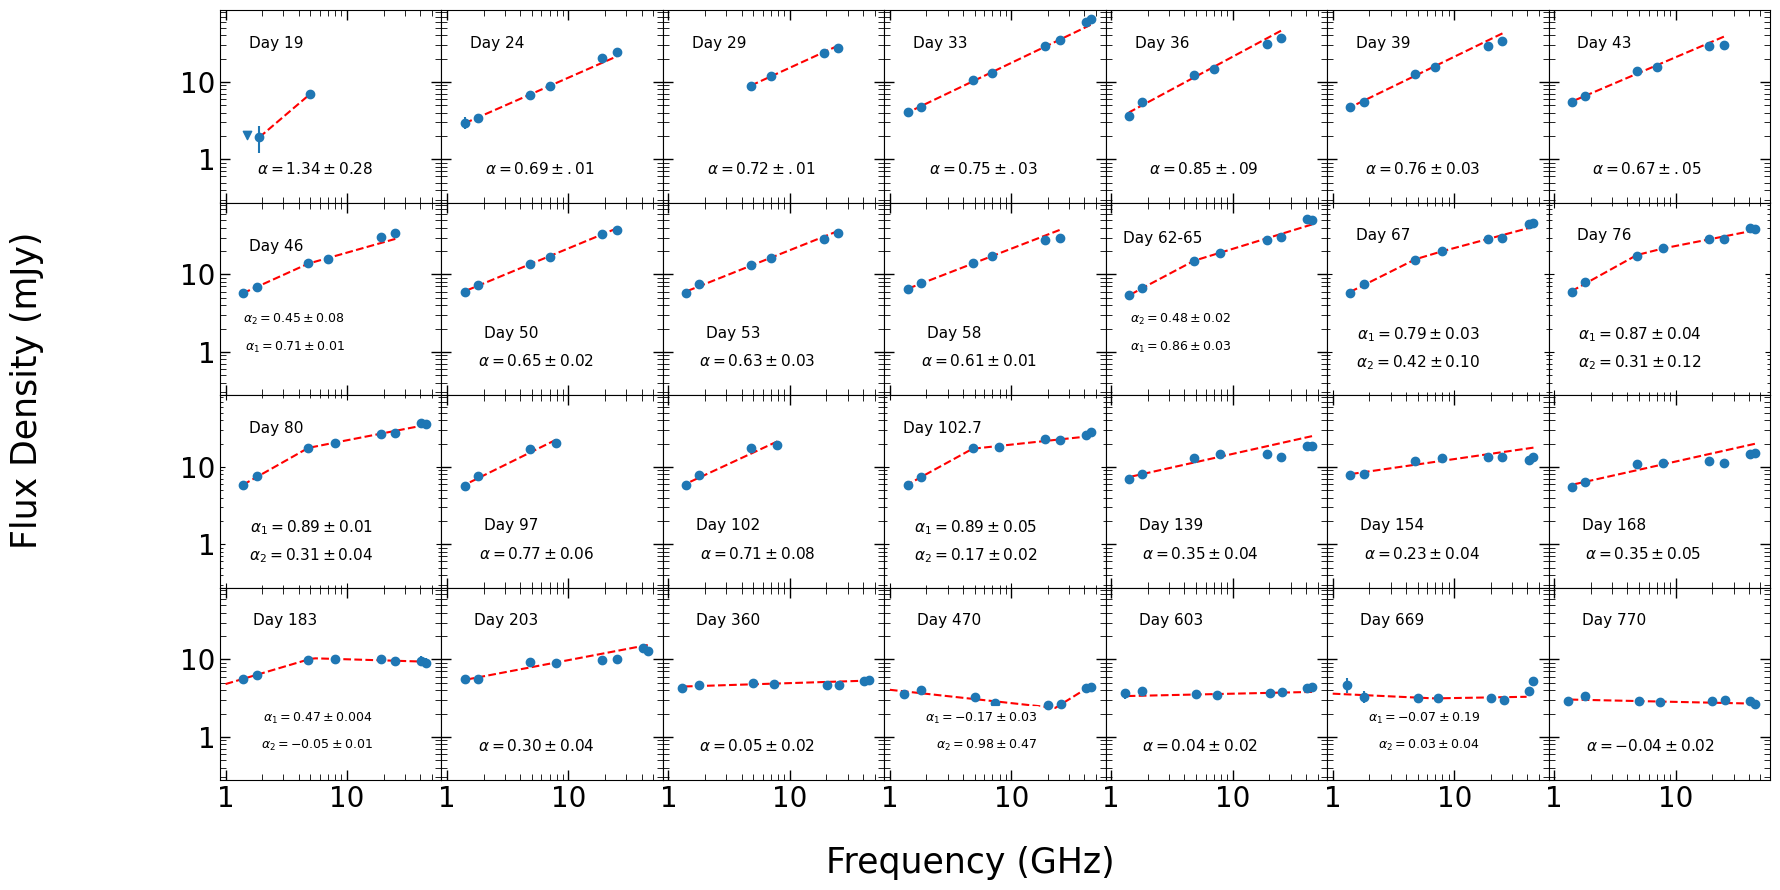

In [416]:
#CHANGE TO 4X7 TABLE, NO DAY 17, COMBIENS 13
x_freq = np.arange(1,40,0.5)
fig, ax = plt.subplots(4, 7, sharex='all', sharey='all',squeeze=True, width_ratios=None, height_ratios=None)
fig.set_size_inches(20,10)
fig.subplots_adjust(hspace=0, wspace=0)

#first row
#df 2
mask = df2['Flux'] > 3 * df2['Error (gaussfit or image)']  # apply detection threshold
mask2 = df2['Flux'] < 3 * df2['Error (gaussfit or image)']  # apply nondetection threshold
ax[0, 0].errorbar(df2['Freq'][mask], df2['Flux'][mask], yerr=yerr2,fmt='o' )
ax[0,0].scatter(df2['Freq'][mask2], (df2['Flux'][mask2] + 3*df2['Error (gaussfit or image)'][mask2]), marker='v')
ax[0,0].set_xscale('log')
ax[0,0].set_xticks([1,5,10,50], labels = ['1','5','10','50'], fontsize = 20)
ax[0,0].set_yscale('log')
ax[0,0].set_yticks([1,5,10,20,50, 100], labels = ['1','5','10','20','50', '100'], fontsize = 20)
ax[0,0].annotate('Day 19', xy=(60, 120), xycoords='axes points', size=11, ha='right', va='top',bbox=dict(boxstyle='round', fc='w', ec="w"))
ax[0,0].tick_params(which='minor', length =4, direction = 'in', top=True, labeltop=False, bottom=True, labelbottom=False, right = True,labelright = False)
ax[0,0].tick_params(which='major', length=7, direction = 'in', width =1, top=True, labeltop=False, bottom=True, labelbottom=True, right = True, labelright = False)
ax[0,0].plot(df2['Freq'][mask], fit_model_weights2(df2['Freq'][mask]), 'r--')
ax[0,0].annotate('${\u03B1 = 1.34 \\pm 0.28}$', xy=(110, 30), xycoords='axes points', size=11, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))


mask = df3['Flux'] > 3 * df3['Error (gaussfit or image)']  # apply detection threshold
mask2 = df3['Flux'] < 3 * df3['Error (gaussfit or image)']  # apply nondetection threshold
ax[0, 1].errorbar(df3['Freq'][mask], df3['Flux'][mask], yerr=yerr3,fmt='o')
ax[0,1].scatter(df3['Freq'][mask2], (df3['Flux'][mask2] + 3*df3['Error (gaussfit or image)'][mask2]), marker='v')
ax[0,1].set_xscale('log')
ax[0,1].set_xticks([1,5,10,50], labels = ['1','5','10','50'], fontsize = 11)
ax[0,1].set_yscale('log')
ax[0,1].set_yticks([1,5,10,20,50, 100], labels = ['1','5','10','20','50', '100'], fontsize = 11)
ax[0,1].annotate('Day 24', xy=(60, 120), xycoords='axes points',size=11, ha='right', va='top',bbox=dict(boxstyle='round', fc='w', ec="w"))
ax[0,1].tick_params(which='minor', length =4, direction = 'in', top=True, labeltop=False, bottom=True, labelbottom=False, right = True,labelright = False)
ax[0,1].tick_params(which='major', length=7, direction = 'in', width =1, top=True, labeltop=False, bottom=True, labelbottom=True, right = True, labelright = False)
ax[0,1].plot(df3['Freq'][mask], fit_model_weights3(df3['Freq'][mask]), 'r--')
ax[0,1].annotate('${\u03B1 = 0.69 \\pm .01}$', xy=(110, 30), xycoords='axes points', size=11, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))


mask = df4['Flux'] > 3 * df4['Error (gaussfit or image)']  # apply detection threshold
mask2 = df4['Flux'] < 3 * df4['Error (gaussfit or image)']  # apply detection threshold
ax[0,2].errorbar(df4['Freq'][mask], df4['Flux'][mask], yerr=yerr4, fmt='o')
ax[0,2].scatter(df4['Freq'][mask2], (df4['Flux'][mask2] + 3*df4['Error (gaussfit or image)'][mask2]), marker='v')
ax[0,2].set_xscale('log')
ax[0,2].set_xticks([1,5,10,50], labels = ['1','5','10','50'], fontsize = 11)
ax[0,2].set_yscale('log')
ax[0,2].set_yticks([1,5,10,20,50, 100], labels = ['1','5','10','20','50', '100'], fontsize = 11)
ax[0,2].annotate('Day 29', xy=(60, 120), xycoords='axes points', size=11, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
ax[0,2].tick_params(which='minor', length =4, direction = 'in', top=True, labeltop=False, bottom=True, labelbottom=False, right = True,labelright = False)
ax[0,2].tick_params(which='major', length=7, direction = 'in', width =1, top=True, labeltop=False, bottom=True, labelbottom=True, right = True, labelright = False)
ax[0,2].plot(df4['Freq'][mask], fit_model_weights4(df4['Freq'][mask]), 'r--')
ax[0,2].annotate('${\u03B1 = 0.72 \\pm .01}$', xy=(110, 30), xycoords='axes points', size=11, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))


mask = df5['Flux'] > 3 * df5['Error (gaussfit or image)']  # apply detection threshold
mask2 = df5['Flux'] < 3 * df5['Error (gaussfit or image)']  # apply detection threshold
ax[0,3].errorbar(df5['Freq'][mask], df5['Flux'][mask], yerr=yerr5, fmt='o')
ax[0,3].scatter(df5['Freq'][mask2], (df5['Flux'][mask2] + 3*df5['Error (gaussfit or image)'][mask2]), marker='v')
ax[0,3].set_xscale('log')
ax[0,3].set_xticks([1,5,10,50], labels = ['1','5','10','50'], fontsize = 11)
ax[0,3].set_yscale('log')
ax[0,3].set_yticks([1,5,10,20,50, 100], labels = ['1','5','10','20','50', '100'], fontsize = 11)
ax[0,3].annotate('Day 33', xy=(60, 120), xycoords='axes points', size=11, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
ax[0,3].tick_params(which='minor', length =4, direction = 'in', top=True, labeltop=False, bottom=True, labelbottom=False, right = True,labelright = False)
ax[0,3].tick_params(which='major', length=7, direction = 'in', width =1, top=True, labeltop=False, bottom=True, labelbottom=True, right = True, labelright = False)
ax[0,3].plot(df5['Freq'][mask], fit_model_weights5(df5['Freq'][mask]), 'r--')
ax[0,3].annotate('${\u03B1 = 0.75 \\pm .03}$', xy=(110, 30), xycoords='axes points', size=11, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))


mask = df6['Flux'] > 3 * df6['Error (gaussfit or image)']  # apply detection threshold
mask2 = df6['Flux'] < 3 * df6['Error (gaussfit or image)']  # apply detection threshold
ax[0,4].errorbar(df6['Freq'][mask], df6['Flux'][mask], yerr=yerr6, fmt='o')
ax[0,4].scatter(df6['Freq'][mask2], (df6['Flux'][mask2] + 3*df6['Error (gaussfit or image)'][mask2]), marker='v')
ax[0,4].set_xscale('log')
ax[0,4].set_xticks([1,5,10,50], labels = ['1','5','10','50'], fontsize = 20)
ax[0,4].set_yscale('log')
ax[0,4].set_yticks([1,5,10,20,50, 100], labels = ['1','5','10','20','50', '100'], fontsize = 20)
ax[0,4].annotate('Day 36', xy=(60, 120), xycoords='axes points', size=11, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
ax[0,4].tick_params(which='minor', length =4, direction = 'in', top=True, labeltop=False, bottom=True, labelbottom=False, right = True,labelright = False)
ax[0,4].tick_params(which='major', length=7, direction = 'in', width =1, top=True, labeltop=False, bottom=True, labelbottom=True, right = True, labelright = False)
ax[0,4].plot(df6['Freq'][mask], fit_model_weights6(df6['Freq'][mask]), 'r--')
ax[0,4].annotate('${\u03B1 = 0.85 \\pm .09}$', xy=(110, 30), xycoords='axes points', size=11, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))


mask = df7['Flux'] > 3 * df7['Error (gaussfit or image)']  # apply detection threshold
mask2 = df7['Flux'] < 3 * df7['Error (gaussfit or image)']  # apply detection threshold
ax[0,5].errorbar(df7['Freq'][mask], df7['Flux'][mask], yerr=yerr7, fmt='o')
ax[0,5].scatter(df7['Freq'][mask2], (df7['Flux'][mask2] + 3*df7['Error (gaussfit or image)'][mask2]), marker='v')
ax[0,5].set_xscale('log')
ax[0,5].set_xticks([1,5,10,50], labels = ['1','5','10','50'], fontsize = 11)
ax[0,5].set_yscale('log')
ax[0,5].set_yticks([1,5,10,20,50, 100], labels = ['1','5','10','20','50', '100'], fontsize = 11)
ax[0,5].annotate('Day 39', xy=(60, 120), xycoords='axes points', size=11, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
ax[0,5].tick_params(which='minor', length =4, direction = 'in', top=True, labeltop=False, bottom=True, labelbottom=False, right = True,labelright = False)
ax[0,5].tick_params(which='major', length=7, direction = 'in', width =1, top=True, labeltop=False, bottom=True, labelbottom=True, right = True, labelright = False)
ax[0,5].plot(df7['Freq'][mask], fit_model_weights7(df7['Freq'][mask]), 'r--')
ax[0,5].annotate('${\u03B1 = 0.76 \\pm 0.03}$', xy=(110, 30), xycoords='axes points', size=11, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))

mask = df8['Flux'] > 3 * df8['Error (gaussfit or image)']  # apply detection threshold
mask2 = df8['Flux'] < 3 * df8['Error (gaussfit or image)']  # apply detection threshold
ax[0,6].errorbar(df8['Freq'][mask], df8['Flux'][mask], yerr=yerr8, fmt='o')
ax[0,6].scatter(df8['Freq'][mask2], (df8['Flux'][mask2] + 3*df8['Error (gaussfit or image)'][mask2]), marker='v')
ax[0,6].set_xscale('log')
ax[0,6].set_xticks([1,5,10,50], labels = ['1','5','10','50'], fontsize = 11)
ax[0,6].set_yscale('log')
ax[0,6].set_yticks([1,5,10,20,50, 100], labels = ['1','5','10','20','50', '100'], fontsize = 11)
ax[0,6].annotate('Day 43', xy=(60, 120), xycoords='axes points', size=11, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
ax[0,6].tick_params(which='minor', length =4, direction = 'in', top=True, labeltop=False, bottom=True, labelbottom=False, right = True,labelright = False)
ax[0,6].tick_params(which='major', length=7, direction = 'in', width =1, top=True, labeltop=False, bottom=True, labelbottom=True, right = True, labelright = False)
ax[0,6].plot(df8['Freq'][mask], fit_model_weights8(df8['Freq'][mask]), 'r--')
ax[0,6].annotate('${\u03B1 = 0.67 \\pm .05}$', xy=(110, 30), xycoords='axes points', size=11, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))




#Second row

#Day 46 Need to move annotations 
mask = df9['Flux'] > 3 * df9['Error (gaussfit or image)']  # apply detection threshold
mask2 = df9['Flux'] < 3 * df9['Error (gaussfit or image)']  # apply detection threshold
ax[1,0].errorbar(df9['Freq'][mask], df9['Flux'][mask], yerr=yerr9, fmt='o')
ax[1,0].scatter(df9['Freq'][mask2], (df9['Flux'][mask2] + 3*df9['Error (gaussfit or image)'][mask2]), marker='v')
ax[1,0].set_xscale('log')
ax[1,0].set_xticks([1,5,10,50], labels = ['1','5','10','50'], fontsize = 20)
ax[1,0].set_yscale('log')
ax[1,0].set_yticks([1,5,10,20,50, 100], labels = ['1','5','10','20','50', '100'], fontsize = 20)
ax[1,0].annotate('Day 46', xy=(60, 112), xycoords='axes points', size=11, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
ax[1,0].tick_params(which='minor', length =4, direction = 'in', top=True, labeltop=False, bottom=True, labelbottom=False, right = True,labelright = False)
ax[1,0].tick_params(which='major', length=7, direction = 'in', width =1, top=True, labeltop=False, bottom=True, labelbottom=True, right = True, labelright = False)
ax[1,0].plot(df9['Freq'][mask], fw_BPL9(df9['Freq'][mask]), 'r--')
ax[1,0].annotate('${\u03B1_1 = 0.71 \\pm 0.01}$', xy=(90, 40), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
ax[1,0].annotate('${\u03B1_2 = 0.45 \\pm 0.08}$', xy=(90, 60), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))







mask = df10['Flux'] > 3 * df10['Error (gaussfit or image)']  # apply detection threshold
mask2 = df10['Flux'] < 3 * df10['Error (gaussfit or image)']  # apply nondetection threshold
ax[1,1].errorbar(df10['Freq'][mask], df10['Flux'][mask], yerr=yerr10, fmt='o')
ax[1,1].scatter(df10['Freq'][mask2], (df10['Flux'][mask2] + 3*df10['Error (gaussfit or image)'][mask2]), marker='v')
ax[1,1].set_xscale('log')
ax[1,1].set_xticks([1,5,10,50], labels = ['1','5','10','50'], fontsize = 11)
ax[1,1].set_yscale('log')
ax[1,1].set_yticks([1,5,10,20,50, 100], labels = ['1','5','10','20','50', '100'], fontsize = 11)
ax[1,1].annotate('Day 50', xy=(70, 50), xycoords='axes points', size=11, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
ax[1,1].tick_params(which='minor', length =4, direction = 'in', top=True, labeltop=False, bottom=True, labelbottom=False, right = True,labelright = False)
ax[1,1].tick_params(which='major', length=7, direction = 'in', width =1, top=True, labeltop=False, bottom=True, labelbottom=True, right = True, labelright = False)
ax[1,1].plot(df10['Freq'][mask], fit_model_weights10(df10['Freq'][mask]), 'r--')
ax[1,1].annotate('${\u03B1 = 0.65 \\pm 0.02}$', xy=(110, 30), xycoords='axes points', size=11, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))


mask = df11['Flux'] > 3 * df11['Error (gaussfit or image)']  # apply detection threshold
mask2 = df11['Flux'] < 3 * df11['Error (gaussfit or image)']  # apply detection threshold
ax[1,2].errorbar(df11['Freq'][mask], df11['Flux'][mask], yerr=yerr11, fmt='o')
ax[1,2].scatter(df11['Freq'][mask2], (df11['Flux'][mask2] + 3*df11['Error (gaussfit or image)'][mask2]), marker='v')
ax[1,2].set_xscale('log')
ax[1,2].set_xticks([1,5,10,50], labels = ['1','5','10','50'], fontsize = 20)
ax[1,2].set_yscale('log')
ax[1,2].set_yticks([1,5,10,20,50, 100], labels = ['1','5','10','20','50', '100'], fontsize = 20)
ax[1,2].annotate('Day 53', xy=(70, 50), xycoords='axes points', size=11, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
ax[1,2].tick_params(which='minor', length =4, direction = 'in', top=True, labeltop=False, bottom=True, labelbottom=False, right = True,labelright = False)
ax[1,2].tick_params(which='major', length=7, direction = 'in', width =1, top=True, labeltop=False, bottom=True, labelbottom=True, right = True, labelright = False)
ax[1,2].plot(df11['Freq'][mask], fit_model_weights11(df11['Freq'][mask]), 'r--')
ax[1,2].annotate('${\u03B1 = 0.63 \\pm 0.03}$', xy=(110, 30), xycoords='axes points', size=11, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))


mask = df12['Flux'] > 3 * df12['Error (gaussfit or image)']  # apply detection threshold
mask2 = df12['Flux'] < 3 * df12['Error (gaussfit or image)']  # apply detection threshold
ax[1,3].errorbar(df12['Freq'][mask], df12['Flux'][mask], yerr=yerr12, fmt='o')
ax[1,3].scatter(df12['Freq'][mask2], (df12['Flux'][mask2] + 3*df12['Error (gaussfit or image)'][mask2]), marker='v')
ax[1,3].set_xscale('log')
ax[1,3].set_xticks([1,5,10,50], labels = ['1','5','10','50'], fontsize = 11)
ax[1,3].set_yscale('log')
ax[1,3].set_yticks([1,5,10,20,50, 100], labels = ['1','5','10','20','50', '100'], fontsize = 11)
ax[1,3].annotate('Day 58', xy=(70, 50), xycoords='axes points', size=11, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
ax[1,3].tick_params(which='minor', length =4, direction = 'in', top=True, labeltop=False, bottom=True, labelbottom=False, right = True,labelright = False)
ax[1,3].tick_params(which='major', length=7, direction = 'in', width =1, top=True, labeltop=False, bottom=True, labelbottom=True, right = True, labelright = False)
ax[1,3].plot(df12['Freq'][mask], fit_model_weights12(df12['Freq'][mask]), 'r--')
ax[1,3].annotate('${\u03B1 = 0.61 \\pm 0.01}$', xy=(110, 30), xycoords='axes points', size=11, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))







#Day 62-65 
mask = df13['Flux'] > 3 * df13['Error (gaussfit or image)']  # apply detection threshold
mask2 = df13['Flux'] < 3 * df13['Error (gaussfit or image)']  # apply detection threshold
ax[1,4].errorbar(df13['Freq'], df13['Flux'], yerr=yerr13, fmt='o')
ax[1,4].set_xscale('log')
ax[1,4].set_xticks([1,5,10,50], labels = ['1','5','10','50'], fontsize = 11)
ax[1,4].set_yscale('log')
ax[1,4].set_yticks([1,5,10,20,50, 100], labels = ['1','5','10','20','50', '100'], fontsize = 11)
ax[1,4].annotate('Day 62-65', xy=(70, 118), xycoords='axes points', size=11, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
ax[1,4].tick_params(which='minor', length =4, direction = 'in', top=True, labeltop=False, bottom=True, labelbottom=False, right = True,labelright = False)
ax[1,4].tick_params(which='major', length=7, direction = 'in', width =1, top=True, labeltop=False, bottom=True, labelbottom=True, right = True, labelright = False)
ax[1,4].plot(df13['Freq'][mask], fw_BPL13(df13['Freq'][mask]), 'r--')
ax[1,4].annotate('${\u03B1_1 = 0.86 \\pm 0.03}$', xy=(90, 40), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
ax[1,4].annotate('${\u03B1_2 = 0.48 \\pm 0.02}$', xy=(90, 60), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))








#BROKEN
mask = df14['Flux'] > 3 * df14['Error (gaussfit or image)']  # apply detection threshold
mask2 = df14['Flux'] < 3 * df14['Error (gaussfit or image)']  # apply detection threshold
if mask.any():  # proceed only if at least one detection
    ax[1,5].errorbar(df14['Freq'][mask], df14['Flux'][mask], yerr=yerr14, fmt='o')
    ax[1,5].scatter(df14['Freq'][mask2], (df14['Flux'][mask2] + 3*df14['Error (gaussfit or image)'][mask2]), marker='v')
    ax[1,5].set_xscale('log')
    ax[1,5].set_xticks([1, 5, 10, 50], labels=['1', '5', '10', '50'])
    ax[1,5].set_yscale('log')
    ax[1,5].set_yticks([1, 5, 10, 20, 50], labels=['1', '5', '10', '20', '50'])
    ax[1,5].annotate('Day 67', xy=(60, 120), xycoords='axes points', size=11, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
    ax[1,5].tick_params(axis='both', which='both', direction='in', top=True, right=True)
    ax[1,5].plot(df14['Freq'][mask], fw_BPL14(df14['Freq'][mask]), 'r--')
    ax[1,5].annotate('${\u03B1_1 = 0.79 \\pm 0.03}$', xy=(110, 50), xycoords='axes points', size=11, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
    ax[1,5].annotate('${\u03B1_2 = 0.42 \\pm 0.10}$', xy=(110, 30), xycoords='axes points', size=11, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
#previous linear fit
"""
ax[1,5].plot(df14['Freq'][mask], fit_model_weights14(df14['Freq'][mask]), 'r--')
ax[1,5].annotate('${\u03B1 = 0.690 \\pm 0.051}$', xy=(110, 30), xycoords='axes points', size=11, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
""";


mask = df15['Flux'] > 3 * df15['Error (gaussfit or image)']  # apply detection threshold
mask2 = df15['Flux'] < 3 * df15['Error (gaussfit or image)']  # apply detection threshold
if mask.any():  # proceed only if at least one detection
    ax[1,6].errorbar(df15['Freq'][mask], df15['Flux'][mask], yerr=yerr15, fmt='o')
    ax[1,6].scatter(df15['Freq'][mask2], (df15['Flux'][mask2] + 3*df15['Error (gaussfit or image)'][mask2]), marker='v')
    ax[1,6].set_xscale('log')
    ax[1,6].set_xticks([1, 5, 10, 50], labels=['1', '5', '10', '50'])
    ax[1,6].set_yscale('log')
    ax[1,6].set_yticks([1, 5, 10, 20, 50], labels=['1', '5', '10', '20', '50'])
    ax[1,6].annotate('Day 76', xy=(60, 120), xycoords='axes points', size=11, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
    ax[1,6].tick_params(axis='both', which='both', direction='in', top=True, right=True)
    ax[1,6].plot(df15['Freq'][mask], fw_BPL15(df15['Freq'][mask]), 'r--')
    #ax.annotate('${\u03B1 = 0.694 \\pm 0.050}$', xy=(90, 100), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
    ax[1,6].annotate('${\u03B1_1 = 0.87 \\pm 0.04}$', xy=(110, 50), xycoords='axes points', size=11, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
    ax[1,6].annotate('${\u03B1_2 = 0.31 \\pm 0.12}$', xy=(110, 30), xycoords='axes points', size=11, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
#previous linear fit
"""
ax[1,6].plot(df15['Freq'][mask], fit_model_weights15(df15['Freq'][mask]), 'r--')
ax[1,6].annotate('${\u03B1 = 0.694 \\pm 0.050}$', xy=(110, 30), xycoords='axes points', size=11, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
""";




#third row

mask = df16['Flux'] > 3 * df16['Error (gaussfit or image)']  # apply detection threshold
mask2 = df16['Flux'] < 3 * df16['Error (gaussfit or image)']  # apply detection threshold
if mask.any():  # proceed only if at least one detection
    ax[2,0].errorbar(df16['Freq'][mask], df16['Flux'][mask], yerr=yerr16, fmt='o')
    ax[2,0].scatter(df16['Freq'][mask2], (df16['Flux'][mask2] + 3*df16['Error (gaussfit or image)'][mask2]), marker='v')
    ax[2,0].set_xscale('log')
    ax[2,0].set_xticks([1, 5, 10, 50], labels=['1', '5', '10', '50'], size=20)
    ax[2,0].set_yscale('log')
    ax[2,0].set_yticks([1, 5, 10, 20, 50], labels=['1', '5', '10', '20', '50'], size=20)
    ax[2,0].annotate('Day 80', xy=(60, 120), xycoords='axes points', size=11, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
    ax[2,0].tick_params(axis='both', which='both', direction='in', top=True, right=True)
    ax[2,0].plot(df16['Freq'][mask], fw_BPL16(df16['Freq'][mask]), 'r--')
    ax[2,0].annotate('${\u03B1_1 = 0.89 \\pm 0.01}$', xy=(110, 50), xycoords='axes points', size=11, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
    ax[2,0].annotate('${\u03B1_2 = 0.31 \\pm 0.04}$', xy=(110, 30), xycoords='axes points', size=11, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
"""
previous linear fit
ax[2,0].plot(df16['Freq'][mask], fit_model_weights16(df16['Freq'][mask]), 'r--')
ax[2,0].annotate('${\u03B1 = 0.678 \\pm 0.049}$', xy=(110, 30), xycoords='axes points', size=11, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
""";


mask = df17['Flux'] > 3 * df17['Error (gaussfit or image)']  # apply detection threshold
mask2 = df17['Flux'] < 3 * df17['Error (gaussfit or image)']  # apply detection threshold
ax[2,1].errorbar(df17['Freq'][mask], df17['Flux'][mask], yerr=yerr17,fmt='o')
ax[2,1].scatter(df17['Freq'][mask2], (df17['Flux'][mask2] + 3*df17['Error (gaussfit or image)'][mask2]), marker='v')
ax[2,1].set_xscale('log')
ax[2,1].set_xticks([1,5,10,50], labels = ['1','5','10','50'], fontsize = 11)
ax[2,1].set_yscale('log')
ax[2,1].set_yticks([1,5,10,20,50, 100], labels = ['1','5','10','20','50', '100'], fontsize = 11)
ax[2,1].annotate('Day 97', xy=(70, 50), xycoords='axes points', size=11, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
ax[2,1].tick_params(which='minor', length =4, direction = 'in', top=True, labeltop=False, bottom=True, labelbottom=False, right = True,labelright = False)
ax[2,1].tick_params(which='major', length=7, direction = 'in', width =1, top=True, labeltop=False, bottom=True, labelbottom=True, right = True, labelright = False)
ax[2,1].plot(df17['Freq'][mask], fit_model_weights17(df17['Freq'][mask]), 'r--')
ax[2,1].annotate('${\u03B1 = 0.77 \\pm 0.06}$', xy=(110, 30), xycoords='axes points', size=11, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))


mask = df18['Flux'] > 3 * df18['Error (gaussfit or image)']  # apply detection threshold
mask2 = df18['Flux'] < 3 * df18['Error (gaussfit or image)']  # apply detection threshold
ax[2,2].errorbar(df18['Freq'][mask], df18['Flux'][mask], yerr=yerr18,fmt='o')
ax[2,2].scatter(df18['Freq'][mask2], (df18['Flux'][mask2] + 3*df18['Error (gaussfit or image)'][mask2]), marker='v')
ax[2,2].set_xscale('log')
ax[2,2].set_xticks([1,5,10,50], labels = ['1','5','10','50'], fontsize = 11)
ax[2,2].set_yscale('log')
ax[2,2].set_yticks([1,5,10,20,50, 100], labels = ['1','5','10','20','50', '100'], fontsize = 11)
ax[2,2].annotate('Day 102', xy=(70, 50), xycoords='axes points', size=11, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
ax[2,2].tick_params(which='minor', length =4, direction = 'in', top=True, labeltop=False, bottom=True, labelbottom=False, right = True,labelright = False)
ax[2,2].tick_params(which='major', length=7, direction = 'in', width =1, top=True, labeltop=False, bottom=True, labelbottom=True, right = True, labelright = False)
ax[2,2].plot(df18['Freq'][mask], fit_model_weights18(df18['Freq'][mask]), 'r--')
ax[2,2].annotate('${\u03B1 = 0.71 \\pm 0.08}$', xy=(110, 30), xycoords='axes points', size=11, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))


mask = df19['Flux'] > 3 * df19['Error (gaussfit or image)']  # apply detection threshold
mask2 = df19['Flux'] < 3 * df19['Error (gaussfit or image)']  # apply detection threshold
if mask.any():  # proceed only if at least one detection
    ax[2,3].errorbar(df19['Freq'][mask], df19['Flux'][mask], yerr=yerr19, fmt='o')
    ax[2,3].scatter(df19['Freq'][mask2], (df19['Flux'][mask2] + 3*df19['Error (gaussfit or image)'][mask2]), marker='v')
    ax[2,3].set_xscale('log')
    ax[2,3].set_xticks([1, 5, 10, 50], labels=['1', '5', '10', '50'])
    ax[2,3].set_yscale('log')
    ax[2,3].set_yticks([1, 5, 10, 20, 50], labels=['1', '5', '10', '20', '50'])
    ax[2,3].annotate('Day 102.7', xy=(70, 120), xycoords='axes points', size=11, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
    ax[2,3].tick_params(axis='both', which='both', direction='in', top=True, right=True)
    ax[2,3].plot(df19['Freq'][mask], fw_BPL19(df19['Freq'][mask]), 'r--')
    ax[2,3].annotate('${\u03B1_1 = 0.89 \\pm 0.05}$', xy=(110, 50), xycoords='axes points', size=11, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
    ax[2,3].annotate('${\u03B1_2 = 0.17 \\pm 0.02}$', xy=(110, 30), xycoords='axes points', size=11, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
"""
previous linear fit
ax[2,3].plot(df19['Freq'][mask], fit_model_weights19(df19['Freq'][mask]), 'r--')
ax[2,3].annotate('${\u03B1 = 0.584 \\pm 0.085}$', xy=(110, 30), xycoords='axes points', size=11, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
""";


#linear, but could be argued, lin chi = 1.5, broken chi = .34
mask = df20['Flux'] > 3 * df20['Error (gaussfit or image)']  # apply detection threshold
mask2 = df20['Flux'] < 3 * df20['Error (gaussfit or image)']  # apply detection threshold
ax[2,4].errorbar(df20['Freq'][mask], df20['Flux'][mask], yerr=yerr20, fmt='o')
ax[2,4].scatter(df20['Freq'][mask2], (df20['Flux'][mask2] + 3*df20['Error (gaussfit or image)'][mask2]), marker='v')
ax[2,4].set_xscale('log')
ax[2,4].set_xticks([1,5,10,50], labels = ['1','5','10','50'], fontsize = 20)
ax[2,4].set_yscale('log')
ax[2,4].set_yticks([1,5,10,20,50, 100], labels = ['1','5','10','20','50', '100'], fontsize = 20)
ax[2,4].annotate('Day 139', xy=(70, 50), xycoords='axes points', size=11, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
ax[2,4].tick_params(which='minor', length =4, direction = 'in', top=True, labeltop=False, bottom=True, labelbottom=False, right = True,labelright = False)
ax[2,4].tick_params(which='major', length=7, direction = 'in', width =1, top=True, labeltop=False, bottom=True, labelbottom=True, right = True, labelright = False)
ax[2,4].plot(df20['Freq'][mask], fit_model_weights20(df20['Freq'][mask]), 'r--')
ax[2,4].annotate('${\u03B1 = 0.35 \\pm 0.04}$', xy=(110, 30), xycoords='axes points', size=11, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))


#again, lin chi = .78, broken chi = 0.02 (overfit)
mask = df21['Flux'] > 3 * df21['Error (gaussfit or image)']  # apply detection threshold
mask2 = df21['Flux'] < 3 * df21['Error (gaussfit or image)']  # apply detection threshold
ax[2,5].errorbar(df21['Freq'][mask], df21['Flux'][mask], yerr=yerr21, fmt='o')
ax[2,5].scatter(df21['Freq'][mask2], (df21['Flux'][mask2] + 3*df21['Error (gaussfit or image)'][mask2]), marker='v')
ax[2,5].set_xscale('log')
ax[2,5].set_xticks([1,5,10,50], labels = ['1','5','10','50'], fontsize = 11)
ax[2,5].set_yscale('log')
ax[2,5].set_yticks([1,5,10,20,50, 100], labels = ['1','5','10','20','50', '100'], fontsize = 11)
ax[2,5].annotate('Day 154', xy=(70, 50), xycoords='axes points', size=11, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
ax[2,5].tick_params(which='minor', length =4, direction = 'in', top=True, labeltop=False, bottom=True, labelbottom=False, right = True,labelright = False)
ax[2,5].tick_params(which='major', length=7, direction = 'in', width =1, top=True, labeltop=False, bottom=True, labelbottom=True, right = True, labelright = False)
ax[2,5].plot(df21['Freq'][mask], fit_model_weights21(df21['Freq'][mask]), 'r--')
ax[2,5].annotate('${\u03B1 = 0.23 \\pm 0.04}$', xy=(110, 30), xycoords='axes points', size=11, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))


#again, lin chi = 1.19, broken chi = 0.16 (overfit)
mask = df22['Flux'] > 3 * df22['Error (gaussfit or image)']  # apply detection threshold
mask2 = df22['Flux'] < 3 * df22['Error (gaussfit or image)']  # apply detection threshold
ax[2,6].errorbar(df22['Freq'][mask], df22['Flux'][mask], yerr=yerr22, fmt='o')
ax[2,6].scatter(df22['Freq'][mask2], (df22['Flux'][mask2] + 3*df22['Error (gaussfit or image)'][mask2]), marker='v')
ax[2,6].set_xscale('log')
ax[2,6].set_xticks([1,5,10,50], labels = ['1','5','10','50'], fontsize = 11)
ax[2,6].set_yscale('log')
ax[2,6].set_yticks([1,5,10,20,50, 100], labels = ['1','5','10','20','50', '100'], fontsize = 11)
ax[2,6].annotate('Day 168', xy=(70, 50), xycoords='axes points', size=11, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
ax[2,6].tick_params(which='minor', length =4, direction = 'in', top=True, labeltop=False, bottom=True, labelbottom=False, right = True,labelright = False)
ax[2,6].tick_params(which='major', length=7, direction = 'in', width =1, top=True, labeltop=False, bottom=True, labelbottom=True, right = True, labelright = False)
ax[2,6].plot(df22['Freq'][mask], fit_model_weights22(df22['Freq'][mask]), 'r--')
ax[2,6].annotate('${\u03B1 = 0.35 \\pm 0.05}$', xy=(110, 30), xycoords='axes points', size=11, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))






#fourth row

#CONFLICT
#decided on broken power with bella, but
#lin chi = 1.31, broken chi = 0.005, not enough fit vs heavy overfit
mask = df23['Flux'] > 3 * df23['Error (gaussfit or image)']  # apply detection threshold
mask2 = df23['Flux'] < 3 * df23['Error (gaussfit or image)']  # apply detection threshold
ax[3,0].errorbar(df23['Freq'][mask], df23['Flux'][mask], yerr=yerr23, fmt='o')
ax[3,0].scatter(df23['Freq'][mask2], (df23['Flux'][mask2] + 3*df23['Error (gaussfit or image)'][mask2]), marker='v')
ax[3,0].set_xscale('log')
ax[3,0].set_xlim(left=0.9)
ax[3,0].set_xticks([1,5,10,50], labels = ['1','5','10','50'], fontsize = 20)
ax[3,0].set_yscale('log')
ax[3,0].set_yticks([1,5,10,20,50, 100], labels = ['1','5','10','20','50', '100'], fontsize = 20)
ax[3,0].annotate('Day 183', xy=(70, 120), xycoords='axes points', size=11, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
ax[3,0].tick_params(which='minor', length =4, direction = 'in', top=True, labeltop=False, bottom=True, labelbottom=False, right = True,labelright = False)
ax[3,0].tick_params(which='major', length=7, direction = 'in', width =1, top=True, labeltop=False, bottom=True, labelbottom=True, right = True, labelright = False)
ax[3,0].plot(x_freq, fw_BPL23(x_freq),  'r--')
ax[3,0].annotate('${\u03B1_1 = 0.47 \\pm 0.004}$', xy=(110, 50), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
ax[3,0].annotate('${\u03B1_2 = -0.05 \\pm 0.01}$', xy=(110, 30), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
#prev lin fit
#ax[3,0].plot(df23['Freq'][mask], fit_model_weights23(df23['Freq'][mask]), 'r--')
#ax[3,0].annotate('${\u03B1 = 0.26 \\pm 0.05}$', xy=(110, 30), xycoords='axes points', size=11, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))


#lin fit
mask = df24['Flux'] > 3 * df24['Error (gaussfit or image)']  # apply detection threshold
mask2 = df24['Flux'] < 3 * df24['Error (gaussfit or image)']  # apply detection threshold
ax[3,1].errorbar(df24['Freq'][mask], df24['Flux'][mask], yerr=yerr24, fmt='o')
ax[3,1].scatter(df24['Freq'][mask2], (df24['Flux'][mask2] + 3*df24['Error (gaussfit or image)'][mask2]), marker='v')
ax[3,1].set_xscale('log')
ax[3,1].set_xlim(left=0.9)
ax[3,1].set_xticks([1,5,10,50], labels = ['1','5','10','50'], fontsize = 20)
ax[3,1].set_yscale('log')
ax[3,1].set_yticks([1,5,10,20,50, 100], labels = ['1','5','10','20','50', '100'], fontsize = 20)
ax[3,1].annotate('Day 203', xy=(70, 120), xycoords='axes points', size=11, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
ax[3,1].tick_params(which='minor', length =4, direction = 'in', top=True, labeltop=False, bottom=True, labelbottom=False, right = True,labelright = False)
ax[3,1].tick_params(which='major', length=7, direction = 'in', width =1, top=True, labeltop=False, bottom=True, labelbottom=True, right = True, labelright = False)
ax[3,1].plot(df24['Freq'][mask], fit_model_weights24(df24['Freq'][mask]), 'r--')
ax[3,1].annotate('${\u03B1 = 0.30 \\pm 0.04}$', xy=(110, 30), xycoords='axes points', size=11, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))


#lin fit
mask = df25['Flux'] > 3 * df25['Error (gaussfit or image)']  # apply detection threshold
mask2 = df25['Flux'] < 3 * df25['Error (gaussfit or image)']  # apply detection threshold
ax[3,2].errorbar(df25['Freq'][mask], df25['Flux'][mask], yerr=yerr25, fmt='o')
ax[3,2].scatter(df25['Freq'][mask2], (df25['Flux'][mask2] + 3*df25['Error (gaussfit or image)'][mask2]), marker='v')
ax[3,2].set_xscale('log')
ax[3,2].set_xlim(left=0.9)
ax[3,2].set_xticks([1,5,10,50], labels = ['1','5','10','50'], fontsize = 20)
ax[3,2].set_yscale('log')
ax[3,2].set_yticks([1,5,10,20,50, 100], labels = ['1','5','10','20','50', '100'], fontsize = 20)
ax[3,2].annotate('Day 360', xy=(70, 120), xycoords='axes points', size=11, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
ax[3,2].tick_params(which='minor', length =4, direction = 'in', top=True, labeltop=False, bottom=True, labelbottom=False, right = True,labelright = False)
ax[3,2].tick_params(which='major', length=7, direction = 'in', width =1, top=True, labeltop=False, bottom=True, labelbottom=True, right = True, labelright = False)
ax[3,2].plot(df25['Freq'][mask], fit_model_weights25(df25['Freq'][mask]), 'r--')
ax[3,2].annotate('${\u03B1 = 0.05 \\pm 0.02}$', xy=(110, 30), xycoords='axes points', size=11, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))


#BROKEN
mask = df26['Flux'] > 3 * df26['Error (gaussfit or image)']  # apply detection threshold
mask2 = df26['Flux'] < 3 * df26['Error (gaussfit or image)']  # apply detection threshold
ax[3,3].errorbar(df26['Freq'][mask], df26['Flux'][mask], yerr=yerr26, fmt='o')
ax[3,3].scatter(df26['Freq'][mask2], (df26['Flux'][mask2] + 3*df26['Error (gaussfit or image)'][mask2]), marker='v')
ax[3,3].set_xscale('log')
ax[3,3].set_xlim(left=0.9)
ax[3,3].set_xticks([1,5,10,50], labels = ['1','5','10','50'], fontsize = 20)
ax[3,3].set_yscale('log')
ax[3,3].set_yticks([1,5,10,20,50, 100], labels = ['1','5','10','20','50', '100'], fontsize = 20)
ax[3,3].annotate('Day 470', xy=(70, 120), xycoords='axes points', size=11, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
ax[3,3].tick_params(which='minor', length =4, direction = 'in', top=True, labeltop=False, bottom=True, labelbottom=False, right = True,labelright = False)
ax[3,3].tick_params(which='major', length=7, direction = 'in', width =1, top=True, labeltop=False, bottom=True, labelbottom=True, right = True, labelright = False)
ax[3,3].plot(x_freq, fw_BPL26(x_freq), 'r--')
ax[3,3].annotate('${\u03B1_1 = -0.17 \\pm 0.03}$', xy=(110, 50), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
ax[3,3].annotate('${\u03B1_2 = 0.98 \\pm 0.47}$', xy=(110, 30), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
#prev lin
#ax[3,3].plot(df26['Freq'][mask], fit_model_weights26(df26['Freq'][mask]), 'r--')
#ax[3,3].annotate('${\u03B1 = -0.15 \\pm 0.05}$', xy=(120, 30), xycoords='axes points', size=11, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))


#stick with lin
mask = df27['Flux'] > 3 * df27['Error (gaussfit or image)']  # apply detection threshold
mask2 = df27['Flux'] < 3 * df27['Error (gaussfit or image)']  # apply detection threshold
ax[3,4].errorbar(df27['Freq'][mask], df27['Flux'][mask], yerr=yerr27, fmt='o')
ax[3,4].scatter(df27['Freq'][mask2], (df27['Flux'][mask2] + 3*df27['Error (gaussfit or image)'][mask2]), marker='v')
ax[3,4].set_xscale('log')
ax[3,4].set_xticks([1,5,10,50], labels = ['1','5','10','50'], fontsize = 20)
ax[3,4].set_yscale('log')
ax[3,4].set_yticks([1,5,10,20,50, 100], labels = ['1','5','10','20','50', '100'], fontsize = 20)
ax[3,4].annotate('Day 603', xy=(70, 120), xycoords='axes points', size=11, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
ax[3,4].tick_params(which='minor', length =4, direction = 'in', top=True, labeltop=False, bottom=True, labelbottom=False, right = True,labelright = False)
ax[3,4].tick_params(which='major', length=7, direction = 'in', width =1, top=True, labeltop=False, bottom=True, labelbottom=True, right = True, labelright = False)
ax[3,4].plot(df27['Freq'][mask], fit_model_weights27(df27['Freq'][mask]), 'r--')
ax[3,4].annotate('${\u03B1 = 0.04 \\pm 0.02}$', xy=(110, 30), xycoords='axes points', size=11, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))


#BROKEN
mask = df28['Flux'] > 3 * df28['Error (gaussfit or image)']  # apply detection threshold
mask2 = df28['Flux'] < 3 * df28['Error (gaussfit or image)']  # apply detection threshold
ax[3,5].errorbar(df28['Freq'][mask], df28['Flux'][mask], yerr=yerr28, fmt='o')
ax[3,5].scatter(df28['Freq'][mask2], (df28['Flux'][mask2] + 3*df28['Error (gaussfit or image)'][mask2]), marker='v')
ax[3,5].set_xscale('log')
ax[3,5].set_xlim(left=0.9)
ax[3,5].set_xticks([1,5,10,50], labels = ['1','5','10','50'], fontsize = 20)
ax[3,5].set_yscale('log')
ax[3,5].set_yticks([1,5,10,20,50, 100], labels = ['1','5','10','20','50', '100'], fontsize = 20)
ax[3,5].annotate('Day 669', xy=(70, 120), xycoords='axes points', size=11, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
ax[3,5].tick_params(which='minor', length =4, direction = 'in', top=True, labeltop=False, bottom=True, labelbottom=False, right = True,labelright = False)
ax[3,5].tick_params(which='major', length=7, direction = 'in', width =1, top=True, labeltop=False, bottom=True, labelbottom=True, right = True, labelright = False)
ax[3,5].plot(x_freq, fw_BPL28(x_freq), 'r--')
ax[3,5].annotate('${\u03B1_1 = -0.07 \\pm 0.19}$', xy=(110, 50), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
ax[3,5].annotate('${\u03B1_2 = 0.03 \\pm 0.04}$', xy=(110, 30), xycoords='axes points', size=9, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
#Prev lin fit
#ax[3,5].plot(df28['Freq'][mask], fit_model_weights28(df28['Freq'][mask]), 'r--')
#ax[3,5].annotate('${\u03B1 = 0.001 \\pm 0.04}$', xy=(110, 30), xycoords='axes points', size=11, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))


#lin fit
mask = df29['Flux'] > 3 * df29['Error (gaussfit or image)']  # apply detection threshold
mask2 = df29['Flux'] < 3 * df29['Error (gaussfit or image)']  # apply detection threshold
ax[3,6].errorbar(df29['Freq'][mask], df29['Flux'][mask], yerr=yerr29, fmt='o')
ax[3,6].scatter(df29['Freq'][mask2], (df29['Flux'][mask2] + 3*df29['Error (gaussfit or image)'][mask2]), marker='v')
ax[3,6].set_xscale('log')
ax[3,6].set_xticks([1,10], labels = ['1','10'], fontsize = 20)
ax[3,6].set_xlim(left=0.9)
ax[3,6].set_yscale('log')
ax[3,6].set_yticks([1,10, 100], labels = ['1','10','100'], fontsize = 20)
ax[3,6].annotate('Day 770', xy=(70, 120), xycoords='axes points', size=11, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))
ax[3,6].tick_params(which='minor', length =4, direction = 'in', top=True, labeltop=False, bottom=True, labelbottom=False, right = True,labelright = False)
ax[3,6].tick_params(which='major', length=7, direction = 'in', width =1, top=True, labeltop=False, bottom=True, labelbottom=True, right = True, labelright = False)
ax[3,6].plot(df29['Freq'][mask], fit_model_weights29(df29['Freq'][mask]), 'r--')
ax[3,6].annotate('${\u03B1 = -0.04 \\pm 0.02}$', xy=(120, 30), xycoords='axes points', size=11, ha='right', va='top', bbox=dict(boxstyle='round', fc='w', ec="w"))


fig.supxlabel("Frequency (GHz)", fontsize = 25)
fig.supylabel("Flux Density (mJy)", fontsize = 25)
plt.savefig("V407_SI.png")
#plt.legend()
plt.show();

In [ ]:
#day 470, day 183 can be broken, day 62-64, everything else looks good?